## Rouse polymer

In [10]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os
from viz_util import overdamped_langevin as lgv

### Recovering the Arrhenius exit time

#### Checking the equilibrium distribution for a harmonic potential

In [2]:
k = 3
gamma = 0.5
dt = 0.01 * gamma / k   # choose much smaller than characteristic time
sim = lgv.OverdampedHarmonicLangevin(
    tau=500000*dt, dim=1, N=1, dt=dt,
    T=1.0, F=lambda r: -k * r,
    gamma = gamma, nskip = 10
)
sim.generate()

empirical Var(r) = 0.3283469173095977   expected = 0.3333333333333333


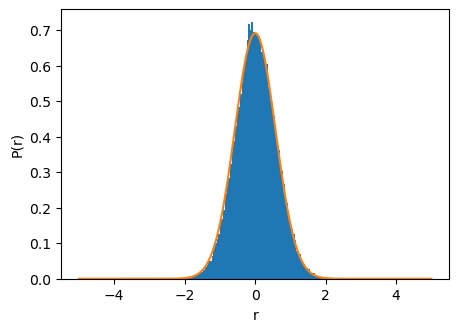

In [3]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

xs = np.linspace(-5, 5, 500)
var = sim.kB * sim.T_bath / k       # OU stationary variance for F = -k r
dist = np.exp(-xs**2/(2*var)) / np.sqrt(2*np.pi*var)

# discard burn-in (a few relaxation times tau_relax = gamma/k)
burn = int(5 * gamma / k / sim.dt)
ax.hist(sim.r[burn:,0,0].flatten(), bins=100, density=True)
# ax.hist(sim.r[-1,0,:].flatten(), bins=100, density=True)
ax.plot(xs, dist)
ax.set_xlabel("r"); ax.set_ylabel("P(r)")
print("empirical Var(r) =", sim.r[burn:,0,0].var(), "  expected =", var)

### A simple potential with well and barrier 

In [72]:
# Double-well potential: 1/(100|r|) keeps r > 0, Gaussian creates the barrier,
# 0.01 r^2 confines at large r.
args = (100, 1.0, 0.48, 0.01)


left well  : r=0.010, U=0.360, ω_well=0.896
barrier    : r=1.009,  U=1.010,  ω_bar =1.436
ΔU = 0.650


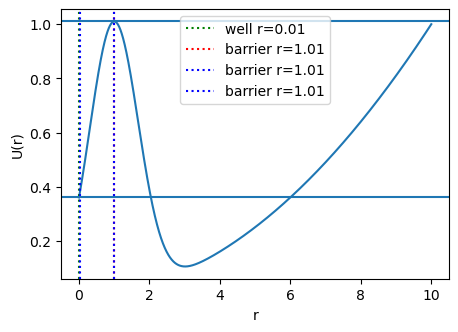

In [73]:
def U(x, *args):
    a, b, c, d = args
    # return 1.0 / np.abs(a * x) + np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2
    return np.exp(-(x - b) ** 2 / (2 * c)) + d * x ** 2


def F(x, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    a, b, c, d = args
    # return 1.0 / (a * x ** 2) + (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x
    return (x - b) / c * np.exp(-(x - b) ** 2 / (2 * c)) - 2 * d * x


# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(1e-2, 10, 5000)
U_vals = U(xs, *args)

left = xs < 2.0
right = xs > 2.0
i_well = np.argmin(U_vals[left])
i_barrier = (np.argmax(U_vals[left]) if False
             else np.argmax(U_vals * ((xs > xs[left][i_well]) & (xs < 3.5))))

x_well, U_well = xs[left][i_well], U_vals[left][i_well]
x_bar,  U_bar = xs[i_barrier],   U_vals[i_barrier]
dU = U_bar - U_well
x_bar_a = 0.05
x_bar_b = x_bar

# numerical curvatures


def d2U(x):
    h = 1e-5
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h ** 2


omega_well = np.sqrt(d2U(x_well))     # >0
omega_bar = np.sqrt(-d2U(x_bar))      # |U''| at the saddle

print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar,  color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_a,  color="b", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_b,  color="b", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axhline(U_well)
ax.axhline(U_bar)
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.legend()

#### Simulating Langevin under that potential

In [60]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 0.28                    # -> ΔU/T ≈ 4.6 here
gamma  = 0.3
kB     = 1.0

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
relax_well = gamma / d2U(x_well)              # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.01 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
# tau_K = (2 * np.pi * gamma / (omega_well * omega_bar)) * np.exp(dU / (kB * T_bath))

dV_R = -F(0, *args)
tau_K = ((gamma / dV_R) * ((np.sqrt(2*np.pi*kB*T_bath))/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))
tau   = 50 * tau_K
print(f"Kramers mean exit time ≈ {tau_K:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = 0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 1000
nskip = 2
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = lgv.OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=x_well, nskip=nskip,
    r_min=r_min,
    seed=3,
    ab = (x_bar_a, x_bar_b),
)
sim.generate()
print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0015, dt_noise = 0.0077  ->  using dt = 0.0015
Kramers mean exit time ≈ 7.48,  using tau = 374.2
U(r_min)/T = 0.8  (should be >> 1)
n_steps = 257262,  memory ≈ 1029 MB per array
min(r) = 0.01  (should be ≥ r_min)


#### Checking the Boltzmann distribution

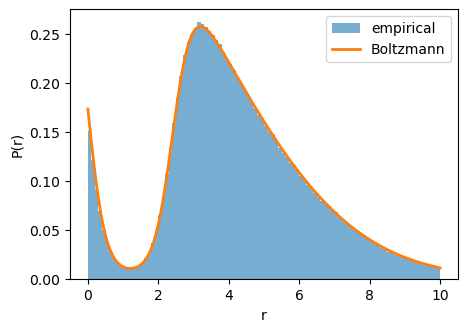

In [56]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)

# samples = r_traj[mask]
samples = r_traj[::100].flatten()

# Boltzmann on the left basin (renormalized over r < x_bar)
xs = np.linspace(1e-2, 10, 5000)
left_mask = xs < x_bar
# P_left = np.exp(-(U_vals - U_well) / T_bath)  * left_mask
# P_left /= np.trapz(P_left, xs)

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / T_bath)
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, 10), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [ ]:
out_dir = "media/figures/20260606"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260606/empirical_vs_boltzmann_for_arbitrary_potential_high_T.pdf


#### Recovering the Kramers exit rate

In [12]:
r_traj = sim.r[:, 0, :]
limit = x_bar
crossed = r_traj > limit
first_exit = np.where(crossed.any(0), crossed.argmax(0), sim.ns)
mask = np.arange(sim.ns)[burn:, None] < first_exit[None, :]

In [61]:
def scalar_reference(positions, a, b):
    positions = np.asarray(positions, dtype=float)
    if positions.ndim == 1:
        positions = positions[:, None]
    n, N = positions.shape
    A_intervals = [[] for _ in range(N)]
    B_intervals = [[] for _ in range(N)]
    in_A = positions[0] <= a
    in_B = positions[0] > a
    A_entry = np.zeros(N)
    B_entry = np.zeros(N)
    for i in range(1, n):
        r = positions[i]
        for k in range(N):
            if r[k] >= b and in_A[k]:
                B_entry[k] = i
                A_intervals[k].append(B_entry[k] - A_entry[k])
                in_A[k] = False
                in_B[k] = True
            if r[k] <= a and in_B[k]:
                A_entry[k] = i
                B_intervals[k].append(A_entry[k] - B_entry[k])
                in_B[k] = False
                in_A[k] = True
    return A_intervals, B_intervals

r_traj = sim.r[:, 0, :]

A_intervals_ref, B_intervals_ref = scalar_reference(r_traj, x_bar_a, x_bar_b)

In [62]:
first_exit_cum = []
first_entry_cum = []

for i in range(sim.N):
    # first_exit_cum = np.concatenate((first_exit_cum, sim.A_intervals[i][10:]))
    # first_entry_cum = np.concatenate((first_entry_cum, sim.B_intervals[i][10:]))

    first_exit_cum = np.concatenate((first_exit_cum, A_intervals_ref[i][1:]))
    first_entry_cum = np.concatenate((first_entry_cum, B_intervals_ref[i][1:]))

empirical rate  k = 1/<T_exit> = 0.3107
Kramers   rate  k             = 0.2672
ratio empirical / Kramers     = 1.16


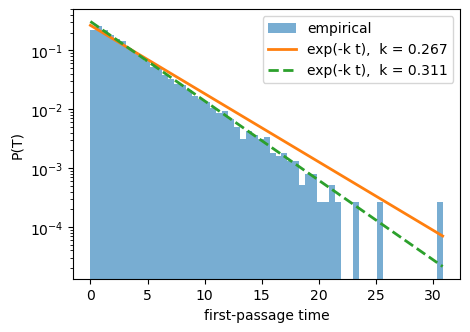

In [63]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] > limit).any(0)
# fpt = first_exit[exited] * sim.dt * sim.nskip
fpt = first_exit_cum * sim.dt * sim.nskip
# print(f"{exited.sum()}/{sim.N} trajectories exited")

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - 0)/ (kB*T_bath))))

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 60)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_kramers:.3f}")
ax.plot(t_grid, k_emp * np.exp(-k_emp * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}", linestyle="dashed")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

### Rouse potential + attractive well

#### Load data

In [424]:
import json, glob
import numpy as np

# _data_dir = "data/20260528/rouse_mfpt_attractive"
# _data_dir = "data/20260611/rouse_mfpt_attractive"
# _data_dir = "data/20260612/rouse_mfpt_attractive"
_data_dir = "data/20260615/rouse_mfpt_attractive"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _cpu_id = list(_raw.keys())[0]
    for _run_id, _run in _raw[_cpu_id].items():
        _alpha = _run["alpha"]
        data[_alpha] = _run

# --- sort alphas ---
alphas = np.array(sorted(data.keys()))
nparams = len(alphas)

# infer params from first entry
_first = data[alphas[0]]
params         = _first["rouse_params"]
nsteps_distance = int(params["nsteps"] / _first["sample_skip"])
# nsteps_full     = params["nsteps_full"]
dt              = params["dt"]

t_grid_distance = np.arange(nsteps_distance) * dt
# t_grid_full     = np.arange(nsteps_full) * dt
nsteps_pot     = len(_first["total_potential"])

# pre-allocate (sizes inferred from first entry)
# _nfpt = len(_first["contact_times"])
# _nicdf = len(_first["inverse_cdf"])
# _nhist = len(_first["hist_centers"])
# _nmsd  = len(_first["msd_bead1"])

distance_traj    = np.empty((nparams, nsteps_distance))
# contact_times    = [None] * nparams   # variable-length per alpha
# inverse_cdf      = [None] * nparams
# hist_centers     = np.empty((nparams, _nhist))
# hist_counts      = np.empty((nparams, _nhist))
# msd_bead1        = np.empty((nparams, _nmsd))
# msd_beadMid      = np.empty((nparams, _nmsd))
# msd_pairDistance = np.empty((nparams, _nmsd))
total_potential    = np.empty((nparams, nsteps_pot))
runtime_min      = np.empty(nparams)

for _ic, _alpha in enumerate(alphas):
    _r = data[_alpha]
    distance_traj[_ic]    = np.array(_r["distance_traj"])
    total_potential[_ic]  = np.array(_r["total_potential"])
    # contact_times[_ic]    = np.array(_r["contact_times"])
    # inverse_cdf[_ic]      = np.array(_r["inverse_cdf"])
    # hist_centers[_ic]     = np.array(_r["hist_centers"])
    # hist_counts[_ic]      = np.array(_r["hist_counts"])
    # msd_bead1[_ic]        = np.array(_r["msd_bead1"])
    # msd_beadMid[_ic]      = np.array(_r["msd_beadMid"])
    # msd_pairDistance[_ic] = np.array(_r["msd_pairDistance"])
    runtime_min[_ic]      = _r["runtime_min"]

In [425]:
from viz_util.bvp_solver import (
    Parameters, d2fb_dphi2, 
)

keya = 10
p_sim = data[alphas[keya]]["surface_params"]

p = Parameters(
    nb=p_sim["nb"],
    chi_b=p_sim["chi_b"],
    omega_b=p_sim["omega_b"],
    kappa=p_sim["kappa"],
    phi_inf=p_sim["phi_inf"],
    L=10.0,
    eps=1e-6,
    R=p_sim["R"],
    conserve_volume=False,
    parallel_plates=False
)

kuhnLength = data[alphas[keya]]["rouse_params"]["kuhn_length"]
beadSep = data[alphas[keya]]["rouse_params"]["bead_separation"]

barrier    : r=3.890,  U=-2.634,  ω_bar =0.959
ΔU = 5.988


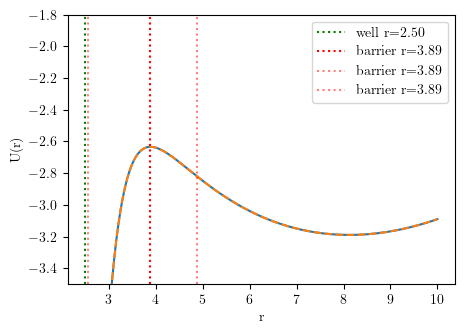

In [426]:
def U(r, *args):
    R, h0, kappa, lam, a, s = args

    # profile = np.where(r >= R, np.exp(-lam*(r-R))*R/r, 1)
    profile = np.exp(-lam*(r-R))*R/r

    return (
        - 2 * np.log(r) + 3*r**2/(2*s*a**2) 
        - 4*np.pi*R**2*h0**2*profile/(kappa*(lam+1/R))
    )

def F(r, *args):
    """Analytic force F = -dU/dx (only valid for x > 0)."""
    R, h0, kappa, lam, a, s = args

    # attrForce = np.where(r >= R, 1, 0)
    attrForce = 1

    return (
        2 / r - 3*r/(s*a**2) 
        - attrForce*4*np.pi*R**3*h0**2*np.exp(-lam*(r-R))*(lam/r+1/r**2)/(kappa*(lam+1/R))
    )

# --- locate left well, barrier; compute ΔU and curvatures ---
xs = np.linspace(p.R, p.L, 500)

lam = np.sqrt(d2fb_dphi2(p.phi_inf, p))
args = (p.R, p.omega_b, p.kappa, lam, kuhnLength, beadSep)
U_vals = U(xs, *args)
U_sim = data[alphas[keya]]["total_potential"]

# left = xs < 10
i_well = np.argmin(U_vals)
x_well, U_well = xs[i_well], U_vals[i_well]

# Barrier = first zero-crossing of dU/dx past the well.
# At a maximum the force F = -dU/dx flips from - to +; the first sign change
# of F (scanning outward from the well) marks the ridge between the two wells.
F_vals = F(xs, *args)
after_well = xs > x_well
sign_change = (np.sign(F_vals[after_well][:-1]) < 0) & (np.sign(F_vals[after_well][1:]) > 0)
i_cross = np.argmax(sign_change)  # first True; argmax stops at the first one
assert sign_change.any(), "no F-sign-change found past the well — barrier not located"

# linear interpolation between the bracketing samples for a sub-grid root
x_lo = xs[after_well][i_cross]
x_hi = xs[after_well][i_cross + 1]
F_lo, F_hi = F_vals[after_well][i_cross], F_vals[after_well][i_cross + 1]
x_bar = x_lo - F_lo * (x_hi - x_lo) / (F_hi - F_lo)
eps = 0.2
x_bar_a = p.R + 0.05
x_bar_b = x_bar+1
U_bar = U(x_bar, *args)

dU = U_bar - U_well

# numerical curvatures
def d2U(x):
    h = 1e-3
    return (U(x + h, *args) - 2 * U(x, *args) + U(x - h, *args)) / h**2

# omega_well = np.sqrt(d2U(x_well))  # >0
omega_bar = np.sqrt(-d2U(x_bar))  # |U''| at the saddle

# print(f"left well  : r={x_well:.3f}, U={U_well:.3f}, ω_well={omega_well:.3f}")
print(f"barrier    : r={x_bar:.3f},  U={U_bar:.3f},  ω_bar ={omega_bar:.3f}")
print(f"ΔU = {dU:.3f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.plot(xs, U_vals)
ax.plot(xs, U_sim, linestyle="dashed")
ax.axvline(x_well, color="g", ls=":", label=f"well r={x_well:.2f}")
ax.axvline(x_bar, color="r", ls=":", label=f"barrier r={x_bar:.2f}")
ax.axvline(x_bar_a, color="r", ls=":", label=f"barrier r={x_bar:.2f}", alpha=0.5)
ax.axvline(x_bar_b, color="r", ls=":", label=f"barrier r={x_bar:.2f}", alpha=0.5)
ax.set_xlabel("r")
ax.set_ylabel("U(r)")
ax.set_ylim(-3.5, -1.8)
ax.legend()

In [358]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_attr_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_attr_potential.pdf


#### Simulating Langevin

In [92]:
# --- parameter selection -------------------------------------------------
# 1) Temperature: ΔU/(kBT) in [3, 7] is the Arrhenius sweet spot --- escape
#    is rare enough to be exponentially distributed, frequent enough to
#    collect statistics in reasonable wall-clock time.
T_bath = 1.5                    # -> ΔU/T ≈ 4.6 here
gamma  = 1.0
kB     = 1.0
D = kB*T_bath/gamma

# 2) Time step: needs to satisfy BOTH
#       dt < (1/10) * γ / max|U''|         (drift stability)
#       √(2 kBT/γ * dt) << min feature size (noise step << well width)
dV_R = -F(p.R, *args)
relax_well = gamma*kB*T_bath / dV_R**2             # γ / U''(well)
relax_bar  = gamma / abs(d2U(x_bar))          # γ / |U''(barrier)|
dt_drift   = 0.05 * min(relax_well, relax_bar)
noise_step_target = 0.1 * (x_bar - x_well)    # << 1/10 of well-to-barrier distance
dt_noise   = noise_step_target ** 2 / (2 * kB * T_bath / gamma)
dt         = min(dt_drift, dt_noise)
print(f"dt_drift = {dt_drift:.4f}, dt_noise = {dt_noise:.4f}  ->  using dt = {dt:.4f}")

# 3) Total time: a few mean Kramers escape times so we observe many exits.
omega_bot = np.sqrt(d2U(8))
dU_bot = U(x_bar, *args) - U(8, *args)
tau_bot = (2 * np.pi * gamma / (omega_bot * omega_bar)) * np.exp(dU_bot / (kB * T_bath))

tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kB*T_bath)/omega_bar) 
         * np.exp(dU / (kB*T_bath)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kB*T_bath))))
tau   = 500 * tau_K

print("delta_1^2: ", 1/omega_bot**2)
print(f"Kramers mean exit time from entropic well ≈ {tau_bot:.2f},  using tau = {tau:.1f}")

# 4) Reflecting wall well clear of the 1/r singularity, but where U(r_min) is
#    so high that the equilibrium weight there is negligible (~ exp(-U/T)).
r_min = p.R+0.01
print(f"U(r_min)/T = {U(r_min, *args)/T_bath:.1f}  (should be >> 1)")

# 5) Number of trajectories — limited by RAM: shape (n, dim, N).
N = 5000
nskip = 10
print(f"n_steps = {int(tau/dt)},  memory ≈ {int(tau/dt)*N*8/1e6/nskip:.0f} MB per array")

sim = lgv.OverdampedHarmonicLangevin(
    tau=tau, dim=1, N=N, dt=dt,
    T=T_bath, gamma=gamma, kB=kB,
    F=lambda r: F(r, *args),
    r0=p.R,
    r_min=r_min,
    seed=42,
    nskip=nskip,
    ab = (x_bar_a, x_bar_b)
)
sim.generate()

print("min(r) =", sim.r.min(), " (should be ≥ r_min)")

dt_drift = 0.0002, dt_noise = 0.0064  ->  using dt = 0.0002
delta_1^2:  16.251405127689324
Kramers mean exit time from entropic well ≈ 38.23,  using tau = 4582.9
U(r_min)/T = -5.6  (should be >> 1)
n_steps = 21852322,  memory ≈ 87409 MB per array


MemoryError: Unable to allocate 81.4 GiB for an array with shape (2185233, 1, 5000) and data type float64

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


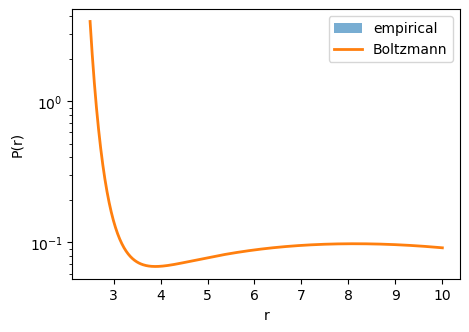

In [91]:
# --- Boltzmann sampling check -----------------------------
burn = int(0.2 * sim.ns)
r_traj = sim.r[burn:, 0, :]                          # shape (n, N)
samples = r_traj.flatten()

# Boltzmann on the whole support
P_full = np.exp(-(U_vals - U_well) / (kB*T_bath))
P_full /= np.trapz(P_full, xs)

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
ax.hist(samples, bins=100, density=True, range=(r_min, p.L), alpha=0.6,
        label="empirical")
ax.plot(xs, P_full, lw=2, label="Boltzmann")
ax.set_yscale('log')
ax.set_xlabel("r"); ax.set_ylabel("P(r)"); ax.legend()

In [109]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_boltzmann_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_boltzmann_langevin.pdf


#### Kramers exit rate (Langevin)

In [ ]:
# r_traj = sim.r[:, 0, :]
# limit = x_bar
# crossed = r_traj > limit
# first_exit = np.where(crossed.any(0), crossed.argmax(0), len(r_traj))
# mask = np.arange(len(r_traj))[burn:, None] < first_exit[None, :]

In [89]:
first_exit_cum = []
first_entry_cum = []

for i in range(sim.N):
    first_exit_cum = np.concatenate((first_exit_cum, sim.A_intervals[i][1:]))
    first_entry_cum = np.concatenate((first_entry_cum, sim.B_intervals[i][1:]))

empirical rate  k = 1/<T_exit> = nan
Kramers   rate  k             = 0.1091
ratio empirical / Kramers     = nan


/tmp/ipykernel_257284/1303255116.py:9: RuntimeWarning: Mean of empty slice.
  mean_fpt = fpt.mean()
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: zero-size array to reduction operation maximum which has no identity

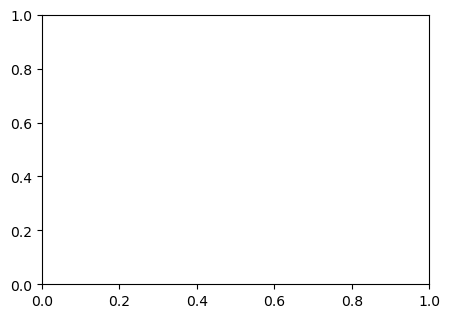

In [90]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] < limit).any(0)
# fpt = first_exit[exited] * sim.dt * sim.nskip
fpt = first_exit_cum * sim.dt
# print(f"{exited.sum()}/{sim.N} trajectories exited")

D = (kB * T_bath) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 1.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")
# ax.set_xscale("log")

In [115]:
out_dir = "media/figures/20260612"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_exit_rate_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260612/rouse_exit_rate_langevin.pdf


#### Distance trace

nsteps:  100000
total physical time:  50.0
bead relaxation time:  0.3333333333333333


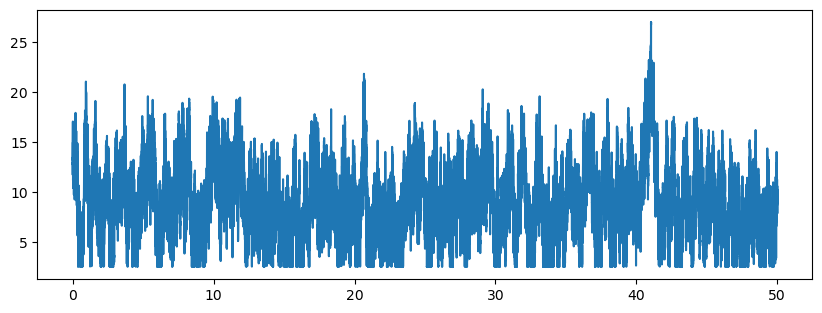

In [11]:
fig, ax = plt.subplots(1,1,figsize=(10, 3.5))

ax.plot(t_grid_distance, distance_traj[1])
print("nsteps: ", nsteps_distance)
print("total physical time: ", dt*nsteps_distance)
print("bead relaxation time: ", _first["bead_relax_time"])
# ax.set_xlim(10, 200)

#### Distance hist

0.0912


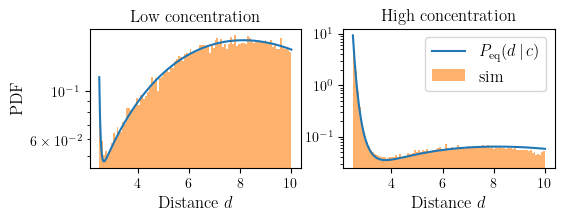

In [495]:
fig, ax = plt.subplots(1,2,figsize=(6.0, 1.8))

keya = 0
b = _first["rouse_params"]["kuhn_length"]
R = _first["surface_params"]["R"]
kBT = _first["rouse_params"]["kBT"]
subsampled = distance_traj[keya]

N = _first["rouse_params"]["N"]

pot = total_potential[keya]
xs2 = np.linspace(p.R, p.L, len(pot))
P_eq = np.exp(-pot/kBT)
P_eq /= np.trapz(P_eq, xs2)

ax[0].plot(xs, P_eq, label="theory")
ax[0].hist(subsampled, density=True, bins=100, range=(p.R, p.L), alpha=0.6, label="sim")
ax[0].set_xlabel(r"Distance $d$", fontsize=12)
ax[0].set_ylabel(r"PDF", fontsize=12)
ax[0].set_yscale('log')
ax[0].set_title("Low concentration")

keya = 9
subsampled = distance_traj[keya]
pot = total_potential[keya]
xs2 = np.linspace(p.R, p.L, len(pot))
P_eq = np.exp(-pot/kBT)
P_eq /= np.trapz(P_eq, xs2)

ax[1].plot(xs, P_eq, label=r"$P_{\rm{eq}}(d\,|\, c)$")
ax[1].hist(subsampled, density=True, bins=100, range=(p.R, p.L), alpha=0.6, label="sim")
ax[1].set_xlabel(r"Distance $d$", fontsize=12)
ax[1].legend(fontsize=12)
ax[1].set_title("High concentration")
ax[1].set_yscale('log')

print(alphas[keya])


In [355]:
_first["surface_params"]

{'chi_b': 2.5,
 'omega_b': -0.5,
 'kappa': 1.0,
 'phi_inf': 0.003,
 'R': 2.5,
 'nb': 1.0}

In [496]:
out_dir = "media/figures/20260727"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rouse_distance_distribution_lowc_hic.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260727/rouse_distance_distribution_lowc_hic.pdf


#### Kramers exit rate (Rouse)

In [18]:
dt = data[alphas[keya]]["rouse_params"]["dt"]
nskip = data[alphas[keya]]["sample_skip"]
kBT = data[alphas[keya]]["rouse_params"]["kBT"]
gamma = data[alphas[keya]]["rouse_params"]["friction"]

T_bath = kBT

dV_R = -F(p.R, *args)
tau_K = ((gamma / dV_R) * (np.sqrt(2*np.pi*kBT)/omega_bar) 
         * np.exp(dU / (kBT)) * (1 - np.exp(-dV_R * (x_bar - p.R)/ (kBT))))
tau   = 500 * tau_K

In [19]:
r_traj = distance_traj[::1]

a = p.R + 0.05
b = x_bar
a_crossings = []
b_crossings = []
ab_intervals = []
ba_intervals = []
in_a = False
in_b = False
entered_a, entered_b, exited_a, exited_b = None, None, None, None

for i, xi in enumerate(r_traj):
    if xi < a and not in_a:
        in_a = True
        entered_a = i
        if exited_b is not None:
            ab_intervals.append(entered_a - exited_b)

    if xi > a and r_traj[i-1] <= a:
        in_a = False
        exited_a = i

    if xi > b and not in_b:
        in_b = True
        entered_b = i
        if exited_a is not None:
            ba_intervals.append(entered_b - exited_a)

    if xi < b and r_traj[i-1] >= b:
        in_b = False
        exited_b = i

first_exit = np.array(ab_intervals)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [20]:
# --- Exit-time distribution and Arrhenius rate ---------------------------
# First-passage time to cross the barrier crest for each trajectory.
# exited = (sim.r[:, 0, :] > limit).any(0)
exited = (subsampled > limit).any(0)

fpt = first_exit * dt * nskip * 10
print(f"{exited.sum()}/{1} trajectories exited")

D = (kBT) / gamma
mean_fpt = fpt.mean()
k_emp    = 1.0 / mean_fpt
k_kramers = 2.0 / tau_K
print(f"empirical rate  k = 1/<T_exit> = {k_emp:.4f}")
print(f"Kramers   rate  k             = {k_kramers:.4f}")
print(f"ratio empirical / Kramers     = {k_emp / k_kramers:.2f}")

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
bins = np.linspace(0, fpt.max(), 40)
ax.hist(fpt, bins=bins, density=True, alpha=0.6, label="empirical")
t_grid = np.linspace(0, fpt.max(), 200)
ax.plot(t_grid, k_kramers * np.exp(-k_kramers * t_grid), lw=2,
        label=f"exp(-k t),  k = {k_emp:.3f}")
ax.set_xlabel("first-passage time"); ax.set_ylabel("P(T)"); ax.legend()
ax.set_yscale("log")

NameError: name 'limit' is not defined

### Mean-squared displacement

Text(0.5, 1.0, 'single locus')

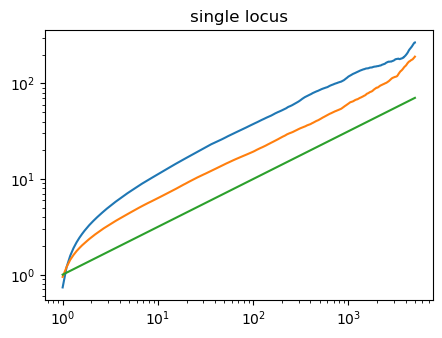

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_bead1[0])
_=ax.plot(msd_time, msd_beadMid[0])
ax.plot(msd_time, msd_time**0.5)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("single locus")

Text(0.5, 1.0, 'two locus')

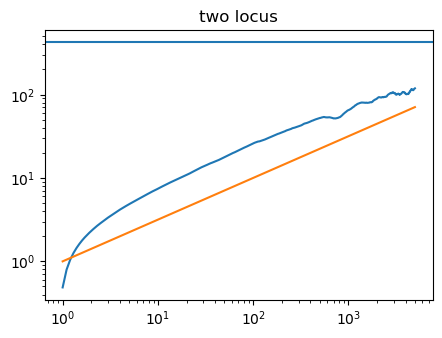

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))
maxlag = dt*len(msd_bead1[0])
msd_time = np.linspace(1, maxlag, len(msd_bead1[0]))
_=ax.plot(msd_time, msd_pairDistance[0])
ax.plot(msd_time, msd_time**0.5)
ax.axhline(y=np.mean(distance_traj**2))
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_title("two locus")

### Quick look at Fisher rates

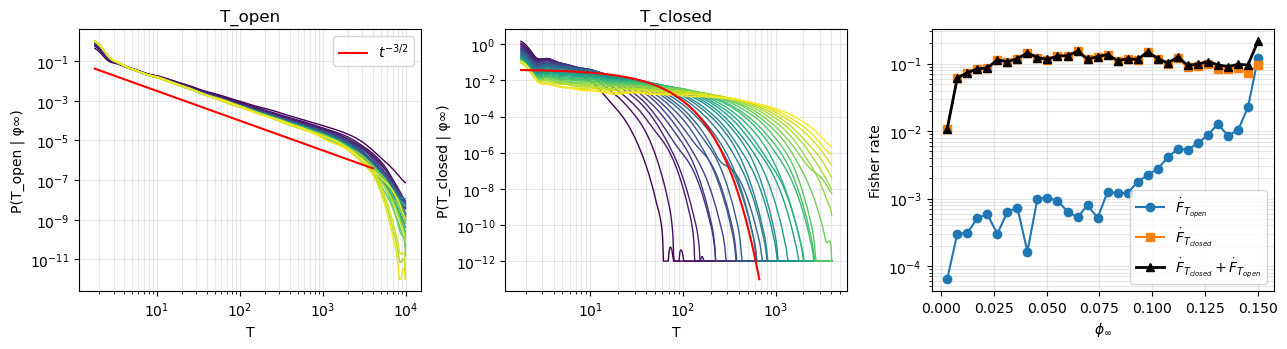

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

PATH = "media/figures/20260528/rouse_mfpt_attractive_fisher_hires.json"

with open(PATH) as f:
    blob = json.load(f)

# scalars / arrays indexed by phi_inf
phi_inf    = np.asarray(blob["phi_inf"], dtype=float)
d_ridge    = np.asarray(blob["d_ridge"], dtype=float)
joint_rate = np.asarray(blob["joint_rate"], dtype=float)

# helper: JSON-encoded arrays may contain `None` where the analysis produced
# a NaN (empty histogram bin, log of 0, etc.). Cast back to NaN for math.
def arr(x):
    return np.asarray(x, dtype=float)   # None -> NaN automatically

def unpack(group):
    return dict(
        T_grid           = arr(group["T_grid"]),            # (n_T,)
        pdfs             = arr(group["pdfs"]),              # (n_phi, n_T)
        mean_T           = arr(group["mean_T"]),            # (n_phi,)
        fisher_per_event = arr(group["fisher_per_event"]),  # (n_phi,) wrt log phi
        fisher_rate      = arr(group["fisher_rate"]),       # (n_phi,) per unit time
    )

open_  = unpack(blob["open"])
closed = unpack(blob["closed"])

# ---- quick sanity plots --------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
cmap = plt.get_cmap("viridis")

for name, g in [("T_open", open_), ("T_closed", closed)]:
    ax = axes[0] if name == "T_open" else axes[1]
    for i in range(len(phi_inf)):
        if not np.all(np.isnan(g["pdfs"][i])):
            ax.loglog(g["T_grid"], np.clip(g["pdfs"][i], 1e-12, None),
                      color=cmap(i / max(1, len(phi_inf) - 1)), lw=1.0)
    ax.set_xlabel("T"); ax.set_ylabel(f"P({name} | φ∞)")
    ax.set_title(name); ax.grid(True, which="both", alpha=0.3)

lam = 0.04
stop=int(len(g["T_grid"]) / 1.3)
axes[0].plot(g["T_grid"], g["T_grid"]**(-3/2)*0.1, color="red", label=r"$t^{-3/2}$")
axes[0].legend()
axes[1].plot(g["T_grid"][:stop], lam*np.exp(-g["T_grid"][:stop]*lam), color="red")

ax = axes[2]
ax.plot(phi_inf, open_["fisher_rate"],   "o-", label=r"$\dot F_{T_{open}}$")
ax.plot(phi_inf, closed["fisher_rate"],  "s-", label=r"$\dot F_{T_{closed}}$")
ax.plot(phi_inf, joint_rate,             "^-", color="k", lw=2, label=r"$\dot F_{T_{closed}}+\dot F_{T_{open}}$")
ax.set_xlabel(r"$\phi_\infty$"); ax.set_ylabel("Fisher rate")
ax.set_yscale("log"); ax.legend(); ax.grid(True, which="both", alpha=0.3)

plt.tight_layout(); plt.show()

In [ ]:
out_dir = "media/figures/20260528"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fpt_pdfs_open_close_fisher_rates.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260528/fpt_pdfs_open_close_fisher_rates.pdf


### Fisher rate, Langevin dynamics

#### Load Langevin data

In [431]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "data/20260627/langevin_open_close_exit_at_bar"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _keyas = list(_raw.keys())
    for _keya in _keyas:
        for _run_id, _run in _raw[_keya]["1"].items():
            keya = _run["keya"]
            data[keya] = _run

#### Checking equilibration

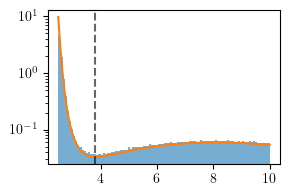

In [458]:
fig, ax = plt.subplots(1,1,figsize=(3, 2))

keya = 30

U_vals      = np.array(data[keya]["total_potential"])
xs          = np.array(data[keya]["pot_grid"])
T_bath      = data[keya]["langevin_params"]["T_bath"]
kB          = data[keya]["langevin_params"]["kB"]
kBT         = kB*T_bath
x_bar       = data[keya]["x_bar"]

P_full = np.exp(-(U_vals) / (kBT))
P_full /= np.trapz(P_full, xs)

bot = np.min(P_full)
height = np.max(P_full)/np.min(P_full)

ax.hist(data[keya]["distance_traj"], density=True, bins=100, 
          range=(xs[0], xs[-1]), alpha=0.6)
ax.plot(xs, P_full)
ax.axvline(x=x_bar, linestyle="dashed", color="black", alpha=0.6)
# ax.text(x_bar-1.14, bot*height**1.1, "closed", fontsize=12)
# ax.text(x_bar+0.4, bot*height**1.1, "open", fontsize=12)
ax.set_yscale("log")

In [26]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "langevin_P_eq_ok_lowc.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/langevin_P_eq_ok_lowc.pdf


#### Checking entry/exit time histograms

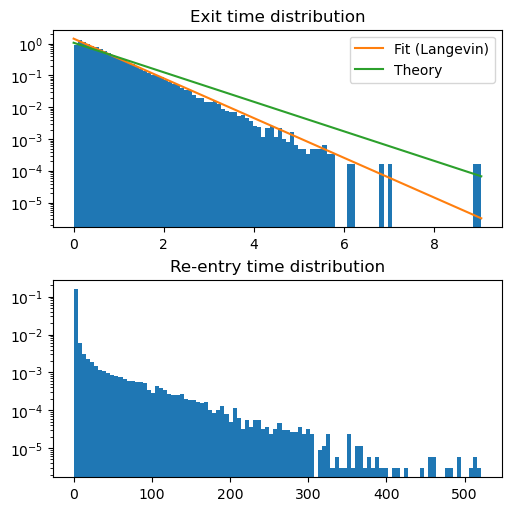

In [42]:
keya = 10

exit_times = data[keya]["exit_times"]
reentry_times = data[keya]["reentry_times"]
k_exit = data[keya]["k_exit"]
k_kramers = 2*data[keya]["k_kramers"]
k_reentry = data[keya]["k_reentry"]

fig, ax = plt.subplots(2,1,figsize=(5, 5), layout="constrained")

exit_grid = np.linspace(0, np.max(exit_times), 100)
ax[0].hist(exit_times, bins=100, density=True)
ax[0].set_yscale('log')
ax[0].plot(exit_grid, k_exit*np.exp(-k_exit*exit_grid), 
           label="Fit (Langevin)")
ax[0].plot(exit_grid, k_kramers*np.exp(-k_kramers*exit_grid),
           label="Theory")
ax[0].set_title("Exit time distribution")
ax[0].legend()

ax[1].set_title("Re-entry time distribution")
entry_grid = np.linspace(0, 300, 100)
ax[1].hist(reentry_times, bins=100, density=True)
ax[1].set_yscale('log')
# ax[1].set_xscale('log')
# ax[1].plot(entry_grid, k_reentry*np.exp(-k_reentry*entry_grid))

In [43]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "exit_reentry_dists.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/exit_reentry_dists.pdf


#### Exit rate and re-entry time

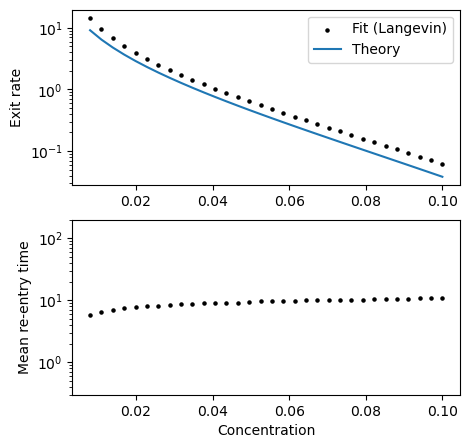

In [48]:
keyas = np.sort(list(data.keys()))

concentrations = np.array([data[keya]["alpha"] for keya in keyas])
k_exit_vals =  np.array([data[keya]["k_exit"] for keya in keyas])
k_kramers_vals =  np.array([data[keya]["k_kramers"] for keya in keyas])
mean_exit_time_vals =  1/k_exit_vals
mean_reentry_time_vals =  np.array([data[keya]["mean_reentry_time"] for keya in keyas])
mean_cycle_time_vals = mean_exit_time_vals + mean_reentry_time_vals

fig, ax = plt.subplots(2,1,figsize=(5, 5))

ax[0].scatter(concentrations, k_exit_vals, s=20, marker=".",c="black", label="Fit (Langevin)")
ax[0].plot(concentrations, 2*k_kramers_vals, label="Theory")
ax[0].set_ylabel("Exit rate")
ax[0].set_yscale("log")
ax[0].legend()

ax[1].scatter(concentrations, mean_reentry_time_vals, s=20, marker=".",c="black")
ax[1].set_ylabel("Mean re-entry time")
ax[1].set_xlabel("Concentration")
ax[1].set_ylim(0.3, 200)
ax[1].set_yscale('log')

In [45]:
out_dir = "media/figures/20260628"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "rates_vs_c.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260628/rates_vs_c.pdf


#### Local concentration and transcription dynamics

In [3]:
phi_local_vals = np.zeros(len(keyas))
p_closed_vals = np.zeros(len(keyas))

def U(r, *args):
    R, h0, kappa, lam, a, s = args
    profile = np.exp(-lam * (r - R)) * R / r

    return (
        - 2 * np.log(r) + 3 * r ** 2 / (2 * s * a ** 2)
        - 4 * np.pi * R ** 2 * h0 ** 2 * profile / (kappa * (lam + 1 / R))
    )

for k, keya in enumerate(keyas):

    # U_vals      = np.array(data[keya]["total_potential"])
    # xs          = np.array(data[keya]["pot_grid"])
    T_bath      = data[keya]["langevin_params"]["T_bath"]
    kB          = data[keya]["langevin_params"]["kB"]
    kBT         = kB*T_bath
    x_bar       = data[keya]["x_bar"]
    lam         = data[keya]["lam"]
    R           = data[keya]["R"]
    L           = data[keya]["surface_params"]["L"]
    kuhnLength  = data[keya]["rouse_params"]["kuhn_length"]
    beadSep     = data[keya]["rouse_params"]["bead_separation"]
    kappa       = data[keya]["surface_params"]["kappa"]
    omega_b     = data[keya]["surface_params"]["omega_b"]
    phi_inf     = data[keya]["alpha"]
    
    args = (R, omega_b, kappa, lam, kuhnLength, beadSep)
    xs = np.linspace(R, L, 100000)
    U_vals = U(xs, *args)

    P_full = np.exp(-(U_vals) / (kBT))
    P_full /= np.trapz(P_full, xs)

    i_closed = np.where(xs < x_bar)[0]
    p_closed = np.trapz(P_full[i_closed], xs[i_closed])
    p_closed_vals[k] = p_closed

    profile = (phi_inf - omega_b * (np.exp(-lam * (xs - R)) * R / xs) 
                / (kappa * (lam + 1 / R)))
    phi_local_vals[k] = np.trapz(P_full[i_closed]*profile[i_closed]/p_closed, 
                        xs[i_closed])
    
# steady-state transcription model
kb = 1.0
ku = 1.0
tau_on_vals = 1 / (phi_local_vals*kb + k_exit_vals)
tau_off_vals = 1 / (ku + k_exit_vals)
tau_closed_vals = tau_on_vals + tau_off_vals
p_on_vals = p_closed_vals * tau_on_vals / tau_closed_vals
p_off_vals = p_closed_vals * tau_off_vals / tau_closed_vals

p_off_to_open_vals = k_exit_vals / (k_exit_vals + phi_local_vals*kb)
p_on_to_open_vals = k_exit_vals / (k_exit_vals + ku)

fig, ax = plt.subplots(2,1, figsize=(5, 5))

ax[0].plot(concentrations, phi_local_vals)
ax[0].plot(concentrations, concentrations, linestyle="dashed", 
        color="black", alpha=0.6)
ax[0].set_ylabel("Local concentration")
ax[0].set_ylabel("Concentration")

ax[1].plot(concentrations, p_closed_vals)
ax[1].plot(concentrations, mean_exit_time_vals / mean_cycle_time_vals)

NameError: name 'keyas' is not defined

#### Log derivatives and Fisher rate

Text(0.5, 0, 'Concentration')

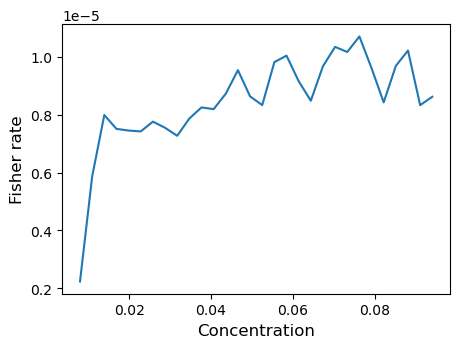

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

# exit rate
k_vals = k_exit_vals
d_exit_vals = np.gradient(k_vals)
d2_exit_vals = np.gradient(np.gradient(k_vals))
d2_log_exit_vals = d2_exit_vals/k_vals - (d_exit_vals/k_vals)**2

# local concentration
d_phi_local_vals = np.gradient(phi_local_vals)
d2_phi_local_vals = np.gradient(np.gradient(phi_local_vals))
d2_log_phi_local_vals = (d2_phi_local_vals/phi_local_vals 
                         - (d_phi_local_vals/phi_local_vals)**2)

# shorthands
c = concentrations
p4 = p_off_vals
p41 = p_off_to_open_vals
p3 = p_on_vals
p31 = p_on_to_open_vals

# fisher rate
fisher_rate_vals = (
    c**2*(d2_exit_vals*p_closed_vals + d2_phi_local_vals*p_off_vals
          -((p4*p41 + p3+p31)*d2_log_exit_vals
            + p4*p41*d2_log_phi_local_vals)/mean_cycle_time_vals)
)

ax.plot(concentrations[:-2], fisher_rate_vals[:-2])
ax.set_ylabel("Fisher rate", fontsize=12)
ax.set_xlabel("Concentration", fontsize=12)

### Fisher rate, Rouse dynamics

#### Take a look at the potentials

In [4]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "/home/tohme/.julia/dev/Droplet/media/figures/"
_data_dir += "20260628/fisher_two_spheres_chi_2.5_h0_-0.5_R_5.0_sweep_c.json"

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
with open(_data_dir, 'r') as _f:
    data = json.load(_f)

U_grids = np.array(data["groups"][0]["U_full_grid"])
d_grid = np.array(data["groups"][0]["d_grid"])

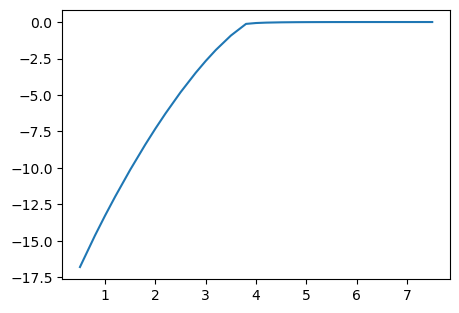

In [5]:
from scipy.interpolate import make_interp_spline

fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

key = 30
U_interp = make_interp_spline(
    d_grid[1:], 
    U_grids[key][1:],
    k=5
)

xs = np.linspace(d_grid[0], d_grid[-1], 500)
ax.plot(d_grid, U_grids[key])
# ax.plot(xs, -U_interp(xs), linestyle="dashed")
# ax.set_yscale("log")

#### Load Rouse data

In [319]:
import json, glob
import numpy as np

# _data_dir = "data/20260627/langevin_open_close_test"
_data_dir = "data/20260629/rouse_mfpt_attractive_nonlinear_test"
_files = sorted(glob.glob(f"{_data_dir}/output_cpu*.json"))

# --- first pass: collect raw dicts keyed by alpha ---
data = {}
for _path in _files:
    with open(_path, 'r') as _f:
        _raw = json.load(_f)
    _keyas = list(_raw.keys())
    for _keya in _keyas:
        for _run_id, _run in _raw[_keya].items():
            data[int(_keya)-1] = _run

keya = 3
r_traj = np.array(data[keya]['distance_traj'])
U_total = np.array(data[keya]['total_potential'])
U_ads = np.array(data[keya]['ads_potential'])
kBT = data[keya]['rouse_params']["kBT"]
R = data[keya]['surface_params']["R"]
L = data[keya]['surface_params']["L"]

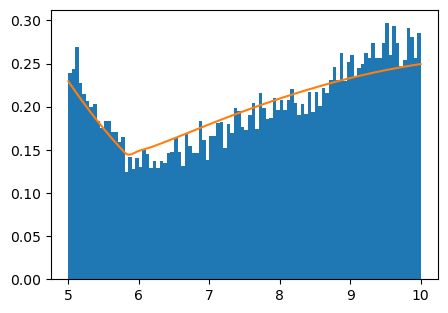

In [320]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))

xs = np.linspace(R, L, len(U_total))
P_full = np.exp(-U_total / kBT)
P_full /= np.trapz(P_full, xs)

ax.hist(r_traj, bins=100, density=True, range=(5, 10))
ax.plot(xs, P_full)

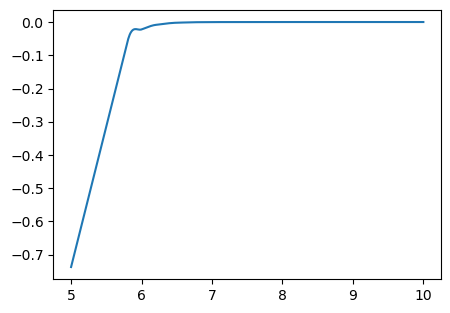

In [321]:
fig, ax = plt.subplots(1,1,figsize=(5, 3.5))

ax.plot(xs, U_ads)
# ax.plot(d_grid[1:]+R, U_grids[0][1:])


### Two sphere BVP solution

In [14]:
import glob, json, os
import numpy as np

# DATA_DIR = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5"   # <-- point at your sweep's outdir
# DATA_DIR = "data/20260721/test"
# DATA_DIR = "data/20260722/fisher_two_spheres_R_4_h0_-0.5_chi_3"
# DATA_DIR = "data/20260722/fisher_two_spheres_chi_3_h0_-0.5_R_4"
# DATA_DIR = "data/20260724/R_4_h0_-1.0_chi_3/"
# DATA_DIR = "data/20260724/R_4_h0_-1.6_chi_4/"
# DATA_DIR = "data/20260724/R_4_h0_-0.6_chi_2.5/"
# DATA_DIR = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/"
# DATA_DIR = "data/20260724/R_5_h0_-0.6_chi_2.5/"
# DATA_DIR = "data/20260725/R_5_h0_-0.55_chi_2.5/"   # first smooth
# DATA_DIR = "data/20260725/R_5_h0_-0.6_chi_2.5_v2/"
# DATA_DIR = "data/20260727/R_5_h0_-0.9_chi_2.8/"
# DATA_DIR = "data/20260727/R_5_h0_-1.0_chi_3/"
# DATA_DIR = "data/20260728/R_5_h0_-0.4_chi_2.8/"
# DATA_DIR = "data/20260728/R_5_h0_-0.4_chi_2.8_hires/"
DATA_DIR = "data/20260728/R_5_h0_-0.5_chi_2.8/"

def load_fisher(data_dir):
    """Aggregate output_cpu*.json from a fisher_two_spheres sweep into a flat record list."""
    recs = []
    def descend(node):                        # sweep.jl nests as {keya: {keyb: record}}
        if isinstance(node, dict):
            if "phi_inf" in node and "U_full" in node:
                recs.append(node)
            else:
                for v in node.values(): descend(v)
        elif isinstance(node, list):
            for v in node: descend(v)
    files = sorted(glob.glob(os.path.join(data_dir, "output_cpu*.json")))
    assert files, f"no output_cpu*.json under {data_dir}"
    for f in files:
        with open(f) as fh: descend(json.load(fh))
    recs.sort(key=lambda r: (r["omega_b"], r["phi_inf"]))   # phi_inf ascending per omega_b
    return recs

records = load_fisher(DATA_DIR)
print(f"{len(records)} records | params sections:", list(records[0].get("params", {})))

32 records | params sections: ['sim', 'fpt', 'bvp', 'surface', 'sweep', 'rouse']


#### Quick look at the potentials

0.09273573439374971
0.0584833421741228


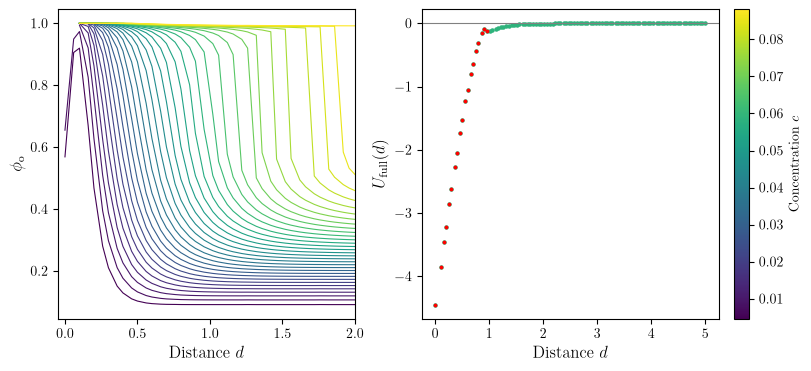

In [105]:
import matplotlib.pyplot as plt
arr = lambda x: np.array(x, dtype=float)      # Julia NaN/null -> np.nan

phi_inf = arr([r["phi_inf"] for r in records])
phi_surf   = arr([r["phi_surf"]   for r in records])
omega_b   = arr([r["omega_b"]   for r in records])
branch = arr([r["branch"]])
print(records[0]["binodal"])

fig, ax = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")

j, k = 0, 15
norm = plt.Normalize(vmin=phi_inf.min(), vmax=phi_inf.max())
cmap = mpl.cm.viridis
r = records[k]                          # equilibrium pair potential U_full(d)

for k, r in enumerate(records):
    if k % 1 == 0:
        c = cmap(norm(phi_inf[k]))
        ax[0].plot(arr(r["d_grid"]), r["phi_surf"], lw=0.8, color=c)

ax[0].set_xlabel(r"Distance $d$", fontsize=12)
ax[0].set_ylabel(r"$\phi_{\rm o}$", fontsize=12)
ax[0].set_xlim(-0.05, 2)

for k, r in enumerate(records):
    if k % 1 == 0 and k == 20:
        c = cmap(norm(phi_inf[k]))
        d_grid = arr(r["d_grid"])
        U_full = arr(r["U_full"])
        U_bridged = arr(r["U_bridged"])
        U_unbridged = arr(r["U_unbridged"])
        ax[1].scatter(d_grid, U_full, color=c, s=5)
        ax[1].scatter(d_grid, U_bridged, s=3, color="red")
        # ax[1].scatter(d_grid, U_unbridged, color="blue", s=5)
        # ax[1].plot(d_grid, np.gradient(U_full, d_grid), ms=3)
        print(phi_inf[k])

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label=r"Concentration $c$")
ax[1].axhline(0, lw=0.8, color="gray")

ax[1].set_xlabel(r"Distance $d$", fontsize=12)
ax[1].set_ylabel(r"$U_{\rm full}(d)$", fontsize=12); 
# ax[1].set_xlim(-0.1, 2.8)
plt.show()
# phi_inf[k]

In [665]:
out_dir = "media/figures/20260728"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "profiles_potentials_2.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260728/profiles_potentials_2.pdf


### Two sphere BVP ($d$-major)

#### Picking Rouse params

In [301]:
ss = [150]
aa = [0.3, 6]
Ds = [3, 60]

for s in ss:
    for a in aa:
        for D in Ds:
            dU = (-2*np.log(D/(2*a*np.sqrt(2*s/3*np.pi)))
                +3*(8*s*a**2/(3*np.pi)-D**2)/(2*s*a**2))
            print("s:", s, "  a:", a, "  R:", D/2, r"  dU:", dU)

s: 150   a: 0.3   R: 1.5   dU: 2.8042637917044533
s: 150   a: 0.3   R: 30.0   dU: -402.1872007554035
s: 150   a: 6   R: 1.5   dU: 9.793228338812435
s: 150   a: 6   R: 30.0   dU: 2.8042637917044533


#### Loading data

In [93]:
import glob, json, os
import numpy as np

# d-major sweep: spec/jobs/20260807/fisher_two_spheres.jl shards over the GAP,
# so there is one record per d (plus one with is_ref=True at the reference gap)
# and each record carries the WHOLE phi_inf axis.
# DATA_DIR = "data/20260807/R_5_h0_-0.5_chi_2.8/"
# DATA_DIR = "data/20260807/fisher_two_spheres_test"
# DATA_DIR = "data/20260807/R_5_h0_-0.8_chi_3.0_bcr_0.04/"
# DATA_DIR = "data/20260807/R_5_h0_-0.5_chi_3.0_bcr_0.04/"
# DATA_DIR = "data/20260807/R_5_h0_-0.6_chi_3.0_bcr_0.05/"
# DATA_DIR = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/"
# DATA_DIR = "data/20260827/test"
# DATA_DIR = "data/20260828/physical_R_20nm"
# DATA_DIR = "data/20260828/test3_hires"   # best candidate so far
# DATA_DIR = "data/20260828/test5"  
# DATA_DIR = "data/20260830/test3"   # best candidate so far
DATA_DIR = "data/20260902/test3"   # best candidate so far

def load_fisher_dmajor(data_dir):
    """Aggregate output_cpu*.json from a d-major arclength sweep into a flat record list."""
    recs = []
    def descend(node):                        # sweep.jl nests as {keya: {keyb: record}}
        if isinstance(node, dict):
            if "F_eq" in node and "d" in node:        # d-major record (was U_full/phi_inf)
                recs.append(node)
            else:
                for v in node.values(): descend(v)
        elif isinstance(node, list):
            for v in node: descend(v)
    files = sorted(glob.glob(os.path.join(data_dir, "output_cpu*.json")))
    assert files, f"no output_cpu*.json under {data_dir}"
    for f in files:
        with open(f) as fh: descend(json.load(fh))
    assert recs, (f"no d-major records under {data_dir} — if this sweep predates "
                  f"spec/jobs/20260807 it is phi_inf-major; use load_fisher instead")
    recs.sort(key=lambda r: (r["omega_b"], r["d"]))          # d ascending per omega_b
    return recs

def as_grids(recs, omega_b=None):
    """-> dict of (n_phi, n_d) arrays: U, F_eq, phi_surf, branch, n_branch (+ per-branch)."""
    nan = lambda x: np.nan if x is None else float(x)        # JSON null (Julia NaN)
    omegas = sorted({r["omega_b"] for r in recs})
    w = omegas[0] if omega_b is None else omega_b
    recs = [r for r in recs if r["omega_b"] == w]

    ref  = [r for r in recs if r.get("is_ref")]
    body = [r for r in recs if not r.get("is_ref")]
    assert ref, ("no is_ref record — sweep.jl dropped the reference gap; "
                 "nparams = n_d + 1 must be divisible by ncpus")
    phi_inf = np.array(recs[0]["phi_inf"], float)                 # (n_phi,)
    d       = np.array([r["d"] for r in body], float)             # (n_d,)
    F_ref   = np.array([nan(v) for v in ref[0]["F_eq"]])          # (n_phi,)
    n_phi, n_d = len(phi_inf), len(d)

    col = lambda k: np.array([[nan(v) for v in r[k]] for r in body]).T   # (n_phi, n_d)
    F_eq = col("F_eq")

    # Per-branch detail, ordered dilute -> dense, so where n_branch == 3 the
    # slots are thin / saddle / bridged.  NaN where that branch doesn't exist.
    nb = max(max(r["n_branch"]) for r in body)
    shape = (n_phi, n_d, nb)
    F_br, gapc_br, surf_br = (np.full(shape, np.nan) for _ in range(3))
    stab_br = np.zeros(shape, bool)
    for j, r in enumerate(body):
        for i in range(n_phi):
            for k in range(len(r["F"][i])):
                F_br[i, j, k]    = nan(r["F"][i][k])
                gapc_br[i, j, k] = nan(r["gap_center"][i][k])
                surf_br[i, j, k] = nan(r["phi_surf_branch"][i][k])
                stab_br[i, j, k] = bool(r["stable"][i][k])

    return dict(
        omega_b=w, phi_inf=phi_inf, d=d, d_ref=ref[0]["d"], binodal=recs[0]["binodal"],
        F_ref=F_ref, F_eq=F_eq,
        U=F_eq - F_ref[:, None],                 # pair potential, (n_phi, n_d)
        phi_surf=col("phi_surf"),                # (n_phi, n_d)
        branch=col("branch_eq").astype(int),     # 1 thin, 3 bridged, 0 none
        n_branch=col("n_branch").astype(int),    # 1 outside the hysteresis window, 3 inside
        U_br=F_br - F_ref[:, None, None],        # (n_phi, n_d, nb)
        gapc_br=gapc_br, surf_br=surf_br, stab_br=stab_br,
        folds={r["d"]: np.array(r["folds"], float) for r in body},
    )

records = load_fisher_dmajor(DATA_DIR)
g = as_grids(records)
U, phi_inf, d = g["U"], g["phi_inf"], g["d"]
print(f"{len(records)} records | omega_b={g['omega_b']} | U {U.shape} = (n_phi, n_d)")
print(f"  phi_inf {phi_inf.min():.5g}..{phi_inf.max():.5g} (binodal {g['binodal']:.5g}), "
      f"d {d.min():.3g}..{d.max():.3g}, d_ref {g['d_ref']:.3g}")
print(f"  bridged at {(g['branch'] == 3).sum()}/{U.size} (phi_inf, d); "
      f"3 branches at {(g['n_branch'] == 3).sum()}; U finite {np.isfinite(U).sum()}/{U.size}")

path = "data/20260912/test3/demo_bvp_profiles.json"   # test3 itself has no demo run
d = json.load(open(path))
binodal = d["binodal"]

18 records | omega_b=-0.008 | U (32, 17) = (n_phi, n_d)
  phi_inf 3.2278e-05..0.00030664 (binodal 0.00032278), d 0..64.8, d_ref 260
  bridged at 90/544 (phi_inf, d); 3 branches at 64; U finite 544/544


In [13]:
# [print(k) for k in records[0].keys()]
np.max([records[k]["runtime_min"] for k in range(len(records))])
# records[0]["params"]

np.float64(17.959039183457694)

TypeError: unsupported operand type(s) for *: 'dict' and 'float'

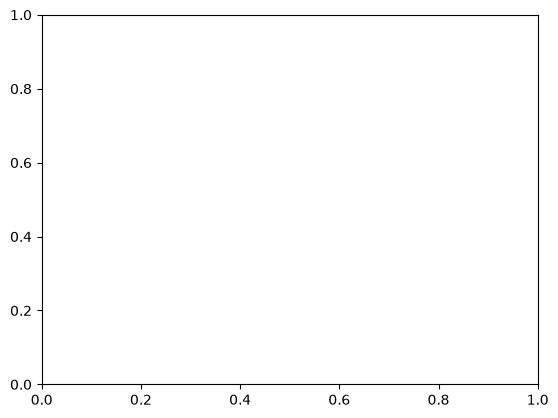

In [14]:
fig, ax = plt.subplots(1,1)

for i in range(0, len(phi_inf), max(1, len(phi_inf) // 32)):
    ax.plot(d*0.3, g["U"][i,:], label=f"$\\phi_\\infty$={phi_inf[i]:.4f}")
    # ax.scatter(d, g["U_br"][i,:,0], label=f"$\\phi_\\infty$={phi_inf[i]:.4f}", s=10)
ax.axhline(0, lw=0.5, c="k"); 
ax.set_xlabel("gap $d$"); 
ax.set_ylabel("$U(d)$"); 
# ax.set_ylim(-7, 0.2)
# ax.set_xlim(-0.1, 2.6)
# ax.legend()

#### Interpolated potentials

In [94]:
import json
import numpy as np

# Same location as PARAMS.sim.output_dir / PARAMS.sim.interp_file
# INTERP_JSON = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260721/test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260722/fisher_two_spheres_chi_3_h0_-0.5_R_4/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-1.0_chi_3/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-0.6_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/bvp_potential_interp.json"
# INTERP_JSON = "data/20260724/R_5_h0_-0.5_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260725/R_5_h0_-0.55_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260725/bvp_potential_interp.json"   # linear potential
# INTERP_JSON = "data/20260725/R_5_h0_-0.55_chi_2.5/bvp_potential_interp.json"
# INTERP_JSON = "data/20260728/R_5_h0_-0.4_chi_2.8/bvp_potential_interp.json" # fig5 F vs s plot
# INTERP_JSON = "data/20260807/fisher_two_spheres_test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260807/R_5_h0_-0.6_chi_3.0_bcr_0.05/bvp_potential_interp.json"
# INTERP_JSON = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/bvp_potential_interp.json"
# INTERP_JSON = "data/20260827/test/bvp_potential_interp.json"
# INTERP_JSON = "data/20260828/physical_R_20nm/bvp_potential_interp.json"
# INTERP_JSON = "data/20260830/test3/bvp_potential_interp.json"
# INTERP_JSON = "data/20260902/test3/bvp_potential_interp.json"
# INTERP_JSON = "data/20260912/test3/bvp_potential_interp.json"
INTERP_JSON = "data/20260927/s110/bvp_potential_interp.json"

def load_bvp_interp(path=INTERP_JSON):
    """bvp_potential_interp.jl output -> dict of numpy arrays (JSON null -> np.nan)."""
    with open(path) as f:
        d = json.load(f)
    arr = lambda x: np.array(x, dtype=float)
    return {
        "params":           d["params"],                 # full PARAMS tree (incl. sim, fpt, ...)
        "phi_inf":          arr(d["phi_inf"]),            # (nphi,)  == phi_inf_grid(PARAMS)
        "omega_b":          float(d["omega_b"]),
        "R":                float(d["R"]),
        "d_grid":           arr(d["d_grid"]),             # (N_D,)   BVP surface gaps
        "x_grid":           arr(d["x_grid"]),             # (Ngrid,) x = d + R
        "U_full_raw":       arr(d["U_full_raw"]),         # (nphi, N_D)   NaN where BVP unsolved
        "phi_surf_raw":     arr(d["phi_surf_raw"]),       # (nphi, N_D)   gap-facing surface phi
        "U_full_interp":    arr(d["U_full_interp"]),      # (nphi, Ngrid) nonlinear BVP, interpolated
        "phi_surf_interp":  arr(d["phi_surf_interp"]),    # (nphi, Ngrid) nonlinear BVP, interpolated
        "U_linear":         arr(d["U_linear"]),           # (nphi, Ngrid) linear-response U_ads
        "U_tot_full":       arr(d["U_tot_full"]),         # (nphi, Ngrid) + jacobian + Rouse spring
        "U_tot_linear":     arr(d["U_tot_linear"]),       # (nphi, Ngrid) + jacobian + Rouse spring
        # "input_by_cpu":     d["input_by_cpu"],            # {cpu: {phi_inf, U_full, phi_surf, d_grid}}
    }

D = load_bvp_interp()
print({k: (v.shape if isinstance(v, np.ndarray) else type(v).__name__) for k, v in D.items()})
# e.g. index a phi_inf row:  x, U = D["x_grid"], D["U_tot_full"][0]


{'params': 'dict', 'phi_inf': (32,), 'omega_b': 'float', 'R': 'float', 'd_grid': (17,), 'x_grid': (1500,), 'U_full_raw': (32, 17), 'phi_surf_raw': (32, 17), 'U_full_interp': (32, 1500), 'phi_surf_interp': (32, 1500), 'U_linear': (32, 1500), 'U_tot_full': (32, 1500), 'U_tot_linear': (32, 1500)}


In [20]:
# D["params"]

0.867741935483871


/tmp/ipykernel_329008/3052094608.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=12, edgecolor="none")


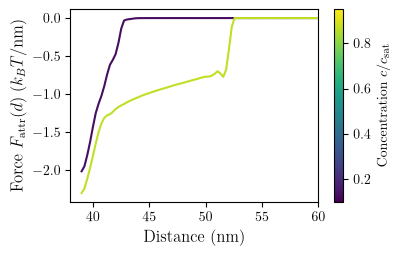

In [384]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1, 1, figsize=(4, 2.5))

keya = 28
xend = -1
print(phi_inf[keya]/phi_inf[0]/10)
d_grid = D["x_grid"][:xend]          # x = gap + R, in LATTICE units (not nm)
z = D["x_grid"][:xend]*0.3
U_full_interp = D["U_full_interp"].T[:xend, :keya]
U_tot_linear = D["U_tot_linear"].T[:xend, :keya]
U_tot_full = D["U_tot_full"].T[:xend, keya]
F_tot_full = - np.gradient(U_full_interp, d_grid, axis=0)

norm = plt.Normalize(vmin=phi_inf.min()/binodal[0], vmax=phi_inf.max()/binodal[0])
cmap = mpl.cm.viridis

for keya in [1, 28]:
    c = cmap(norm(phi_inf[keya]/binodal[0]))
    U_ads = D["U_full_interp"].T[:xend, keya]
    F_ads = -np.gradient(U_ads, z)
    # ax.plot(z, U_ads, color=c, alpha=1, lw=1.5)
    ax.plot(z, F_ads, color=c, alpha=1, lw=1.5)
ax.set_xlim(38, 60)
ax.legend(fontsize=12, edgecolor="none")
ax.set_xlabel("Distance (nm)", fontsize=12)
# ax.set_ylabel(r"Potential \\ $U_{\rm attr}(d) - U_{\rm attr}(\infty) (k_BT)$", fontsize=12)
ax.set_ylabel(r"Force $F_{\rm attr}(d) \;(k_BT/\rm nm)$", fontsize=12)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label=r'Concentration $c/c_{\rm sat}$')

In [176]:
out_dir = "media/figures/20260917"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "F_attr.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260917/F_attr.pdf


0.6758064516129032


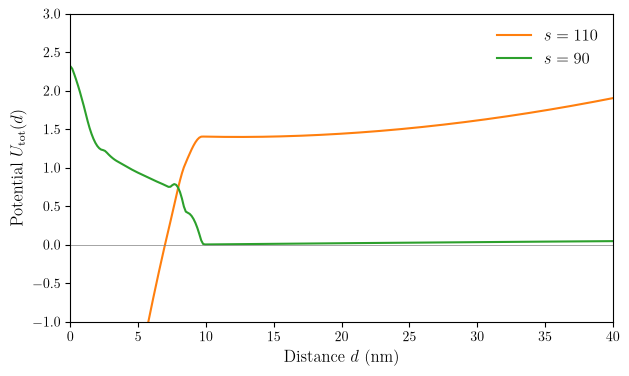

In [96]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1, 1, figsize=(7, 4))

keya = 21
xend = -1
print(phi_inf[keya]/binodal[0])
d_grid = D["x_grid"][:xend]          # x = gap + R, in LATTICE units (not nm)
z = D["x_grid"][:xend]*0.3 - 39
U_full_interp = D["U_full_interp"].T[:xend, :keya]
U_tot_linear = D["U_tot_linear"].T[:xend, :keya]
U_tot_full = D["U_tot_full"].T[:xend, keya]
F_tot_full = - np.gradient(U_full_interp, d_grid, axis=0)
# s, a from the run that built U_tot_full: `s` used to leak in from the scan cell
# below (it is never set here), and the phi row was keya-1 -- so U_tot was drawn at
# a different chain length AND a different concentration than U_tot_full.
s, a = D["params"]["rouse"]["s"], D["params"]["rouse"]["a"]

U_ads = D["U_full_interp"].T[:xend, keya]           # same phi row as U_tot_full
U_tot = (U_ads - 2*np.log(d_grid/(a * s**0.5)) + 3 * d_grid**2 / (2 * s * a**2))

# _=ax.plot(d_grid, U_tot_linear-2*np.log(d_grid)+3 * d_grid**2 / (2 * s * 1^2))
# _=ax.plot(D["x_grid"][:xend], D["U_tot_linear"].T[:xend, 1], 
#           color="navy", alpha=1, label=r"Low $c$")
beta = 1
# _=ax.plot(D["x_grid"][:xend]*0.3, np.exp(-beta*U_tot_full), 
#           color="green", alpha=1, label=r"High $c$")
# _=ax.plot(z, U_tot_full, color="C1", alpha=1, label=r"High $c$")
ax.plot(z, U_tot, color="C1", alpha=1, label=r"$s = 110$")

s = 90  # 70, 90, 110, 130, 150, 200, 300, 500
U_tot = (U_ads - 2*np.log(d_grid/(a * s**0.5)) + 3 * d_grid**2 / (2 * s * a**2))
ax.plot(z, np.gradient(U_tot, z), color="C2", alpha=1, label=r"$s = {}$".format(s))
# ax.plot(z, U_tot_full, color="C2", alpha=1, label=r"$s = 10$")

F_tot_linear = - np.gradient(U_tot_linear, d_grid, axis=0)

Z = np.trapezoid(np.exp(-beta*U_tot_full), z)
# ax.axvline(np.trapezoid(z*np.exp(-beta*U_tot_full)/Z, z))
ax.set_ylabel(r"Potential $U_{\rm tot}(d)$", fontsize=12)
ax.set_xlabel(r"Distance $d$ (nm)", fontsize=12)
ax.set_ylim(-1, 3)

ax.set_xlim(0, 40)
# for x in x_ridge:
#     ax.axvline(x*0.3, alpha=0.2)

ax.axhline(0, lw=0.5, color="gray")
# ax.set_ylim(-6.5, -2.5)
# ax.set_xlim(1.4, 3.5)
ax.legend(fontsize=12, edgecolor="none")


In [301]:
out_dir = "media/figures/20260912"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "combined_potential_vs_s.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260912/combined_potential_vs_s.pdf


#### Minimum $s$ per max $c$

ridge found for 32/32 concentrations: s* = 82..133, ridge at 44..56 nm


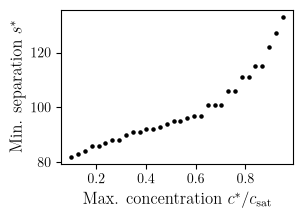

In [97]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

# Smallest Rouse length s for which U_tot(x) still shows a ridge, per concentration.
# Everything stays in the LATTICE units of D["x_grid"] (x = gap + R) -- the same
# units bvp_potential_interp.jl builds the jacobian and the spring in.  The ridge
# test is "U_tot is non-monotonic", i.e. dU/dx < 0 somewhere: at s below s* the
# spring swamps the -2 log x term and the outer well (and its ridge) is gone.
s_max = 300
x       = D["x_grid"]
a       = D["params"]["rouse"]["a"]
phi_inf = D["phi_inf"]
# phi_inf_grid(PARAMS) = binodal * linspace(phi_frac_min, phi_frac_max, n_phi)
c_sat = phi_inf[0] / D["params"]["sweep"]["phi_frac_min"]

seps   = np.full(len(phi_inf), np.nan)   # min s with a ridge
ridges = np.full(len(phi_inf), np.nan)   # where that ridge sits, in nm

for keya in range(len(phi_inf)):
    U_ads = D["U_full_interp"][keya]
    for s in range(1, s_max + 1):
        U_tot = U_ads - 2*np.log(x/(a*np.sqrt(s))) + 3*x**2/(2*s*a**2)
        F_tot = np.gradient(U_tot, x)
        if F_tot.min() < 0:
            seps[keya]   = s
            ridges[keya] = x[np.argmax(U_tot[:np.argmin(F_tot) + 1])] * 0.3
            break

fig, ax = plt.subplots(1, 1, figsize=(3, 2))
ax.scatter(phi_inf/c_sat, seps, color="black", s=5)
ax.set_ylabel(r"Min. separation $s^*$", fontsize=12)
ax.set_xlabel(r"Max. concentration $c^*/c_{\rm sat}$", fontsize=12)
print(f"ridge found for {np.isfinite(seps).sum()}/{len(seps)} concentrations: "
      f"s* = {np.nanmin(seps):.0f}..{np.nanmax(seps):.0f}, "
      f"ridge at {np.nanmin(ridges):.0f}..{np.nanmax(ridges):.0f} nm")


In [303]:
out_dir = "media/figures/20260912"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "min_sep.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260912/min_sep.pdf


### Exact FPT PDFs from solver

In [456]:
import json
import numpy as np

# dirname = "data/20260706/fpt_solver_c_sweep_h0_-0.3/fpt_solver_c_sweep.json"
# dirname = "data/20260718/fpt_solver_c_sweep_bvp/fpt_solver_c_sweep.json"
# dirname = "data/20260721/fisher_two_spheres_chi_2.5_h0_-0.6_R_5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260722/fisher_two_spheres_R_5_h0_-0.6/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260721/test/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_4_h0_-0.6_chi_2.5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_4_h0_-0.6_chi_2.5_res2/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260724/R_5_h0_-0.5_chi_2.5/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260725/R_5_h0_-0.55_chi_2.5/fisher_rate_from_fpt_solver.json"  # smooth
# dirname = "data/20260725/fisher_rate_from_fpt_solver.json"    # linear potential
# dirname = "data/20260728/R_5_h0_-0.4_chi_2.8_hires/fisher_rate_from_fpt_solver.json"  # smooth
# dirname = "data/20260728/R_5_h0_-0.5_chi_2.8/fisher_rate_from_fpt_solver.json"  # smooth
# dirname = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/fisher_rate_from_fpt_solver.json"  # very smooth
# dirname = "data/20260807/R_5_h0_-0.8_chi_3.0_bcr_0.04/fisher_rate_from_fpt_solver.json"  # very smooth
# dirname = "data/20260830/test3/fisher_rate_from_fpt_solver.json"
# dirname = "data/20260902/test3/fisher_rate_from_fpt_solver.json"
dirname = "data/20260912/test3/fisher_rate_from_fpt_solver.json"

with open(dirname) as f:
    d = json.load(f)

phi_infs = np.array(d["phi_infs"])            # swept concentrations (50,)
recs     = d["per_phi"]                        # list of 50 per-concentration records

coef = 50
# stack scalars into arrays indexed by phi
lam               = np.array([r["lam"]         for r in recs])
x_ridge           = np.array([r["x_ridge"]     for r in recs])
barrier           = np.array([r["barrier"]     for r in recs])
well_depth        = np.array([r["well_depth"]  for r in recs])
mfpt_esc          = np.array([r["escape_mfpt"] for r in recs]) * coef
mfpt_ret          = np.array([r["return_mfpt"] for r in recs]) * coef
fisher_poly       = np.array([r["fisher"] for r in recs]) #/ coef
fisher_poly_esc   = np.array([r["fisher_esc"] for r in recs]) # / coef
fisher_poly_ret   = np.array([r["fisher_ret"] for r in recs]) # / coef
phi_closed        = np.array([r["phi_local"]   for r in recs])
phi_surf          = np.array([r["phi_surf"]   for r in recs])
dphi_closed       = np.array([r["dphi_local"]  for r in recs])
phi_surf_2spheres     = np.array([r["phi_surf"]    for r in recs])
dphi_surf_2spheres    = np.gradient(phi_surf_2spheres[:,0], phi_infs[:-2])

# per-phi curves are ragged only in name; grab one record like this:
r = recs[0]                                    # r["phi_inf"] == phi_infs[0]
x_esc, U_esc = np.array(r["x_grid_esc"]), np.array(r["U_tot_esc"])   # potential (escape grid)
x_ret, U_ret = np.array(r["x_grid_ret"]), np.array(r["U_tot_ret"])   # potential (return grid)
t_esc, pdf_esc = np.array(r["escape_t"]), np.array(r["escape_pdf"])  # escape FPT density
t_ret, pdf_ret = np.array(r["return_t"]), np.array(r["return_pdf"])  # return FPT density

path = "data/20260912/test3/demo_bvp_profiles.json"   # test3 itself has no demo run
d = json.load(open(path))
binodal = d["binodal"]

/tmp/ipykernel_329008/475297839.py:40: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend(fontsize=11, edgecolor="none", loc="upper right")


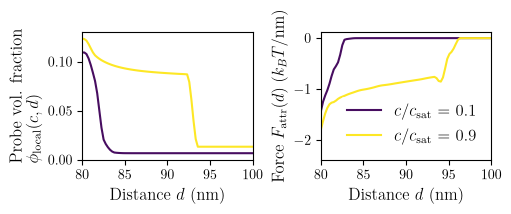

In [466]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1, 2, figsize=(5, 1.8), layout="constrained")

norm = plt.Normalize(vmin=phi_inf.min()/binodal[0], vmax=phi_inf.max()/binodal[0])
cmap = mpl.cm.viridis

ax[0].plot(x_ret*0.3+40, phi_surf[-1,:].T, color=cmap(norm(phi_inf[-1]/binodal[0])))
ax[0].plot(x_ret*0.3+40, phi_surf[1,:].T, color=cmap(norm(phi_inf[1]/binodal[0])))
# ax[0].set_xlim(133*0.3+40, 200*0.3+40)
ax[0].set_xlim(80, 100)
ax[0].set_ylim(0, 0.13)
ax[0].set_xlabel(r"Distance $d$ (nm)", fontsize=12)
ax[0].set_ylabel(r"\noindent Probe vol. fraction \\ $\phi_{\rm local}(c, d)$", fontsize=12)

xend = -1
d_grid = D["x_grid"][:xend]          # x = gap + R, in LATTICE units (not nm)
z = D["x_grid"][:xend]*0.3
U_full_interp = D["U_full_interp"].T[:xend, :keya]
U_tot_linear = D["U_tot_linear"].T[:xend, :keya]
U_tot_full = D["U_tot_full"].T[:xend, keya]
F_tot_full = - np.gradient(U_full_interp, d_grid, axis=0)
labels=["0.1", "0.9"]

for i, keya in enumerate([1, -1]):
    c = cmap(norm(phi_inf[keya]/binodal[0]))
    U_ads = D["U_full_interp"].T[:xend, keya]
    F_ads = -np.gradient(U_ads, z)
    # ax[1].plot(z, U_ads, color=c, alpha=1, lw=1.5)
    ax[1].plot(z+40, F_ads, color=c, alpha=1, lw=1.5, label=r"$c/c_{\rm sat}$ = "+labels[i])

ax[1].set_xlim(80, 100)
ax[1].legend(fontsize=12, edgecolor="none")
ax[1].set_xlabel("Distance $d$ (nm)", fontsize=12)
# ax[1].set_ylabel(r"Potential \\ $U_{\rm attr}(d) - U_{\rm attr}(\infty) (k_BT)$", fontsize=12)
ax[1].set_ylabel(r"Force $F_{\rm attr}(d) \;(k_BT/\rm nm)$", fontsize=12)
ax[0].legend(fontsize=11, edgecolor="none", loc="upper right")

Text(0, 0.5, 'Vol. fraction $\\phi$')

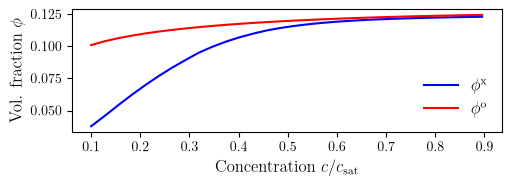

In [444]:
fig, ax = plt.subplots(1, 1, figsize=(5, 1.75), layout="constrained")

norm = plt.Normalize(vmin=phi_inf.min()/binodal[0], vmax=phi_inf.max()/binodal[0])
cmap = mpl.cm.viridis

ax.plot(phi_infs[:-2]/binodal[0], phi_closed, label=r"$\phi^{\rm x}$", color="blue")
ax.plot(phi_infs[:-2]/binodal[0], phi_surf[:,0], label=r"$\phi^{\rm o}$", color="red")
ax.legend(edgecolor="none", fontsize=12)
ax.set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
ax.set_ylabel(r"Vol. fraction $\phi$", fontsize=12)

In [467]:
out_dir = "media/figures/20261014"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "phi_x_o_force.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261014/phi_x_o_force.pdf


#### FPT (langevin)

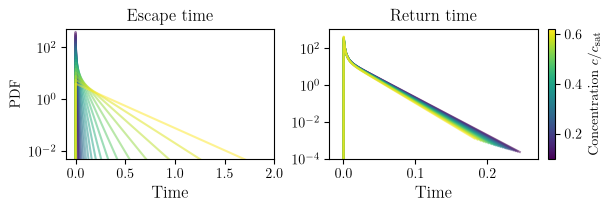

In [87]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,2,figsize=(6, 2), layout="constrained")

norm = plt.Normalize(vmin=phi_infs[:20].min()/binodal[0], vmax=phi_infs[:20].max()/binodal[0])
cmap = mpl.cm.viridis

for k, r in enumerate(recs[:20]):  
    c = cmap(norm(phi_infs[k]/binodal[0]))
                                      # r["phi_inf"] == phi_infs[0]
    x_esc, U_esc = np.array(r["x_grid_esc"]), np.array(r["U_tot_esc"])   # potential (escape grid)
    x_ret, U_ret = np.array(r["x_grid_ret"]), np.array(r["U_tot_ret"])   # potential (return grid)
    t_esc, pdf_esc = np.array(r["escape_t"])*coef, np.array(r["escape_pdf"])/coef  # escape FPT density
    t_ret, pdf_ret = np.array(r["return_t"])*coef, np.array(r["return_pdf"])/coef  # return FPT density

    ax[0].plot(t_esc, pdf_esc, color=c, alpha=0.5)
    ax[0].set_title("Escape time")
    ax[0].set_xlabel("Time", fontsize=12)
    ax[0].set_yscale("log")
    ax[0].set_ylim(5e-3, 500)
    # ax[0].set_xlim(-0.1, 2)
    ax[0].set_ylabel("PDF")

    ax[1].plot(t_ret, pdf_ret, color=c, alpha=0.5)
    ax[1].set_title("Return time")
    ax[1].set_xlabel("Time", fontsize=12)
    # ax[1].set_xscale("log")
    ax[1].set_yscale("log")
    ax[1].set_ylim(1e-4, 1100)
    # ax[1].set_xlim(9e-5, 50)

ax[0].set_xlim(-1e-1,2)
ax[1].set_xlim(-2e-2,0.27)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label=r'Concentration $c/c_{\rm sat}$')

In [45]:
out_dir = "media/figures/20260916"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "exit_return_pdfs_langevin.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260916/exit_return_pdfs_langevin.pdf


#### FPT (Rouse)

showing 20/30 concentrations (>= 50 events)


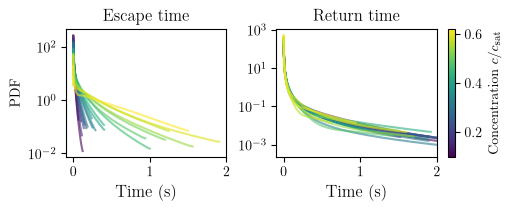

In [442]:
import matplotlib as mpl
from scipy.ndimage import gaussian_filter1d

path = "data/20260902/test3/demo_bvp_profiles.json"
d = json.load(open(path))
binodal = d["binodal"]

# Same figure as the solver PDFs above, but built from the empirical Rouse
# sojourn times (data/20260902/rouse).  Requires `data` / `alphas` from the
# "Comparison with Rouse simulation" cell; concentrations with too few events
# are dropped.
min_events = 50

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on the log-time grid
smooth_sigma = 20      # smoothing width in grid bins (larger = smoother)
per_decade   = False   # True: plot density per log10-decade (flatter on log-x)
                       # False: plot the true pdf f(t) = dF/dt
# ---------------------------------------------------------------------------

def cdf_to_pdf(times, n_grid=n_grid, sigma=smooth_sigma):
    """Empirical CDF -> smooth in log-time -> differentiate to a pdf."""
    t = np.sort(np.asarray(times, dtype=float))
    t = t[t > 0]                              # log-time needs t > 0
    if t.size < 2:
        return None, None
    grid = np.logspace(np.log10(t[0]), np.log10(t[-1]), n_grid)
    u    = np.log10(grid)
    F    = np.searchsorted(t, grid, side='right') / t.size   # empirical CDF on grid
    F    = gaussian_filter1d(F, sigma=sigma, mode='nearest') # smooth the CDF
    dF_du = np.gradient(F, u)                                 # density per decade
    pdf   = dF_du if per_decade else dF_du / (grid * np.log(10.0))  # -> f(t)
    return grid, np.clip(pdf, 0, None)

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1, 2, figsize=(5, 2), layout="constrained")

shown = [a for a in alphas
         if max((np.asarray(data[a]["escape_times"]) > 0).sum(),
                (np.asarray(data[a]["return_times"]) > 0).sum()) >= min_events]
norm = plt.Normalize(vmin=min(shown)/binodal[0], vmax=max(shown)/binodal[0])
cmap = mpl.cm.viridis

for a in shown:
    c = cmap(norm(a/binodal[0]))
    for i, key in enumerate(["escape", "return"]):
        t = np.asarray(data[a][f"{key}_times"]) * coef
        t = t[t > 0]
        if t.size < min_events:          # this panel alone is too sparse
            continue
        g, p = cdf_to_pdf(t)
        m = p > 0                        # log axis: drop the clipped plateaus
        ax[i].plot(g[m], p[m], color=c, alpha=0.6, lw=1.5)

ax[0].set_title("Escape time")
ax[0].set_ylabel("density per decade" if per_decade else "PDF")
ax[1].set_title("Return time")
for a in ax:
    a.set_xlabel("Time (s)", fontsize=12)
    # a.set_xscale("log")
    a.set_yscale("log")

ax[0].set_xlim(-1e-1,2)
ax[1].set_xlim(-1e-1,2)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label=r'Concentration $c/c_{\rm sat}$')
print(f"showing {len(shown)}/{len(alphas)} concentrations (>= {min_events} events)")


In [443]:
out_dir = "media/figures/20261014"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "exit_return_pdfs_rouse.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261014/exit_return_pdfs_rouse.pdf


#### Comparison with Rouse simulation

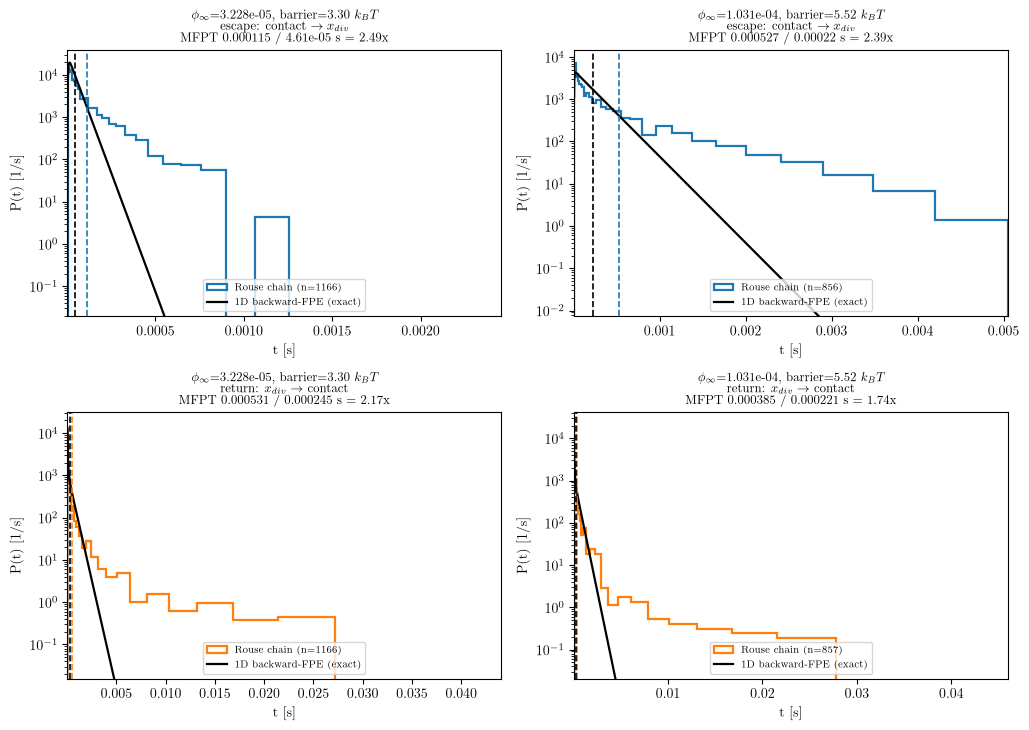

In [99]:
import json, glob
import numpy as np
import matplotlib.pyplot as plt

# --- Rouse sojourn samples (spec/rouse_mfpt_attractive.jl) ------------------
# _data_dir = "data/20260830/test3_rouse"
_data_dir = "data/20260912/rouse"
data = {}
for _path in sorted(glob.glob(f"{_data_dir}/output_cpu*.json")):
    with open(_path) as _f:
        _raw = json.load(_f)
    for _keya in _raw:
        for _run in _raw[_keya].values():
            data[_run["alpha"]] = _run

# _data_dir = "data/20260830/test3_rouse_run2"
# for _path in sorted(glob.glob(f"{_data_dir}/output_cpu*.json")):
#     with open(_path) as _f:
#         _raw = json.load(_f)
#     for _keya in _raw:
#         for _run in _raw[_keya].values():
#             data[_run["alpha"]] = _run

# --- exact FPT-solver PDFs (fisher_rate_from_fpt_solver.jl) -----------------
_fisher_path = "data/20260912/test3/fisher_rate_from_fpt_solver.json"
with open(_fisher_path) as _f:
    fisher = json.load(_f)
solver = {r["phi_inf"]: r for r in fisher["per_phi"]}

alphas = np.array(sorted(data))
nbins = 40

# Provenance: the chain integrated whatever U_ads was on disk when the sweep
# started, and its thresholds are that run's x_div.  If the pipeline has been
# re-run since, the stored PDFs belong to a different potential -- say so.
for a in [alphas[0], alphas[6]]:
    if not np.isclose(data[a]["x_div"], fisher["x_div"], rtol=1e-9):
        print(f"WARNING phi={a:.4e}: rouse ran at x_div={data[a]['x_div']:.4f}, "
              f"solver json has {fisher['x_div']:.4f} -- potentials differ")

fig, axes = plt.subplots(2, 2, figsize=(5.2 * 2, 7.4),
                         squeeze=False)

for j, a in enumerate([alphas[0], alphas[8]]):
    run = data[a]
    rec = solver[min(solver, key=lambda p: abs(p - a))]
    for i, (key, lab, col) in enumerate([("escape", "escape: contact $\\to x_{div}$", "C0"),
                                         ("return", "return: $x_{div} \\to$ contact", "C1")]):
        ax = axes[i][j]
        t = np.asarray(run[f"{key}_times"])
        t = t[t > 0]
        # print(t.max())
        # log-spaced bins + density=True: the histogram integrates to 1 in t, so it
        # is directly comparable to the solver PDF (both are densities per unit t).
        bins = np.logspace(np.log10(t.min()), np.log10(t.max()), nbins)
        h, _, _ = ax.hist(t, bins=bins, density=True, color=col, histtype="step",
                          lw=1.6, label=f"Rouse chain  (n={t.size})")

        ts, ps = np.asarray(rec[f"{key}_t"]), np.asarray(rec[f"{key}_pdf"])
        ax.plot(ts, ps, "k-", lw=1.6, label="1D backward-FPE (exact)")

        m_r, m_s = t.mean(), rec[f"{key}_mfpt"]
        ax.axvline(m_r, color=col, ls="--", lw=1.2)
        ax.axvline(m_s, color="k", ls="--", lw=1.2)

        # ax.set_xscale("log"); 
        ax.set_yscale("log")
        _m = ps > ps.max() * 1e-6                    # trim the solver's dead log-grid head
        ax.set_xlim(min(t.min(), ts[_m][0]) / 2, max(t.max(), ts[_m][-1]))
        _ymax = max(ps.max(), h.max())
        ax.set_ylim(_ymax * 1e-6, _ymax * 2)
        ax.set_xlabel("t  [s]"); ax.set_ylabel("P(t)  [1/s]")
        ax.set_title(f"$\\phi_\\infty$={a:.3e},  barrier={rec['barrier']:.2f} $k_BT$\n"
                     f"{lab}\nMFPT {m_r:.3g} / {m_s:.3g} s  = {m_r / m_s:.2f}x", fontsize=9)
        ax.legend(fontsize=7, loc="lower center")

fig.tight_layout()

In [36]:
data[alphas[23]]["rouse_params"]["D_eff"] * 0.3**2 * 1e-6    # um^2 / s

13.356

In [57]:
data[alphas[20]]["runtime_min"]/60
data[alphas[23]]["rouse_params"]["tau_bond"] /data[alphas[23]]["rouse_params"]["dt"]

1600.0

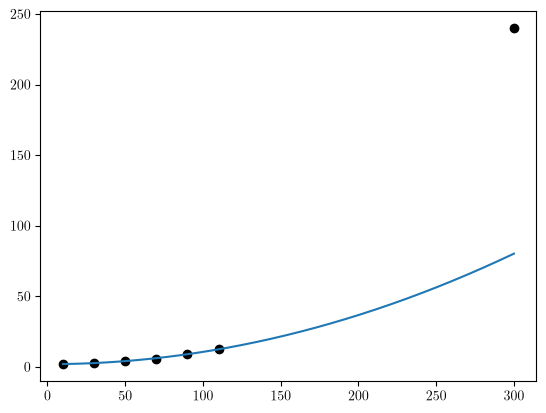

In [77]:
x = [10, 30, 50, 70, 90, 110, 300]
y = [2,3,4,6,9,13,240]
xx = np.linspace(10, 300, 1000)

fig, ax = plt.subplots(1,1)

ax.scatter(x, y, color="black")
ax.plot(xx, 0.00087*xx**2 + 2)

#### Fisher rate from Rouse simulation

In [102]:
# ---- Fisher information rate from the Rouse sojourn samples ---------------
# Same estimator as the Langevin cell, but fed by spec/jobs/20260828/test3/
# rouse_mfpt_attractive.jl and built to the SAME convention as `fisher_rate_poly`
# (cell 98 / fisher_rate_from_fpt_solver.jl), so the two arrays overlay directly:
#   - score from the OUTER pair (phi_k, phi_k+2) at spacing 2*dphi, weighted by
#     P(t|phi_k)                                     [avg_dlogp2 in the Julia]
#   - prefactor phi_k^2, normalised by the cycle time MFPT_esc + MFPT_ret
#   - divided by `coef`, i.e. reported per ms, exactly like fisher_rate_poly
# Requires `data` from the "Comparison with Rouse simulation" cell.
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on each fixed log-time grid
smooth_sigma = 20      # CDF smoothing width in grid bins (was 50: over-smooths here)
# coef         = 200    # SAME s -> ms rescale as the solver cell
# ---------------------------------------------------------------------------

phi_rouse = np.array(sorted(data))[:-5]          # == phi_infs[:-2], uniform spacing
K         = len(phi_rouse)
assert np.allclose(phi_rouse, phi_infs[:len(phi_rouse)], rtol=1e-9), \
    "Rouse phi grid does not match the solver's -- arrays are not comparable"

# pooled series per concentration, in SECONDS.  escape = closed/bound dwell
# (contact -> x_div), return = open/unbound dwell (x_div -> contact).
series_b = [np.asarray(data[a]["escape_times"], float) for a in phi_rouse]
series_u = [np.asarray(data[a]["return_times"], float) for a in phi_rouse]

N_SUB, NBOOT, LOGFIT = 6, 500, True          # N_SUB must match fit_c/fit_o
tr  = np.log10 if LOGFIT else (lambda z: z)
inv = (lambda z: 10.0**z) if LOGFIT else (lambda z: z)

def fit_smooth(x, d, w, lam, n_sub=N_SUB):
    x, d, w = np.asarray(x, float), np.asarray(d, float), np.asarray(w, float)
    N = d.size; n = (N - 1)*n_sub + 1
    t = np.linspace(0.0, 1.0, n); h = t[1] - t[0]
    idx = np.arange(N)*n_sub
    E2 = (np.eye(n, k=1)*-2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S = np.zeros((N, n)); S[np.arange(N), idx] = 1.0
    A = S.T @ (w[:, None]*S)/w.sum() + lam*h*(E2.T @ E2)/h**4
    A += 1e-12*np.trace(A)/n*np.eye(n)
    H = np.linalg.solve(A, S.T*w/w.sum())          # y = H d  (cols of w=0 are 0)
    y = H @ np.where(w > 0, d, 0.0)                # so the nan endpoints can't leak
    return dict(x=x[0] + (x[-1] - x[0])*t, y=y, H=H, idx=idx, lam=lam,
                edf=float(np.trace(H[idx])), w=w,
                valid=(t >= (idx[w > 0][0])/(n - 1)) & (t <= (idx[w > 0][-1])/(n - 1)))

def loocv_smooth(x, d, w, lams, n_sub=N_SUB):
    """Closed-form leave-one-out over the weighted points only."""
    m = np.asarray(w) > 0
    out = []
    for lam in lams:
        f = fit_smooth(x, d, w, lam, n_sub)
        e = (f["y"][f["idx"]] - np.where(m, d, 0.0))/(1.0 - np.diag(f["H"][f["idx"]]))
        out.append((np.mean(e[m]**2), lam, np.where(m, e, 0.0)))
    cv = np.array([o[0] for o in out]); k = int(np.argmin(cv))
    return out[k][1], cv, out[k][2]

def make_grid(all_series, n=n_grid):
    """One fixed log-time grid shared by every concentration (so PDFs line up)."""
    lo = min(a[a > 0].min() for a in all_series)
    hi = max(a.max()        for a in all_series)
    return np.logspace(np.log10(lo), np.log10(hi), n)

def pdf_on_grid(times, grid, sigma=smooth_sigma):
    """Smoothed empirical pdf f(t) evaluated on the *fixed* grid."""
    t = np.sort(np.asarray(times, float)); t = t[t > 0]
    u = np.log10(grid)
    F = np.searchsorted(t, grid, side='right') / t.size    # empirical CDF on grid
    F = gaussian_filter1d(F, sigma=sigma, mode='nearest')  # smooth the CDF
    pdf = np.gradient(F, u) / (grid * np.log(10.0))        # f(t) = dF/dt
    return np.clip(pdf, 0.0, None)

def score2_fisher(t, p_lo, p0, p_hi, dphi):
    """∫ P(t|phi) (∂logP/∂phi)² dt  — score-squared Fisher estimator (central 3-pt in phi)."""
    fl    = p0.max() * 1e-10
    lp_lo = np.log(np.maximum(p_lo, fl))
    lp_hi = np.log(np.maximum(p_hi, fl))
    score = (lp_hi - lp_lo) / (2.0 * dphi)                 # ∂logP/∂phi  (central)
    integrand = p0 * score**2                              # = (∂P/∂phi)² / P
    integrand = np.where((p0 > fl) & (p_lo > fl) & (p_hi > fl), integrand, 0.0)
    return np.trapezoid(integrand, t)                          # = +I(phi), always ≥ 0

# fixed grids + PDF stacks (rows = concentration)
grid_b, grid_u = make_grid(series_b), make_grid(series_u)
P_b = np.array([pdf_on_grid(series_b[k], grid_b) for k in range(K)])
P_u = np.array([pdf_on_grid(series_u[k], grid_u) for k in range(K)])

# cycle time straight from the chain (biased low if a sojourn ran past the trace end)
mfpt_esc_rouse  = np.array([s.mean() for s in series_b])          # seconds
mfpt_ret_rouse  = np.array([s.mean() for s in series_u])
tau_cycle_rouse = mfpt_esc_rouse + mfpt_ret_rouse

log_var_esc_rouse  = np.array([np.var(np.log10(s))/len(s) for s in series_b])          # seconds
log_var_ret_rouse  = np.array([np.var(np.log10(s))/len(s) for s in series_u])

err_tau_cycle_rouse = 10 ** (np.sqrt(log_var_esc_rouse + log_var_ret_rouse))

# variance of the MEAN sojourn time (not of one sojourn): the sojourns are iid draws
# within a concentration, so var(mean) = var(t)/n.  The pdfs are heavy-tailed, so this
# is the naive iid SEM -- it under-states the error if the tail is under-sampled.
var_mfpt_esc_rouse = np.array([s.var(ddof=1)/s.size for s in series_b])   # s^2
var_mfpt_ret_rouse = np.array([s.var(ddof=1)/s.size for s in series_u])

# I(phi) with the solver's stencil: p_lo = p0 = P[k], p_hi = P[k+2].  The last two
# entries are NaN -- phi_k+2 is off the end of the Rouse sweep, the same way the
# solver's own fisher_rate is only defined on phi_infs[:-2].
dphi = phi_rouse[1] - phi_rouse[0]
fisher_rate_rouse_esc = np.full(K, np.nan)
fisher_rate_rouse_ret = np.full(K, np.nan)
for k in range(K - 2):
    I_b = score2_fisher(grid_b, P_b[k], P_b[k], P_b[k + 2], dphi)
    I_u = score2_fisher(grid_u, P_u[k], P_u[k], P_u[k + 2], dphi)
    fisher_rate_rouse_esc[k] = phi_rouse[k]**2 * I_b / tau_cycle_rouse[k]
    fisher_rate_rouse_ret[k] = phi_rouse[k]**2 * I_u / tau_cycle_rouse[k]

fisher_rate_rouse     = (fisher_rate_rouse_esc + fisher_rate_rouse_ret) / coef
fisher_rate_rouse_esc = fisher_rate_rouse_esc / coef
fisher_rate_rouse_ret = fisher_rate_rouse_ret / coef
mfpt_esc_rouse        = mfpt_esc_rouse * coef      # ms, as in the solver cell
mfpt_ret_rouse        = mfpt_ret_rouse * coef
var_mfpt_esc_rouse    = var_mfpt_esc_rouse * coef**2   # variances follow mfpt*coef
var_mfpt_ret_rouse    = var_mfpt_ret_rouse * coef**2

# ---- smooth along phi ------------------------------------------------------
# Same cubic smoothing spline + closed-form LOOCV lambda used for the Fisher rates in
# the next cell, applied in log10 (means and variances are both strictly positive).
lams_mfpt = np.logspace(-10, 1, 23)

def smooth_phi(y, lams=lams_mfpt):
    """LOOCV-smoothed y(phi) on the phi_rouse grid, fitted in log10."""
    w = (np.isfinite(y) & (y > 0)).astype(float)
    d = np.log10(np.where(w > 0, y, 1.0))
    lam, _, _ = loocv_smooth(phi_rouse, d, w, lams)
    f = fit_smooth(phi_rouse, d, w, lam)
    return np.where(w > 0, 10.0**f["y"][f["idx"]], np.nan), lam, f["edf"]

mfpt_esc_rouse_fit,     _lam_e,  _edf_e  = smooth_phi(mfpt_esc_rouse)
mfpt_ret_rouse_fit,     _lam_r,  _edf_r  = smooth_phi(mfpt_ret_rouse)
var_mfpt_esc_rouse_fit, _lam_ve, _edf_ve = smooth_phi(var_mfpt_esc_rouse)
var_mfpt_ret_rouse_fit, _lam_vr, _edf_vr = smooth_phi(var_mfpt_ret_rouse)

print(f"phi-spline edf/{K}:  mfpt esc {_edf_e:.1f}  ret {_edf_r:.1f}   "
      f"var esc {_edf_ve:.1f}  ret {_edf_vr:.1f}   (edf ~ K => interpolating)")
print("SEM/mean on the cycle time: " + " ".join(f"{x:.3f}" for x in
      np.sqrt(var_mfpt_esc_rouse_fit + var_mfpt_ret_rouse_fit)
      / (mfpt_esc_rouse_fit + mfpt_ret_rouse_fit)))


phi-spline edf/25:  mfpt esc 3.7  ret 4.6   var esc 5.8  ret 7.4   (edf ~ K => interpolating)
SEM/mean on the cycle time: 0.110 0.115 0.117 0.115 0.110 0.107 0.100 0.089 0.080 0.075 0.074 0.076 0.078 0.079 0.079 0.080 0.081 0.085 0.093 0.108 0.134 0.173 0.231 0.318 0.450


In [103]:
# ---- per-cycle Fisher information: Monte-Carlo score-squared estimator -------
# I(c) = E_c[s(X;c)^2] with the score s = dlogP(X|c)/dc.  Rather than integrating the
# smoothed PDF against the score (score2_fisher, cell 107), average the squared score
# over the ACTUAL escape samples:
#     G_m = s(t_m; phi_k)^2,   I_hat = (1/M) sum_m G_m,   Var(I_hat) = Var_c(G)/M
#     SE  = s_G/sqrt(M),       s_G^2 = sum_m (G_m - I_hat)^2/(M - 1)
# The score is unchanged -- the central difference on the OUTER pair (phi_k, phi_k+2)
# at spacing 2 dphi -- so only the integration WEIGHT changes: the empirical measure of
# the sample instead of the gaussian-smoothed PDF, which broadens into the large-score
# tails (I_hat runs ~0.6-0.9x the quadrature value; the last column below).  The pay-off
# is that every concentration now carries its own error bar.
#
# ESCAPE CHANNEL ONLY -- the return channel is left to fisher_rate_rouse_ret.
# Caveat: the score itself is built from the smoothed PDFs, this concentration's own
# included, so SE is the sampling error of the mean of G at FIXED score; it does not
# carry the score's own estimation error.
fisher_cycle_esc    = np.full(K, np.nan)      # I_hat(phi), per cycle
fisher_cycle_esc_se = np.full(K, np.nan)      # s_G / sqrt(M)
n_mc                = np.zeros(K, int)        # M
frac_floored        = np.full(K, np.nan)      # fraction of samples where a PDF underflows

_lg = np.log10(grid_b)
for k in range(K - 2):                        # last two: phi_k+2 is off the sweep
    t  = series_b[k][series_b[k] > 0]
    lt = np.log10(t)
    fl = P_b[k].max() * 1e-10
    _logp = lambda p: np.interp(lt, _lg, np.log(np.maximum(p, fl)))
    G    = ((_logp(P_b[k + 2]) - _logp(P_b[k])) / (2 * dphi))**2
    keep = (np.interp(lt, _lg, P_b[k]) > fl) & (np.interp(lt, _lg, P_b[k + 2]) > fl)
    G    = np.where(keep, G, 0.0)             # score2_fisher zeroes the same region
    fisher_cycle_esc[k]      = G.mean()
    fisher_cycle_esc_se[k]   = G.std(ddof=1) / np.sqrt(G.size)
    n_mc[k], frac_floored[k] = G.size, 1.0 - keep.mean()

# ---- Fisher rate per unit time ----------------------------------------------
# rate = phi^2 I_hat / tau_cycle with tau_cycle = MFPT_esc + MFPT_ret already in `coef`
# units (cell 107), so this is per ms exactly like fisher_rate_rouse_esc.  The two
# relative errors add in quadrature; they are built from the same escape sample, so
# this drops a (small) covariance between I_hat and tau_cycle.
tau_cycle_mc     = mfpt_esc_rouse + mfpt_ret_rouse
var_tau_cycle_mc = var_mfpt_esc_rouse + var_mfpt_ret_rouse

fisher_rate_mc_esc     = phi_rouse**2 * fisher_cycle_esc / tau_cycle_mc
err_fisher_rate_mc_esc = fisher_rate_mc_esc * np.sqrt(
    (fisher_cycle_esc_se / fisher_cycle_esc)**2 + var_tau_cycle_mc / tau_cycle_mc**2)

fisher_cycle_esc_fit, _, _,            = smooth_phi(phi_rouse**2 * fisher_cycle_esc)
fisher_cycle_esc_se_fit, _, _,            = smooth_phi(phi_rouse**2 * fisher_cycle_esc_se)
fisher_rate_mc_esc_fit, _lam_F, _edf_F = smooth_phi(fisher_rate_mc_esc)
var_fisher_rate_mc_fit, _, _           = smooth_phi(err_fisher_rate_mc_esc**2)

# ---- diagnostics ------------------------------------------------------------
print(f"phi-spline on the MC rate: edf={_edf_F:.1f}/{K-2}\n")
print(f"{'phi':>10} {'M':>5} {'I_hat':>11} {'SE/I':>6} {'floor':>6} | {'SE_tau/tau':>10}"
      f" {'rate':>10} {'SE/rate':>8} | {'I_quad/I_hat':>12}")
for k in range(K - 2):
    print(f"{phi_rouse[k]:10.3e} {n_mc[k]:5d} {fisher_cycle_esc[k]:11.4e}"
          f" {fisher_cycle_esc_se[k]/fisher_cycle_esc[k]:6.3f} {frac_floored[k]:6.3f} |"
          f" {np.sqrt(var_tau_cycle_mc[k])/tau_cycle_mc[k]:10.3f}"
          f" {fisher_rate_mc_esc[k]:10.3e} {err_fisher_rate_mc_esc[k]/fisher_rate_mc_esc[k]:8.3f} |"
          f" {fisher_rate_rouse_esc[k]*tau_cycle_mc[k]/phi_rouse[k]**2/fisher_cycle_esc[k]:12.3f}")

# The quoted SE covers the sampling of G at FIXED score.  The score is itself built from
# two finite-sample PDFs and that noise is NOT in it, so the points scatter about the
# phi-spline by more than their error bars:
_m    = np.isfinite(fisher_rate_mc_esc) & np.isfinite(fisher_rate_mc_esc_fit)
_sig  = err_fisher_rate_mc_esc/(fisher_rate_mc_esc*np.log(10))      # log10-space sigma
_chi2 = np.mean(((np.log10(fisher_rate_mc_esc[_m])
                  - np.log10(fisher_rate_mc_esc_fit[_m]))/_sig[_m])**2)
print(f"\nreduced chi^2 of the points about the phi-spline: {_chi2:.1f}  => the SE above"
      f" misses a factor ~{np.sqrt(_chi2):.1f}\nof the phi-to-phi scatter, which is the"
      f" noise in the SCORE that this estimator holds fixed.")

phi-spline on the MC rate: edf=3.6/23

       phi     M       I_hat   SE/I  floor | SE_tau/tau       rate  SE/rate | I_quad/I_hat
 3.228e-05  1166  7.7868e+07  0.030  0.000 |      0.105  2.513e+00    0.110 |        1.339
 4.113e-05   895  9.9054e+07  0.039  0.000 |      0.121  3.860e+00    0.127 |        1.546
 4.998e-05  1036  9.1946e+07  0.051  0.000 |      0.111  6.143e+00    0.123 |        1.614
 5.883e-05   939  9.7672e+07  0.046  0.000 |      0.129  8.135e+00    0.137 |        1.495
 6.768e-05  1121  5.8220e+07  0.045  0.000 |      0.083  7.773e+00    0.094 |        1.566
 7.653e-05   851  1.0066e+08  0.033  0.000 |      0.116  1.293e+01    0.120 |        1.243
 8.538e-05   747  1.5342e+08  0.046  0.000 |      0.120  2.140e+01    0.129 |        1.492
 9.423e-05   879  1.4129e+08  0.047  0.000 |      0.083  2.813e+01    0.096 |        1.450
 1.031e-04   856  2.0099e+08  0.044  0.000 |      0.082  4.681e+01    0.093 |        1.181
 1.119e-04   693  1.8312e+08  0.035  0.000 |      0

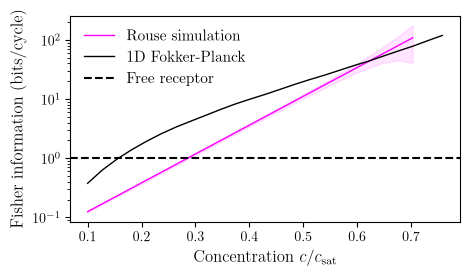

In [104]:
# ---- plot: Rouse polymer Fisher rate (escape channel), per unit time ---------
fig, ax = plt.subplots(figsize=(4.8, 2.8))
# ax.errorbar(phi_rouse/binodal[0], fisher_rate_mc_esc, yerr=err_fisher_rate_mc_esc,
#             fmt='o', ms=3, lw=0.8, capsize=2, color='crimson', label='closed (Rouse)')

# kept under the old names: cell 113's commented-out Rouse block reads them
fisher_rouse_logfit     = np.log10(fisher_rate_mc_esc_fit)
fisher_rouse_err_logfit = np.sqrt(var_fisher_rate_mc_fit)/(fisher_rate_mc_esc_fit*np.log(10))

ax.plot(phi_rouse/binodal[0],  fisher_cycle_esc_fit, color='magenta',
        label='Rouse simulation', lw=1)
ax.fill_between(phi_rouse/binodal[0],  fisher_cycle_esc_fit + fisher_cycle_esc_se_fit, 
                fisher_cycle_esc_fit - fisher_cycle_esc_se_fit, color='magenta', alpha=0.1)
# ax.plot(phi_rouse/binodal[0],  fisher_cycle_esc_fit, color='magenta', lw=1,
#         label='Spline')
ax.plot(phi_rouse/binodal[0], fisher_poly_esc[:-5], '-', color='black', lw=1.0,
        label='1D Fokker-Planck')
ax.axhline(1, color="black", lw=1.5, alpha=1, linestyle="dashed", label="Free receptor")
# ax.fill_between(phi_rouse/binodal[0],
#     10**(fisher_rouse_logfit - fisher_rouse_err_logfit),
#     10**(fisher_rouse_logfit + fisher_rouse_err_logfit), color='magenta', alpha=0.2)
ax.set_xlabel(r"Concentration  $c/c_{\rm sat}$", fontsize=12)
ax.set_ylabel(r"Fisher information (bits/cycle)", fontsize=12)
ax.set_yscale('log')
ax.legend(fontsize=11, edgecolor="none")
plt.tight_layout()
plt.show()

In [100]:
out_dir = "media/figures/20260916"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_per_cycle.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260916/fisher_per_cycle.pdf


#### Polymer Fisher rates

In [319]:
bds1 = (0.18, 0.69, 0.22, 0.22)
bds2 = (0.14, 0.65, 0.25, 0.28)
lloc = (0.8, 0.1)

In [446]:
# =========================================================================================
#  Fisher information rates vs bulk concentration, Rouse polymer at s = 300
# =========================================================================================
#
# Three panels, all against the bulk concentration c / c_sat:
#   top     probability that the polymer is closed, P(closed) = <escape> / <cycle>, next to
#           the probability that a free receptor is bound
#   middle  the polymer's cycle time <escape> + <return>, next to a free receptor's
#           binding + unbinding cycle
#   bottom  Fisher information rates of four ways to sense the concentration:
#             free receptor       (black, dashed)  no condensate, no polymer
#             proximal only       (red)            the receptor in the condensate film of its
#                                                  own sphere; the polymer is ignored
#             polymer only        (blue)           F_poly, the information in the polymer's
#                                                  escape cycles
#             proximal + distal   (black)          F_poly + F_local, where F_local is the
#                                                  receptor's rate averaged over the open and
#                                                  closed polymer, weighted by their
#                                                  occupancies:
#                     F_local = (1 - P(closed)) F_open + P(closed) F_closed
#
# F_poly is estimated with the histogram estimator of viz_util/rouse_fisher.py (also used by
# cell 127; its docstring explains the method), from the three independent Rouse runs of
# data/20261014 (s = 300, 30 concentrations), pooled.  At concentration phi_k the score is
# the finite difference between phi_k and phi_k+2, the same stencil as the 1D FPT solver.
# Concentrations where either phi_k or phi_k+2 has fewer than `min_cycles_per_phi` cycles
# (the highest ones, where escapes become rare) are left out.
#
# Error bands: P(closed), the cycle time and F_poly carry the block-bootstrap errors of
# rouse_fisher; the blue curve is F_poly's smooth trend (rouse_fisher.trend_along).  The black
# curve is the blue curve plus F_local, so it lies above it by exactly F_local.  F_poly and
# F_local move together with the two mean sojourn times, so the black band comes from the SAME
# bootstrap replicates of both -- each replicate's refitted polymer trend plus that replicate's
# F_local -- not from adding errors in quadrature.
#
# Also defines the single-sphere and free-receptor quantities (phi_inf, phi_full, binodal,
# kb, ku, K_D, fisher_rate_free, fisher_rate_open, ...) that later cells reuse.

import glob
import importlib
import json
import numpy as np
import matplotlib.pyplot as plt
from viz_util import rouse_fisher
importlib.reload(rouse_fisher)            # pick up edits to the module without restarting

# -----------------------------------------------------------------------------------------
# Settings
# -----------------------------------------------------------------------------------------
ROUSE_ROOT         = "data/20261014"      # independent runs run*/s<s>/ (pooled)
GENOMIC_SEPARATION = 300
# single-sphere profiles: 20261014 has none, and 20261013 has identical physics (checked below)
SINGLE_SPHERE_FILE = "data/20261013/demo_bvp_profiles.json"
PHI_STEP_OF_SCORE  = 2                    # score from phi_k and phi_{k+2}, as in the 1D solver

# free receptor
v_tf     = 120       # volume of one transcription factor, nm^3 (120 <-> nb = 4000)
a_rec    = 3e-3      # receptor radius, um (10 bp; NOT the Rouse Kuhn length `a`)
D_tf     = 7.4       # transcription-factor diffusion constant, um^2/s
K_D_frac = 0.325       # dissociation constant, as a fraction of c_sat

fisher_settings = rouse_fisher.FisherSettings(
    time_rescale=100,            # simulated seconds -> plotting time units (= `coef`, cell 97)
    n_histogram_bins=40,
    min_cycles_per_phi=300,
    n_folds=5,
    block_length=50,
    n_bootstrap=200,
    n_permutations=50,
    min_signal_to_noise=3,
    seed=20261014,
)


def particles_per_um3(phi):
    """Volume fraction -> number of transcription factors per um^3 (v_tf in nm^3, 1 um^3 = 1e9 nm^3)."""
    return phi / v_tf * 1e9


# -----------------------------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------------------------
# ---- single isolated sphere: surface concentration at every bulk concentration ----
with open(SINGLE_SPHERE_FILE) as f:
    single_sphere = json.load(f)
phi_inf  = np.array(single_sphere["phi_inf"])           # bulk volume fractions, (n_phi,)
mu_inf   = np.array(single_sphere["mu_inf"])
z_full   = np.array(single_sphere["z_full"])            # distance from the sphere surface
z_lin    = np.array(single_sphere["z_linear"])
phi_full = np.array(single_sphere["phi_solver"])        # concentration profiles, (n_phi, n_z)
R, omega_b = single_sphere["R"], single_sphere["omega_b"]
h0       = single_sphere["params"]["surface"]["omega_b"]
binodal  = float(np.atleast_1d(single_sphere["binodal"])[0])   # c_sat as a volume fraction
chi      = single_sphere["chi"]

# ---- Rouse runs: every record, grouped by concentration ----
run_directories = sorted(glob.glob(f"{ROUSE_ROOT}/run*/s{GENOMIC_SEPARATION}"))
runs_at_phi = {}                                         # phi -> one Rouse record per run
for run_directory in run_directories:
    for path in sorted(glob.glob(f"{run_directory}/rouse/output_cpu*.json")):
        with open(path) as f:
            output = json.load(f)
        for records_of_cpu in output.values():
            for record in records_of_cpu.values():
                runs_at_phi.setdefault(record["alpha"], []).append(record)
phi_simulated = np.array(sorted(runs_at_phi))

# ---- 1D FPT solver output (the same in every run directory) ----
with open(f"{run_directories[0]}/fisher_rate_from_fpt_solver.json") as f:
    solver = json.load(f)
solver_at_phi = {record["phi_inf"]: record for record in solver["per_phi"]}

# ---- consistency checks ----
n_simulated = phi_simulated.size
assert np.allclose(phi_simulated, phi_inf[:n_simulated], rtol=1e-9), "Rouse and single-sphere phi grids differ"
assert np.allclose(sorted(solver_at_phi), phi_inf[:len(solver_at_phi)], rtol=1e-9), "solver phi grid differs"
for phi, runs in runs_at_phi.items():
    assert len(runs) == len(run_directories), f"phi = {phi:.4e} is missing in some run"
    seeds = [run["rouse_params"]["seed"] for run in runs]
    assert len(set(seeds)) == len(seeds), f"phi = {phi:.4e}: two runs share a seed, so they are not independent"
    assert all(np.isclose(run["x_div"], solver["x_div"], rtol=1e-9) for run in runs), \
        f"phi = {phi:.4e}: a run used a different dividing surface than the solver"
# the single-sphere surface concentration is the far-field limit of the solver's gap profile
mismatch = max(abs(solver_at_phi[phi]["phi_surf"][-1] / phi_full[k, 0] - 1)
               for k, phi in enumerate(sorted(solver_at_phi)))
assert mismatch < 1e-2, f"{SINGLE_SPHERE_FILE} does not match the Rouse runs' physics ({mismatch:.1%})"
print(f"{len(run_directories)} independent runs at s = {GENOMIC_SEPARATION}, {n_simulated} concentrations; "
      f"single-sphere profiles agree with the solver to {mismatch:.1%}")


# -----------------------------------------------------------------------------------------
# 2. Free receptor
# -----------------------------------------------------------------------------------------
kb    = 4 * a_rec * D_tf                       # diffusion-limited binding rate constant, um^3/s
K_D   = K_D_frac * particles_per_um3(binodal)  # dissociation constant, particles/um^3
ku    = kb * K_D                               # unbinding rate, 1/s
c_inf = particles_per_um3(phi_inf)

tau_free         = 1 / (kb * c_inf) + 1 / ku               # mean unbound + bound time, s
p_free_undersat  = kb * c_inf / (kb * c_inf + ku)          # probability the receptor is bound
fisher_rate_free = 1 / tau_free


# -----------------------------------------------------------------------------------------
# 3. Polymer: F_poly at every concentration with the histogram estimator
# -----------------------------------------------------------------------------------------
n_points = n_simulated - PHI_STEP_OF_SCORE               # phi_k needs a phi_{k+2}
phi_points = phi_simulated[:n_points]
pairs = []
for k in range(n_points):
    phi_base, phi_plus = phi_simulated[k], phi_simulated[k + PHI_STEP_OF_SCORE]
    pairs.append(dict(runs_base=runs_at_phi[phi_base], runs_plus=runs_at_phi[phi_plus],
                      solver_base=solver_at_phi[phi_base], solver_plus=solver_at_phi[phi_plus],
                      phi_base=phi_base, phi_plus=phi_plus))
fpoly_vs_phi = rouse_fisher.analyse_sweep(phi_points, pairs, fisher_settings, x_name="phi")
polymer = fpoly_vs_phi["escape"]                         # F_poly comes from the escape channel


# -----------------------------------------------------------------------------------------
# 4. Local and total rates
# -----------------------------------------------------------------------------------------
# ---- open polymer: the receptor sits in the film on its own isolated sphere ----
phi_open       = phi_full[:, 0]                          # surface concentration, per phi_inf
c_open         = particles_per_um3(phi_open)
tau_burst_open = 1 / (kb * c_open) + 1 / ku
dphi_open      = np.gradient(phi_open, phi_inf)
phi_open_gain  = (dphi_open * phi_inf / phi_open) ** 2   # (d log phi_open / d log phi_inf)^2
fisher_rate_open = phi_open_gain / tau_burst_open

# ---- closed polymer: the receptor sits in the well between the two spheres ----
phi_closed       = np.array([solver_at_phi[phi]["phi_local"] for phi in phi_points])
dphi_closed      = np.array([solver_at_phi[phi]["dphi_local"] for phi in phi_points])
c_closed         = particles_per_um3(phi_closed)
tau_burst_closed = 1 / (kb * c_closed) + 1 / ku
phi_closed_gain  = (dphi_closed * phi_points / phi_closed) ** 2
fisher_rate_closed = phi_closed_gain / tau_burst_closed

# ---- local rate, and its error carried over from P(closed) ----
p_closed      = fpoly_vs_phi["p_closed"]
rate_open     = fisher_rate_open[:n_points]
rate_local    = (1 - p_closed) * rate_open + p_closed * fisher_rate_closed
rate_local_se = np.abs(fisher_rate_closed - rate_open) * fpoly_vs_phi["p_closed_se"]   # dF_local/dP(closed)

# ---- total: F_poly + F_local ----
# F_local in every bootstrap replicate, (n_points, n_bootstrap); its P(closed) shares the
# replicate's draws with F_poly
p_closed_replicates = fpoly_vs_phi["p_closed_bootstrap"]
local_replicates = ((1 - p_closed_replicates) * rate_open[:, None]
                    + p_closed_replicates * fisher_rate_closed[:, None])

# the data points, with errors from the joint replicates
rate_total    = polymer["rate"] + rate_local
rate_total_se = (polymer["rate_bootstrap"] + local_replicates).std(axis=1, ddof=1)

# the curve: the polymer trend plus F_local, so it lies above the polymer curve by exactly
# F_local.  (Fitting the total separately lets the two smooth curves cross where F_local is
# small, as it is near saturation.)  The band: every replicate's refitted polymer trend plus
# that replicate's F_local, spread in log10 like the polymer band.
total_fit = polymer["fit"] + rate_local
total_fit_replicates = polymer["fit_replicates"] + local_replicates.T       # (n_bootstrap, n_points)
spread_log10 = np.std(np.log10(total_fit_replicates), axis=0, ddof=1)
total_band = np.array([total_fit * 10**(-spread_log10), total_fit * 10**spread_log10])

local_vs_phi = dict(phi=phi_points, rate_open=rate_open, rate_closed=fisher_rate_closed,
                    rate_local=rate_local, rate_local_se=rate_local_se,
                    rate_total=rate_total, rate_total_se=rate_total_se,
                    fit=total_fit, band=total_band)

4 independent runs at s = 300, 30 concentrations; single-sphere profiles agree with the solver to 0.9%
phi = 0.000218136: fewer than 300 cycles at one of the concentrations -- skipped
phi = 0.000226987: fewer than 300 cycles at one of the concentrations -- skipped
phi = 0.000235837: fewer than 300 cycles at one of the concentrations -- skipped
phi = 0.000244687: fewer than 300 cycles at one of the concentrations -- skipped
phi = 0.000253538: fewer than 300 cycles at one of the concentrations -- skipped
phi = 0.000262388: fewer than 300 cycles at one of the concentrations -- skipped
phi = 0.000271239: fewer than 300 cycles at one of the concentrations -- skipped
4 run(s) pooled; 40 equal-count bins

       phi cycles             cycle time |                     escape                      |                     return                     
             base   plus     mean     SE | floor       J   J_1D  SE_J       F  SE_F | floor       J   J_1D  SE_J       F  SE_F
 3.228e-05  16734  14544

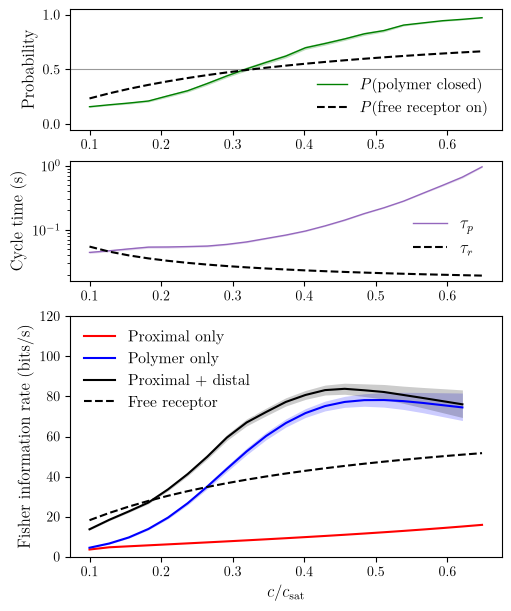

In [454]:
# -----------------------------------------------------------------------------------------
# 5. Figure
# -----------------------------------------------------------------------------------------
plt.rcParams.update({"text.usetex": True, "font.family": "serif"})
xticks = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])

# every curve is drawn over the concentrations that were analysed (enough cycles); the
# trend lines connect the resolved points, across an occasional unresolved one
analysed = np.isfinite(fpoly_vs_phi["cycle_time"])
c_over_csat = phi_points[analysed] / binodal
polymer_has_trend = np.isfinite(polymer["fit"])
total_has_trend = np.isfinite(local_vs_phi["fit"])

fig, ax = plt.subplots(3, 1, figsize=(5.0, 6), gridspec_kw={"height_ratios": [1, 1, 2]},
                       layout="constrained")

# ---- top: closed probability of the polymer vs bound probability of a free receptor ----
p_closed_mean, p_closed_se = p_closed[analysed], fpoly_vs_phi["p_closed_se"][analysed]
ax[0].plot(c_over_csat, p_closed_mean, color="green", lw=1.0, label=r"$P($polymer closed$)$")
ax[0].fill_between(c_over_csat, p_closed_mean - p_closed_se, p_closed_mean + p_closed_se,
                   color="green", alpha=0.25, lw=0)
ax[0].plot(c_over_csat, p_free_undersat[:n_points][analysed], linestyle="dashed", color="black",
           label=r"$P( $free receptor on$)$")
ax[0].axhline(0.5, lw=0.8, color="black", alpha=0.4)
ax[0].set_ylabel(r"Probability", fontsize=12)
ax[0].set_ylim(-0.05, 1.05)
ax[0].set_yticks([0.0, 0.5, 1.0])
ax[0].legend(fontsize=11, edgecolor="none", loc="lower right")

# ---- middle: polymer cycle time vs free-receptor cycle time ----
cycle_time, cycle_time_se = fpoly_vs_phi["cycle_time"][analysed], fpoly_vs_phi["cycle_time_se"][analysed]
ax[1].plot(c_over_csat, cycle_time, color="C4", lw=1.0, label=r"$\tau_{p}$")
ax[1].fill_between(c_over_csat, cycle_time - cycle_time_se, cycle_time + cycle_time_se,
                   color="C4", alpha=0.25, lw=0)
ax[1].plot(c_over_csat, tau_free[:n_points][analysed], linestyle="dashed", color="black", label=r"$\tau_{r}$")
ax[1].set_ylabel("Cycle time (s)", fontsize=12)
ax[1].set_yscale("log")
ax[1].legend(fontsize=12, edgecolor="none", loc=(0.78, 0.15))

# ---- bottom: Fisher information rates ----
c_polymer, c_total = phi_points[polymer_has_trend] / binodal, phi_points[total_has_trend] / binodal
ax[2].plot(c_over_csat, rate_open[analysed], color="red", label="Proximal only")
ax[2].plot(c_polymer, polymer["fit"][polymer_has_trend], color="blue", label="Polymer only")
ax[2].fill_between(c_polymer, *polymer["band"][:, polymer_has_trend], color="blue", alpha=0.2, lw=0)
ax[2].plot(c_total, local_vs_phi["fit"][total_has_trend], color="black", label="Proximal + distal")
ax[2].fill_between(c_total, *local_vs_phi["band"][:, total_has_trend], color="black", alpha=0.2, lw=0)
ax[2].plot(c_over_csat, fisher_rate_free[:n_points][analysed], color="black", linestyle="dashed",
           label=r"Free receptor")
ax[2].set_ylabel("Fisher information rate (bits/s)", fontsize=12)
ax[2].set_xlabel(r"$c/c_{\rm sat}$", fontsize=12)
# in the empty space between the free-receptor line and the polymer curves
ax[2].legend(fontsize=11.3, loc="upper left",  edgecolor="none", ncol=1)
ax[2].set_ylim(0, 120)

xticks = xticks[xticks <= c_over_csat.max() + 0.05]       # no ticks beyond the analysed range
for axis in ax:
    axis.set_xticks(xticks)
    axis.set_xticklabels(xticks)

In [328]:
out_dir = "media/figures/20261014"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "allFs_tau_rouse.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261014/allFs_tau_rouse.pdf


#### Local Fisher rates

Text(0.5, 0, 'Concentration $c$')

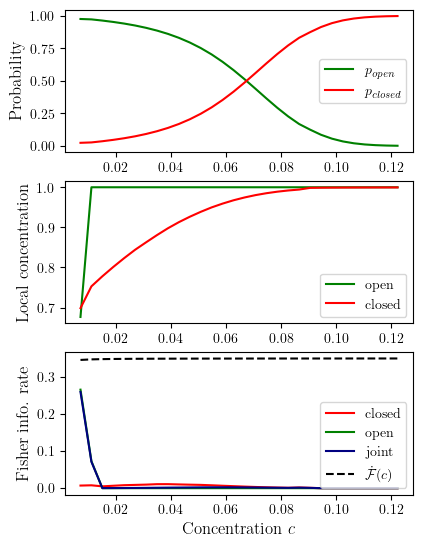

In [446]:
fig, ax = plt.subplots(3,1,figsize=(4.5, 6.3))

p_closed = mfpt_esc / (mfpt_esc + mfpt_ret)
p_open = mfpt_ret / (mfpt_esc + mfpt_ret)

# a = 1        # um
# D_tf = 1      # um^2/s
# kb = 4*a*D_tf 
# ku = 5e-1
# tau_base = 1 / (kb*phi_infs[:-2]) + 1 / ku

tau_closed = 1 / (kb*phi_local_vals) + 1 / ku
tau_open = 1 / (kb*phi_surf_vals[:,0]) + 1 / ku
phi_local_gain = (dphi_local_vals * phi_infs[0:-2] / phi_local_vals) ** 2
phi_surf_gain = (dphi_surf_vals * phi_infs[0:-2] / phi_surf_vals[:,0]) ** 2

fisher_rate_closed = phi_local_gain / tau_closed
fisher_rate_open = phi_surf_gain / tau_open
fisher_rate_base = 1 / tau_base

K = 1
fisher_rate_total = (
    fisher_rate*K + p_closed*fisher_rate_closed + p_open*fisher_rate_open
)

ax[0].plot(phi_infs[:-2], p_open, label=r"$p_{open}$", color="green")
ax[0].plot(phi_infs[:-2], p_closed, label=r"$p_{closed}$", color="red")
ax[0].legend()
# ax[0].set_title(r"$D_{TF} = 100D_{enhancer}$")
ax[0].set_ylabel("Probability", fontsize=12)

ax[1].plot(phi_infs[:-2], phi_surf_vals[:,0], color="green", label="open")
ax[1].plot(phi_infs[:-2], phi_local_vals, color="red", label="closed")
# ax[1].plot(phi_infs[:-2], p_closed*phi_local_vals+p_open*phi_surf_vals[:,0], 
#            color="navy", label="joint")
ax[1].set_ylabel("Local concentration", fontsize=12)
# ax[1].set_yscale('log')
# ax[1].set_xscale('log')
ax[1].legend()

# ax[2].plot(phi_infs[0:-2], fisher_rate*K, 
#         label=r"$\dot{F}_{poly}$", color="green")
ax[2].plot(phi_infs[0:-2], fisher_rate_closed, label=r"closed", color="red")
ax[2].plot(phi_infs[0:-2], fisher_rate_open, label=r"open", color="green")
ax[2].plot(phi_infs[0:-2], p_closed*fisher_rate_closed+p_open*fisher_rate_open, 
        label=r"joint", color="navy")
ax[2].plot(phi_infs[:-2], fisher_rate_base, color="black", linestyle="dashed",
           label=r"$\dot{\mathcal{F}}(c)$")
# ax[2].plot(phi_infs[0:-2], fisher_rate_total, 
#         label=r"$\dot{F}_{total}$", color="black", alpha=0.4)
# ax[1].plot(phi_infs[0:-2], fisher_rate_2)
# ax[2].set_yscale("log")
ax[2].set_ylabel("Fisher info. rate", fontsize=12)
ax[2].legend(fontsize=10, loc="lower right")
ax[2].set_xlabel("Concentration $c$", fontsize=12)
# ax[2].set_ylim(-0.5, 3)

In [73]:
out_dir = "media/figures/20260726"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "F_local_linear_potential.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260726/F_local_linear_potential.pdf


### Fisher rate versus genomic separation

ridge (closed/open split) exists for 62/64 bead counts, s >= 37
p_open at s = 305: 1.009e-03   (grid out to x = 5060)


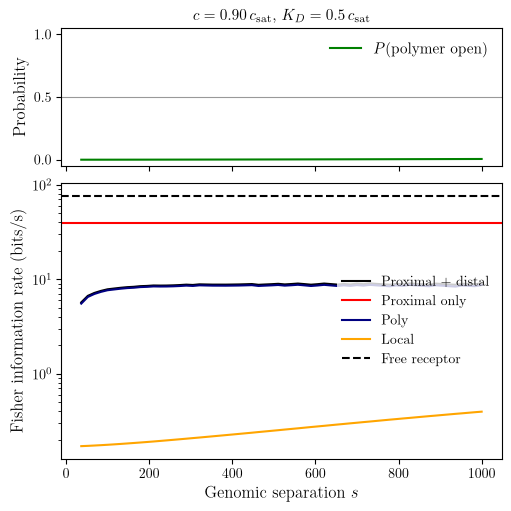

In [322]:
import json
import numpy as np
import matplotlib.pyplot as plt

# Fisher rate vs the Rouse bead count s, at the ONE concentration the sweep was run
# at: sweep_rouse_s.jl varies rouse.s and reports a single phi_inf per run, so every
# quantity below is a curve in s, not in c.
#
# CONSISTENT WITH THE c-FIGURE ABOVE, which it reuses rather than re-deriving:
# kb, ku, K_D, v_tf, binodal, phi_inf, phi_full (receptor + single-sphere) and `coef`
# (the MFPT time-unit factor).  Its own s-indexed arrays all carry an _s suffix so
# running this cell cannot clobber the concentration figure's globals.
# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04_clone/fisher_vs_rouse_s.json"
path = "data/20260912/test3_clone/fisher_vs_rouse_s.json"
d = json.load(open(path))

runs = sorted(d["runs"], key=lambda r: r["s"])          # ascending in s
s    = np.array([r["s"] for r in runs])
j    = 0                                                # the sweep's single concentration
phi_sweep       = np.array(runs[0]["phi_infs"])[j]
mfpt_esc_s      = np.array([r["escape_mfpt"] for r in runs])[:, j] * coef
mfpt_ret_s      = np.array([r["return_mfpt"] for r in runs])[:, j] * coef
fisher_poly_s   = np.array([r["fisher"]      for r in runs])[:, j]
fisher_esc_s    = np.array([r["fisher_esc"]  for r in runs])[:, j]
fisher_ret_s    = np.array([r["fisher_ret"]  for r in runs])[:, j]
phi_closed_s    = np.array([r["phi_local"]   for r in runs])[:, j]
dphi_closed_s   = np.array([r["dphi_local"]  for r in runs])[:, j]

i_phi = int(np.argmin(np.abs(phi_inf - phi_sweep)))     # sweep's slot on the c-grid
assert np.isclose(phi_inf[i_phi], phi_sweep, rtol=1e-9), "sweep phi_inf is off the BVP grid"

#### Poly

# ---- equilibrium open/closed probabilities from the 1D potential -----------
# Same Boltzmann split as the c-figure (it reproduces its p_closed to 3e-7 at s=100),
# except U_tot has to be REBUILT at every s: bvp_potential_interp.jl only ever wrote
# U_tot_full at one PARAMS.rouse.s, and both the radial jacobian and the Rouse spring
# move with s.  The ridge goes with it, so it is located here (first + -> - crossing
# of dU/dx) instead of read from the FPT json.  Below s* there is no ridge at all --
# no closed/open split -- and those s drop out as NaN.
#
# Two things this file is NOT safe to index naively: sweep_rouse_s.jl rewrites it once
# per s, so what is on disk is the LAST iteration -- only the 3-phi bracket, on that
# s's grid.  So the phi row is found by value, and U_ads is resampled onto a grid of
# this cell's own choosing: out to the largest 4a*sqrt(s) (past the BVP grid U_ads is
# 0 to <5e-3; truncating there instead costs 25% of p_open at s=1000) and fine enough
# to resolve the contact well (that file's own 3.4-site spacing loses another 25%;
# p_open is converged to ~1% by dx = 0.25).
beta = 1.0

INTERP_JSON_S = "data/20260912/test3_clone/bvp_potential_interp.json"
D_s = load_bvp_interp(INTERP_JSON_S)       # pass it: the default arg is bound at def time

a_rouse = D_s["params"]["rouse"]["a"]
i_bvp   = int(np.argmin(np.abs(D_s["phi_inf"] - phi_sweep)))
assert np.isclose(D_s["phi_inf"][i_bvp], phi_sweep, rtol=1e-9), "no BVP row at the sweep's phi_inf"

dx  = 0.25                                  # sites; the contact well needs ~1 site or finer
x_g = np.arange(D_s["x_grid"][0], 4*a_rouse*np.sqrt(s.max()) + dx, dx)
U_g = np.interp(x_g, D_s["x_grid"], D_s["U_full_interp"][i_bvp], right=0.0)

p_closed_s = np.full(s.size, np.nan)
p_open_s   = np.full(s.size, np.nan)
x_ridge_s  = np.full(s.size, np.nan)

for i, s_i in enumerate(s):
    U = U_g - 2*np.log(x_g/(a_rouse*np.sqrt(s_i))) + 3*x_g**2/(2*s_i*a_rouse**2)
    F = np.gradient(U, x_g)
    top = np.flatnonzero((F[:-1] > 0) & (F[1:] <= 0))   # + -> - crossing = the ridge
    if top.size == 0:
        continue                                        # s < s*: outer well not born yet
    k = top[0]
    w = np.exp(-beta * (U - U.min()))                   # shift for stability
    p_closed_s[i] = np.trapezoid(w[:k+1], x_g[:k+1]) / np.trapezoid(w, x_g)
    p_open_s[i]   = 1.0 - p_closed_s[i]
    x_ridge_s[i]  = x_g[k]

tau_poly_s = mfpt_esc_s / p_closed_s
fisher_rate_poly_s = fisher_esc_s / tau_poly_s   # fisher_* are per CYCLE, not rates

#### Local

c_open_s   = to_nM(phi_full[i_phi, 0], v_tf)*1e-24*6.022e23     # single-sphere surface conc
c_closed_s = to_nM(phi_closed_s, v_tf)*1e-24*6.022e23
tau_burst_open_s   = 1 / (kb*c_open_s) + 1 / ku
tau_burst_closed_s = 1 / (kb*c_closed_s) + 1 / ku
dphi_open_s = np.gradient(phi_full[:, 0], phi_inf)[i_phi]
phi_open_gain_s   = (dphi_open_s * phi_sweep / phi_full[i_phi, 0]) ** 2
phi_closed_gain_s = (dphi_closed_s * phi_sweep / phi_closed_s) ** 2

fisher_rate_open_s   = phi_open_gain_s / tau_burst_open_s      # s-independent: proximal only
fisher_rate_closed_s = phi_closed_gain_s / tau_burst_closed_s
fisher_rate_local_s  = p_open_s*fisher_rate_open_s + p_closed_s*fisher_rate_closed_s
fisher_rate_free_s   = 1 / (1 / (kb*to_nM(phi_sweep, v_tf)*1e-24*6.022e23) + 1 / ku)

#### Plot

fig, ax = plt.subplots(2, 1, figsize=(5.0, 5.0), sharex=True,
        gridspec_kw={"height_ratios": [1, 2]}, layout="constrained")

ax[0].plot(s, p_open_s, color="green", label=r"$P($polymer open$)$")
ax[0].axhline(0.5, lw=0.8, color="black", alpha=0.4)
ax[0].set_ylabel(r"Probability", fontsize=12)
insticks = np.array([0.0, 0.5, 1.0])
ax[0].set_ylim(-0.05, 1.05)
ax[0].set_yticks(insticks)
ax[0].set_yticklabels(insticks)
ax[0].legend(fontsize=11, edgecolor="none")
ax[0].set_title(rf"$c = {phi_sweep/binodal[0]:.2f}\,c_{{\rm sat}}$,  "
                rf"$K_D = {K_D_frac}\,c_{{\rm sat}}$", fontsize=11)

ax[1].plot(s, fisher_rate_poly_s + fisher_rate_local_s, color="black",
           label="Proximal + distal")
ax[1].axhline(fisher_rate_open_s, color="red", label="Proximal only")
ax[1].plot(s, fisher_rate_poly_s, color="navy", label="Poly")
ax[1].plot(s, fisher_rate_local_s, color="orange", label="Local")
ax[1].axhline(fisher_rate_free_s, linestyle="dashed", color="black", label="Free receptor")
ax[1].set_ylabel("Fisher information rate (bits/s)", fontsize=12)
ax[1].set_xlabel("Genomic separation $s$", fontsize=12)
ax[1].set_yscale("log")
ax[1].legend(fontsize=10.0, loc="center right", edgecolor="none")

ok = np.isfinite(p_closed_s)
k300 = int(np.argmin(np.abs(s - 300)))
print(f"ridge (closed/open split) exists for {ok.sum()}/{s.size} bead counts, s >= {s[ok][0]:.0f}")
print(f"p_open at s = {s[k300]:.0f}: {p_open_s[k300]:.3e}   (grid out to x = {x_g[-1]:.0f})")


In [525]:
out_dir = "media/figures/20260831"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_vs_s.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260831/fisher_vs_s.pdf


In [218]:
# load rouse vs. s data

import json, glob, os
import numpy as np

# ---- Rouse escape/return FPTs vs s, independent runs pooled, every concentration ---------
# Layout <root>/<run>/<cond>/s<s>/ holding rouse/output_cpu*.json and that s's
# fisher_rate_from_fpt_solver.json (data/20261013: run2-4, conditions high_c and low_c,
# each the outer phi pair of its bracket).  Single-run roots (20261009, 20261012) have no
# <run>/<cond> level and load as one run under the condition "all".  Per condition:
#   rouse_s[cond]["data"][s][phi]   = list of the Rouse runs at that phi, one dict per
#                                     independent run, same layout as `data` in "Comparison
#                                     with Rouse simulation" (escape_times / return_times in
#                                     SECONDS, no coef)
#   rouse_s[cond]["fisher"][s]      = that s's fisher_rate_from_fpt_solver.json, from the
#                                     first run (the 1D reduction is s-dependent: Rouse
#                                     spring + radial jacobian move with s)
#   rouse_s[cond]["solver"][s][phi] = its per_phi record at the Rouse concentration
#   rouse_s[cond]["s"], ["phi"]     = the s values and the phi bracket
# The _s suffix keeps `data`, `solver`, `phi_rouse`, ... above intact.
# _root = "data/20261009"
# _root = "data/20261012"
_root   = "data/20261013"
_conds  = sorted({os.path.basename(p) for p in glob.glob(f"{_root}/run*/*") if os.path.isdir(p)})
_runs_c = {c: sorted(glob.glob(f"{_root}/run*/{c}")) for c in _conds} or {"all": [_root]}
rouse_s = {}
for _cond, _runs in _runs_c.items():
    _data, _fisher, _solver = {}, {}, {}
    for _rdir in _runs:
        for _dir in sorted(glob.glob(f"{_rdir}/s[0-9]*")):
            _paths = sorted(glob.glob(f"{_dir}/rouse/output_cpu*.json"))
            _s = int(os.path.basename(_dir)[1:])
            if not _paths or _s > 600:
                continue
            for _path in _paths:
                with open(_path) as _f:
                    _raw = json.load(_f)
                for _keya in _raw:
                    for _run in _raw[_keya].values():
                        _data.setdefault(_s, {}).setdefault(_run["alpha"], []).append(_run)
            if _s not in _fisher:
                with open(f"{_dir}/fisher_rate_from_fpt_solver.json") as _f:
                    _fisher[_s] = json.load(_f)
                _per_phi = {r["phi_inf"]: r for r in _fisher[_s]["per_phi"]}
                _solver[_s] = {a: _per_phi[min(_per_phi, key=lambda p: abs(p - a))] for a in _data[_s]}

    _svals = np.array(sorted(_data))
    _phis  = np.array(sorted(_data[_svals[0]]))                # the phi bracket (2 or 3 phi)
    for _s in _svals:
        assert np.allclose(sorted(_data[_s]), _phis, rtol=1e-12), f"{_cond} s={_s}: different phi bracket"
        for a in _phis:
            assert np.isclose(_solver[_s][a]["phi_inf"], a, rtol=1e-9), f"{_cond} s={_s}: no solver row at phi={a:.4e}"
            # provenance, as in "Comparison with Rouse simulation": every run must have used
            # the x_div of the solver json
            for _run in _data[_s][a]:
                if not np.isclose(_run["x_div"], _fisher[_s]["x_div"], rtol=1e-9):
                    print(f"WARNING {_cond} s={_s} phi={a:.4e}: rouse x_div={_run['x_div']:.4f}, "
                          f"solver json x_div={_fisher[_s]['x_div']:.4f} -- potentials differ")
        # pooled runs must be independent: a repeated seed replays the same trajectory
        _seeds = [r["rouse_params"]["seed"] for a in _phis for r in _data[_s][a]]
        if len(set(_seeds)) < len(_seeds):
            print(f"WARNING {_cond} s={_s}: repeated seeds {sorted(_seeds)} -- those runs are not independent")
    rouse_s[_cond] = dict(data=_data, fisher=_fisher, solver=_solver, s=_svals, phi=_phis)

    print(f"\n{_cond}: {len(_runs)} run(s) in {_root}:  s = {_svals.tolist()}   "
          f"phi_inf = [{', '.join(f'{a:.4e}' for a in _phis)}]")
    print("  s   phi_inf    runs   n_esc   n_ret  t_total[s]   MFPT_esc rouse/solver   MFPT_ret rouse/solver")
    for _s in _svals:
        for a in _phis:
            _rs, _rec = _data[_s][a], _solver[_s][a]
            _te = np.concatenate([r["escape_times"] for r in _rs])
            _tr = np.concatenate([r["return_times"] for r in _rs])
            _re = f"{_te.mean()/_rec['escape_mfpt']:6.2f}" if _te.size else "   ---"
            _rr = f"{_tr.mean()/_rec['return_mfpt']:6.2f}" if _tr.size else "   ---"
            print(f"{_s:4d}  {a:.4e}  {len(_rs):3d}  {_te.size:7d} {_tr.size:7d}  "
                  f"{sum(r['rouse_params']['t_total'] for r in _rs):9.3g}"
                  f"   {_re}  ({_rec['escape_mfpt']:.3g} s)      {_rr}  ({_rec['return_mfpt']:.3g} s)")


high_c: 3 run(s) in data/20261013:  s = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500, 550, 600]   phi_inf = [1.3848e-04, 1.5618e-04]
  s   phi_inf    runs   n_esc   n_ret  t_total[s]   MFPT_esc rouse/solver   MFPT_ret rouse/solver
  50  1.3848e-04    3    18078   18080         35     1.70  (0.00112 s)        1.85  (1.89e-05 s)
  50  1.5618e-04    3    10655   10657       35.5     1.68  (0.00196 s)        1.78  (1.82e-05 s)
 100  1.3848e-04    3    23705   23705       29.3     1.76  (0.000656 s)        1.85  (4.28e-05 s)
 100  1.5618e-04    3    14261   14264       29.1     1.73  (0.00114 s)        1.80  (4.1e-05 s)
 150  1.3848e-04    3    21809   21812       24.3     1.78  (0.000555 s)        1.77  (7.06e-05 s)
 150  1.5618e-04    3    13408   13410       24.1     1.75  (0.000957 s)        1.82  (6.76e-05 s)
 200  1.3848e-04    3    19729   19732       21.9     1.82  (0.000508 s)        1.83  (0.000101 s)
 200  1.5618e-04    3    12649   12652       21.7     1.76  (0.000874 s)   

In [315]:
# compute Fpoly (rouse) vs s

# =========================================================================================
#  Polymer Fisher information rate F_poly(s) from the Rouse simulations
# =========================================================================================
#
# For every genomic separation s and both concentration brackets loaded above (high_c and
# low_c), estimate how much information the polymer's escape and return sojourns carry
# about the bulk concentration: the information per cycle J and the Fisher rate
# F = J / cycle_time, with bootstrap errors and a smooth trend along s.
#
# The estimator lives in viz_util/rouse_fisher.py (shared with the concentration figure,
# cell 118); its docstring explains the method step by step.  In short: the score
# d log P(t | phi) / d phi is a finite difference between raw sojourn-time histograms at the
# OUTER pair of the bracket (phi_base, phi_plus), cross-fitted, with the counting-noise floor
# subtracted; errors come from a block bootstrap of the whole calculation.
#
# INPUT   rouse_s[condition] from the loader (cell 126); condition is "high_c" or "low_c".
# OUTPUT  fpoly_results[condition]: the dict documented in rouse_fisher.analyse_sweep, plus
#             s                    the genomic separations (the swept variable)
#             phi_base, phi_plus   the two concentrations of the bracket (single numbers here,
#                                  since they are the same at every s)

import importlib
import numpy as np
from viz_util import rouse_fisher
importlib.reload(rouse_fisher)            # pick up edits to the module without restarting

# -----------------------------------------------------------------------------------------
# Settings (see rouse_fisher.FisherSettings for the meaning of each)
# -----------------------------------------------------------------------------------------
fisher_settings = rouse_fisher.FisherSettings(
    time_rescale=100,            # simulated seconds -> plotting time units (= `coef`, cell 97)
    n_histogram_bins=40,
    min_cycles_per_phi=300,
    n_folds=5,
    block_length=50,
    n_bootstrap=200,
    n_permutations=50,
    min_signal_to_noise=3,
    seed=20261013,
)

# -----------------------------------------------------------------------------------------
# Run for every concentration bracket
# -----------------------------------------------------------------------------------------
fpoly_results = {}
for condition_name, condition in rouse_s.items():
    s_values = condition["s"]
    phi_base, phi_plus = condition["phi"][0], condition["phi"][-1]     # outer pair of the bracket
    print(f"\n==================== {condition_name} ====================")
    print(f"phi_base = {phi_base:.4e}, phi_plus = {phi_plus:.4e}")

    # one concentration pair per s: the Rouse runs and the 1D-solver records at both phi
    pairs = [dict(runs_base=condition["data"][s][phi_base], runs_plus=condition["data"][s][phi_plus],
                  solver_base=condition["solver"][s][phi_base], solver_plus=condition["solver"][s][phi_plus],
                  phi_base=phi_base, phi_plus=phi_plus)
             for s in s_values]

    results = rouse_fisher.analyse_sweep(s_values, pairs, fisher_settings, x_name="s")
    results.update(s=s_values, phi_base=phi_base, phi_plus=phi_plus)
    fpoly_results[condition_name] = results


==================== high_c ====================
phi_base = 1.3848e-04, phi_plus = 1.5618e-04
3 run(s) pooled; 40 equal-count bins

         s cycles             cycle time |                     escape                      |                     return                     
             base   plus     mean     SE | floor       J   J_1D  SE_J       F  SE_F | floor       J   J_1D  SE_J       F  SE_F
        50  18078  10655   0.1936  0.008 |  0.03  11.263  12.51 0.053   58.18 0.057 |  0.73     nan   0.15   nan     nan   nan
       100  23705  14261   0.1235  0.007 |  0.03   9.991  12.07 0.045   80.93 0.049 |  0.41     nan   0.13   nan     nan   nan
       150  21809  13408   0.1113  0.007 |  0.03   9.077  11.91 0.048   81.55 0.051 |  0.94     nan   0.12   nan     nan   nan
       200  19729  12649   0.1111  0.009 |  0.04   8.426  11.81 0.058   75.82 0.062 |  0.71     nan   0.12   nan     nan   nan
       250  17585  11709   0.1140  0.010 |  0.04   8.165  11.76 0.063   71.63 0.066 |  0.95

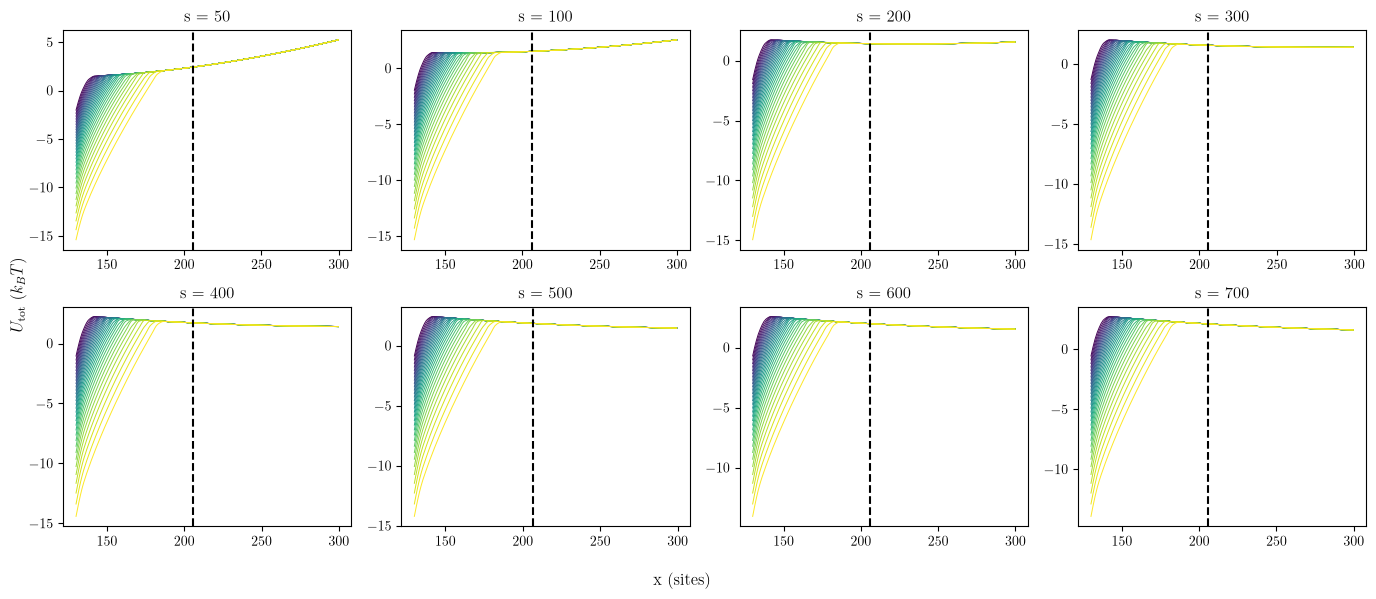

In [79]:
import json
import numpy as np
import matplotlib.pyplot as plt

# U_tot = BVP attraction + Rouse spring + jacobian, every phi (dark -> light = low -> high);
# dashed = new x_div = 1.2 x where the largest-phi attraction flattens (|dU/dx| < 1e-3)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, s in zip(axes.flat, [50, 100, 200, 300, 400, 500, 600, 700, 800]):
    d = json.load(open(f"data/20261012/s{s}/bvp_potential_interp.json"))
    x, U = np.array(d["x_grid"]), np.array(d["U_tot_full"], float)
    Ua = np.array(d["U_full_interp"][np.argmax(d["phi_inf"])], float)
    m = x < 300
    ax.set_prop_cycle(color=plt.cm.viridis(np.linspace(0, 1, len(U))))
    ax.plot(x[m], U[:, m].T, lw=0.7)
    ax.axvline(1.1 * x[np.argmax(np.abs(np.diff(Ua) / np.diff(x)) < 1e-3)], color="k", ls="--")
    ax.set_title(f"s = {s}")
fig.supxlabel("x (sites)"); fig.supylabel(r"$U_{\rm tot}$ ($k_BT$)")
plt.tight_layout()

In [316]:
#### Local fisher rate

#### load single sphere data

path = "data/20261013/demo_bvp_profiles.json"   # test3 itself has no demo run
d = json.load(open(path))
phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_solver"])             # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
h0 = d["params"]["surface"]["omega_b"]
binodal = d["binodal"]
chi = d["chi"]

high_c_idx = 12
low_c_idx = 2

assert np.abs(np.max(
    [_fisher[_s]["per_phi"][i]['phi_surf'][-1]/phi_full[i, 0] for i in range(30)]) - 1) < 1e-2

#### Free receptor

v_tf  = 120      # 120 <-> nb = 4000
a_rec = 3e-3     # um / 10 bp -- receptor radius, NOT the Rouse kuhn length `a`
D_tf  = 7.4      # um^2/s
kb = 4*a_rec*D_tf   # um^3/s
K_D_frac = 0.325
K_D = K_D_frac*to_nM(binodal, v_tf)*1e-24*6.022e23
# kb = 2 / (5*60*K_D)   # such that tau_b = 5 minutes at c = K_D
ku = kb*K_D
c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3

tau_free = 1 / (kb*c_inf) + 1 / ku
p_free_undersat = kb*c_inf / (kb*c_inf + ku)
fisher_rate_free = 1 / tau_free

#### Poly

#### Local

## open
phi_open = phi_full.T[0,:]
c_open = to_nM(phi_open, v_tf)*1e-24*6.022e23
tau_burst_open = 1 / (kb*c_open) + 1 / ku
dphi_open = np.gradient(phi_open, phi_inf)
phi_open_gain = (dphi_open * phi_inf / phi_open) ** 2
phi_open_gain_hic = phi_open_gain[high_c_idx]
phi_open_gain_lowc = phi_open_gain[low_c_idx]

fisher_rate_open = phi_open_gain / tau_burst_open

## closed
s_rouse = rouse_s["low_c"]["s"]
phi_closed_s_hic = np.array([_fisher[_s]["per_phi"][high_c_idx]["phi_local"] for _s in s_rouse])
phi_closed_s_lowc = np.array([_fisher[_s]["per_phi"][low_c_idx]["phi_local"] for _s in s_rouse])
dphi_closed_s_hic = np.array([_fisher[_s]["per_phi"][high_c_idx]["dphi_local"] for _s in s_rouse])
dphi_closed_s_lowc = np.array([_fisher[_s]["per_phi"][low_c_idx]["dphi_local"] for _s in s_rouse])
phi_closed_gain_hic = (dphi_closed_s_hic * phi_inf[high_c_idx] / phi_closed_s_hic) ** 2
phi_closed_gain_lowc = (dphi_closed_s_lowc * phi_inf[low_c_idx] / phi_closed_s_lowc) ** 2

hic_closed = to_nM(phi_closed_s_hic, v_tf)*1e-24*6.022e23
lowc_closed = to_nM(phi_closed_s_lowc, v_tf)*1e-24*6.022e23
tau_burst_closed_hic = 1 / (kb*hic_closed) + 1 / ku
tau_burst_closed_lowc = 1 / (kb*lowc_closed) + 1 / ku

fisher_rate_closed_hic = phi_closed_gain_hic / tau_burst_closed_hic
fisher_rate_closed_lowc = phi_closed_gain_lowc / tau_burst_closed_lowc

## local
# fisher_rate_local = p_open*fisher_rate_open[:-7] + p_closed*fisher_rate_closed[:-5]

low_c: s* = 83.74  (the ridge appears at x = 146.3; phi = 4.9979e-05)
high_c: s* = 91.31  (the ridge appears at x = 154.4; phi = 1.3848e-04)


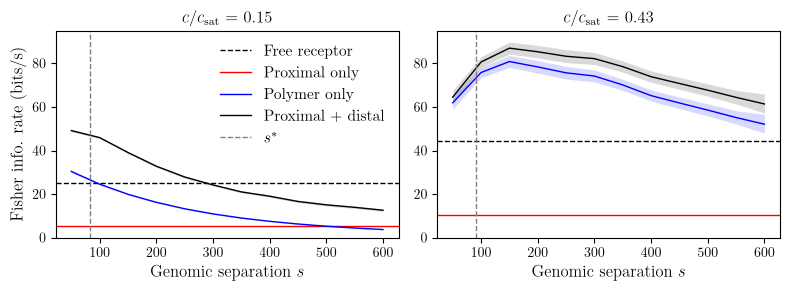


                          low_c                      |                     high_c                     
   s p_closed       F_local       F_poly      F_total | p_closed       F_local       F_poly      F_total
  50    0.817  18.77+-0.01   30.9+- 0.8   49.6+- 0.8 |    0.982   2.61+-0.00   58.2+- 3.3   60.8+- 3.3
 100    0.558  21.38+-0.07   24.0+- 0.8   45.4+- 0.8 |    0.936   4.83+-0.01   80.9+- 4.0   85.8+- 4.0
 150    0.406  19.18+-0.12   19.3+- 0.8   38.4+- 0.8 |    0.887   6.14+-0.01   81.5+- 4.2   87.7+- 4.2
 200    0.306  16.58+-0.16   17.5+- 0.8   34.1+- 0.8 |    0.833   6.95+-0.02   75.8+- 4.7   82.8+- 4.7
 250    0.239  14.59+-0.24   12.5+- 0.7   27.0+- 0.7 |    0.773   7.61+-0.03   71.6+- 4.8   79.2+- 4.8
 300    0.201  13.30+-0.21   11.1+- 0.7   24.3+- 0.7 |    0.728   8.00+-0.03   79.7+- 5.7   87.7+- 5.7
 350    0.164  12.00+-0.24    8.4+- 0.7   20.4+- 0.7 |    0.674   8.40+-0.04   70.6+- 5.2   79.0+- 5.2
 400    0.150  11.53+-0.27    7.5+- 0.7   19.0+- 0.7 |    0.615   8.69

In [330]:
# =========================================================================================
#  Receptor Fisher information rate vs s, at low and high concentration
# =========================================================================================
#
# Each panel compares three ways the receptor can sense the bulk concentration:
#   free receptor       (black, dashed)  no condensate and no polymer
#   proximal only       (red)            the receptor sits in the condensate film on its own
#                                        sphere (local condensation); the polymer is ignored
#   proximal + distal   (black)           F_poly + F_local, where
#       F_poly   is the information carried by the polymer's escape/return cycles (cell 127)
#       F_local  is the receptor's own rate averaged over the two polymer states, each
#                weighted by its equilibrium occupancy (as in cell 118):
#                    F_local  = p_open * F_open + p_closed * F_closed(s)
#                    p_closed = tau_closed / (tau_closed + tau_open)
#                with tau_closed = mean escape time and tau_open = mean return time (cell 127)
#
# ERROR BARS
#   F_local depends on the data only through p_closed, so its error is
#   |F_closed - F_open| * SE(p_closed), with SE(p_closed) from cell 127's bootstrap (which
#   includes the covariance between the escape and return times).  F_poly and F_local both
#   move with the same two mean times, so the error of their sum is taken from the SAME
#   bootstrap replicates of both, not by adding the two errors in quadrature.
#
# s* (gray dashed line)
#   The smallest genomic separation at which the total potential U_tot(x) has a local
#   maximum (the ridge) at that panel's concentration.  U_tot is rebuilt from the BVP
#   attraction exactly as bvp_potential_interp.jl:394 builds U_tot_full,
#       U_tot(x; s) = U_attraction(x) - 2 ln(x / (a sqrt s)) + 3 x^2 / (2 s a^2),
#   but on a continuum of s instead of the Rouse runs' steps of 50.
#
# INPUTS  rouse_s and the run directories (_runs_c) from the loader (cell 126);
#         fpoly_results (cell 127);
#         fisher_rate_free, fisher_rate_open, fisher_rate_closed_lowc / _hic, low_c_idx,
#         high_c_idx, phi_inf, binodal, s_rouse (cell 129).
# OUTPUT  local_results[condition], s_star[condition], and the figure `fig` (saved by the
#         next cell).

# -----------------------------------------------------------------------------------------
# Settings
# -----------------------------------------------------------------------------------------
panel_order = ["low_c", "high_c"]          # left panel, right panel
show_polymer_inset = False                 # inset with F_poly alone (points, trend, band)
inset_position = {"low_c": [0.50, 0.50, 0.46, 0.42],     # [left, bottom, width, height]
                  "high_c": [0.47, 0.28, 0.50, 0.25]}    # in fractions of the panel

# The receptor rates of cell 129, per condition
receptor_inputs = {
    "low_c":  dict(phi_index=low_c_idx,  rate_closed=fisher_rate_closed_lowc),
    "high_c": dict(phi_index=high_c_idx, rate_closed=fisher_rate_closed_hic),
}


# -----------------------------------------------------------------------------------------
# 1. s*: the smallest s at which U_tot has a ridge
# -----------------------------------------------------------------------------------------
def first_ridge_position(x, attraction, s, kuhn_length):
    """x of the first local maximum of U_tot(x) at genomic separation s, or None.

    U_tot = attraction + radial Jacobian + Rouse spring, as in bvp_potential_interp.jl.
    A local maximum is where the slope dU_tot/dx changes sign from + to -.
    """
    jacobian = -2 * np.log(x / (kuhn_length * np.sqrt(s)))
    spring = 3 * x**2 / (2 * s * kuhn_length**2)
    slope = np.gradient(attraction + jacobian + spring, x)
    sign_change = np.flatnonzero((slope[:-1] > 0) & (slope[1:] <= 0))
    return x[sign_change[0]] if sign_change.size else None


def ridge_onset(x, attraction, kuhn_length, s_max, tolerance=0.01):
    """The smallest s in [1, s_max] at which U_tot has a ridge, found by bisection.

    A larger s only weakens the spring, so once the ridge exists it exists for every larger
    s (checked on all integers s = 1..600 for 20261013); that is what bisection needs.
    """
    s_low, s_high = 1.0, float(s_max)
    if (first_ridge_position(x, attraction, s_low, kuhn_length) is not None
            or first_ridge_position(x, attraction, s_high, kuhn_length) is None):
        raise ValueError(f"the ridge does not first appear for s in [1, {s_max}]")
    while s_high - s_low > tolerance:
        s_middle = 0.5 * (s_low + s_high)
        if first_ridge_position(x, attraction, s_middle, kuhn_length) is None:
            s_low = s_middle
        else:
            s_high = s_middle
    return s_high


s_star = {}
for condition_name in panel_order:
    polymer = fpoly_results[condition_name]
    # The attraction is the same function at every s; the smallest s has the finest x-grid.
    smallest_s = int(polymer["s"].min())
    interp_file = f"{_runs_c[condition_name][0]}/s{smallest_s}/bvp_potential_interp.json"
    interp = json.load(open(interp_file))
    row = int(np.argmin(np.abs(np.array(interp["phi_inf"]) - polymer["phi_base"])))
    assert np.isclose(interp["phi_inf"][row], polymer["phi_base"], rtol=1e-9), \
        f"{condition_name}: {interp_file} has no U_full_interp row at phi_base"
    kuhn_length = interp["params"]["rouse"]["a"]
    attraction_on_file_grid = np.array(interp["U_full_interp"][row], float)

    # Fine x-grid out to the largest chain extent; past the BVP range the attraction is flat.
    x = np.linspace(interp["R"], 4 * kuhn_length * np.sqrt(polymer["s"].max()), 40_000)
    attraction = np.interp(x, interp["x_grid"], attraction_on_file_grid, right=attraction_on_file_grid[-1])

    s_star[condition_name] = ridge_onset(x, attraction, kuhn_length, polymer["s"].max())
    ridge_x = first_ridge_position(x, attraction, s_star[condition_name], kuhn_length)
    print(f"{condition_name}: s* = {s_star[condition_name]:.2f}  "
          f"(the ridge appears at x = {ridge_x:.1f}; phi = {polymer['phi_base']:.4e})")


# -----------------------------------------------------------------------------------------
# 2. Local and total Fisher rates
# -----------------------------------------------------------------------------------------
local_results = {}
for condition_name in panel_order:
    polymer = fpoly_results[condition_name]
    escape = polymer["escape"]                         # F_poly comes from the escape channel
    phi_index = receptor_inputs[condition_name]["phi_index"]
    rate_closed = receptor_inputs[condition_name]["rate_closed"]     # F_closed(s), one per s
    rate_open = fisher_rate_open[phi_index]                          # F_open, independent of s
    assert np.allclose(polymer["s"], s_rouse), "cell 129's closed rates are on a different s grid"
    assert np.isclose(phi_inf[phi_index], polymer["phi_base"], rtol=1e-9), \
        "cell 129's phi index does not match the concentration of cell 127"

    p_closed = polymer["p_closed"]
    rate_local = (1 - p_closed) * rate_open + p_closed * rate_closed
    # dF_local / dp_closed = F_closed - F_open, so the error of p_closed carries over linearly
    rate_local_se = np.abs(rate_closed - rate_open) * polymer["p_closed_se"]

    # The total, replicate by replicate (rate and p_closed replicates share their draws)
    p_closed_replicates = polymer["p_closed_bootstrap"]
    total_replicates = (escape["rate_bootstrap"]
                        + (1 - p_closed_replicates) * rate_open
                        + p_closed_replicates * rate_closed[:, None])

    local_results[condition_name] = dict(
        s=polymer["s"],
        rate_free=fisher_rate_free[phi_index], rate_open=rate_open, rate_closed=rate_closed,
        rate_local=rate_local, rate_local_se=rate_local_se,
        rate_total=escape["rate"] + rate_local,
        rate_total_se=total_replicates.std(axis=1, ddof=1),
        s_star=s_star[condition_name])


# -----------------------------------------------------------------------------------------
# 3. Figure
# -----------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.0))
for ax, condition_name in zip(axes, panel_order):
    polymer, local = fpoly_results[condition_name], local_results[condition_name]
    s_values = local["s"]
    has_trend = np.isfinite(polymer["escape"]["fit"])

    ax.axhline(local["rate_free"], color="black", ls="--", lw=1, label="Free receptor")
    ax.axhline(local["rate_open"], color="red", lw=1, label="Proximal only")
    ax.plot(s_values[has_trend], polymer["escape"]["fit"][has_trend], color="blue", lw=1, label="Polymer only")
    ax.fill_between(s_values[has_trend], *polymer["escape"]["band"][:, has_trend],
                           color="blue", alpha=0.15, lw=0)
    ax.plot(s_values[has_trend], polymer["escape"]["fit"][has_trend] + local["rate_local"][has_trend],
            color="black", lw=1, label="Proximal + distal")
    ax.fill_between(s_values[has_trend], 
        local["rate_local"][has_trend] + polymer["escape"]["band"][0, has_trend] - local["rate_local_se"][has_trend],
        local["rate_local"][has_trend] + polymer["escape"]["band"][1, has_trend] + local["rate_local_se"][has_trend],
        color="black", alpha=0.15, lw=0)
    ax.axvline(s_star[condition_name], color="gray", ls="--", lw=1, label=r"$s^*$")
    ax.set_xlabel("Genomic separation $s$", fontsize=12)
    ax.set_title(rf"$c/c_{{\rm sat}}$ = {polymer['phi_base'] / binodal:.2f}", fontsize=12)
    ax.set_ylim(0, 95)

    if show_polymer_inset:
        inset = ax.inset_axes(inset_position[condition_name])
        inset.errorbar(s_values, polymer["escape"]["rate"], yerr=polymer["escape"]["rate_se"],
                       fmt="o", ms=2, lw=0.6, capsize=1.5, color="C0")
        inset.plot(s_values[has_trend], polymer["escape"]["fit"][has_trend], color="C0", lw=0.8)
        inset.fill_between(s_values[has_trend], *polymer["escape"]["band"][:, has_trend],
                           color="C0", alpha=0.15, lw=0)
        inset.axvline(s_star[condition_name], color="gray", ls="--", lw=0.8)
        inset.set_title("Polymer only", fontsize=8, pad=2)
        inset.tick_params(labelsize=7)
    
axes[0].legend(loc="upper right", #bbox_to_anchor=(0.5, 1.0),
        ncol=1, fontsize=11.2, edgecolor="none")

axes[0].set_ylabel("Fisher info. rate (bits/s)", fontsize=12)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------------------
# 4. Table
# -----------------------------------------------------------------------------------------
print(f"\n{'':>4} " + " | ".join(f"{name:^47}" for name in panel_order))
print(f"{'s':>4} " + " | ".join([f"{'p_closed':>8} {'F_local':>13} {'F_poly':>12} {'F_total':>12}"] * len(panel_order)))
for i, s in enumerate(s_rouse):
    cells = []
    for name in panel_order:
        polymer, local = fpoly_results[name], local_results[name]
        cells.append(f"{polymer['p_closed'][i]:8.3f} "
                     f"{local['rate_local'][i]:6.2f}+-{local['rate_local_se'][i]:4.2f} "
                     f"{polymer['escape']['rate'][i]:6.1f}+-{polymer['escape']['rate_se'][i]:4.1f} "
                     f"{local['rate_total'][i]:6.1f}+-{local['rate_total_se'][i]:4.1f}")
    print(f"{s:4d} " + " | ".join(cells))

In [331]:
out_dir = "media/figures/20261014"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_vs_s.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261014/fisher_vs_s.pdf


### Flory Huggins energy density, grand potential

In [82]:
import numdifftools as nd
from scipy import optimize as opt

###### Define basic functions

# Flory-Huggins free energy
def F(phi, *args):
    mu, chi, T, nb, c0 = args
    return mu*phi/nb + T*c0*(chi*phi*(1-phi) + phi*np.log(phi)/nb + (1-phi)*np.log(1-phi))

# Difference between F and tangent
def G(phi, *args):
    mu, chi, T, m, b = args
    return F(phi, mu, chi, T) - m*phi - b

# Its derivative
dG = nd.Derivative(G)

# Positive part of difference between line and curve
def fun(m, b, fvals, phis, beta):
    line = phis * m + b
    overshoot = (np.abs(line - fvals) + (line - fvals)) / 2

    return np.sum(line) - beta * np.sum(overshoot)

def loss(x, *args):
    m, b = x
    fvals = F(phis, *args)

    return  - fun(m, b, fvals, phis, 100)


###### Maximize area under a line, with a hard penalty on going over the F curve

# Find the tangent points: zeros of the diff's derivative
def solve_fh(phis, mu, chi, T, nb):
    x0 = [-1, 0]
    res = opt.minimize(loss, x0, args=(mu,chi,T), method='Nelder-Mead', tol=1e-6)
    m, b = res.x

    # Evaluate it pointwise on the grid of phi values
    dGvals = np.array([dG(p, mu, chi, T, m, b) for p in phis])

    # find sign changes
    zeros = np.where(dGvals[1:] * np.roll(dGvals, 1)[1:] < 0)[0]

    # solutions
    sol = [phis[z] for z in zeros]

    if len(sol) == 3:
        return np.array([sol[0], sol[2]])
    elif len(sol) == 1:
        return np.array([sol[0]])
    else:
        print("No solutions!")
        return None


In [84]:
### Calibration to experimental concentrations

import numpy as np
from scipy.optimize import brentq

# --- Flory-Huggins per lattice site (kT=1), chain entropy on the solute only ---
def fb(phi, nb, chi):
    return phi/nb*np.log(phi) + (1-phi)*np.log(1-phi) + chi*phi*(1-phi)

def dfb(phi, nb, chi):
    return (np.log(phi)+1)/nb - (np.log(1-phi)+1) + chi*(1-2*phi)

def omega(phi, phi_inf, nb, chi):
    return fb(phi, nb, chi) - fb(phi_inf, nb, chi) - dfb(phi_inf, nb, chi) * (phi - phi_inf)

def excess_free_energy(z, R, kappa, omega_b, phi, phi_inf, nb, chi):
    dphi = np.gradient(phi, z)
    integrand = 4 * np.pi * (z + R)**2 * (omega(phi, phi_inf, nb, chi) + (kappa/2)*(dphi)**2)
    surface_term = 4 * np.pi * R**2 * omega_b * (phi[0] - phi_inf)
    return np.trapz(integrand, z) + surface_term

def _spinodal(nb, chi):
    a = 2*chi*nb; b = (nb-1) - a; disc = b*b - 4*a
    if disc <= 0: return None
    return (-b-np.sqrt(disc))/(2*a), (-b+np.sqrt(disc))/(2*a)

# --- Common tangent: given the dilute branch phi_sat, solve for (chi, phi_dense) ---
# Equal exchange potential fixes chi explicitly for any trial phi_dense, so only
# the equal-pressure condition is root-found -> 1D and bracketed.
def calibrate(phi_sat, nb, eps=1e-12):
    A = lambda p: (np.log(p)+1)/nb - (np.log(1-p)+1)
    chi_of = lambda p2: (A(phi_sat) - A(p2)) / (2*(phi_sat - p2))
    def press(p2):
        chi = chi_of(p2)
        Pi = lambda p: p*dfb(p, nb, chi) - fb(p, nb, chi)
        return Pi(phi_sat) - Pi(p2)
    grid = np.linspace(phi_sat + 1e-6, 1 - eps, 20000)
    v = np.array([press(p) for p in grid])
    k = np.where(v[:-1]*v[1:] < 0)[0]
    if len(k) == 0: raise RuntimeError("no common tangent found")
    p2 = brentq(press, grid[k[-1]], grid[k[-1]+1], xtol=1e-14)
    return chi_of(p2), p2

# --- Cahn construction: range of |h0| admitting two surface solutions at phi_inf ---
# Extrema of dF are roots of dfb(p) = dfb(phi_inf), bracketed by the spinodals.
def h0_range(phi_inf, nb, chi, kappa=1.0, eps=1e-12):
    sp = _spinodal(nb, chi)
    if sp is None: return None
    s1, s2 = sp
    dmu = dfb(phi_inf, nb, chi)
    dF  = lambda p: fb(p, nb, chi) - fb(phi_inf, nb, chi) - dmu*(p - phi_inf)
    g   = lambda p: dfb(p, nb, chi) - dmu                # = dF'(p)
    try:
        p_max = brentq(g, max(s1, phi_inf*(1+1e-9)), s2, xtol=1e-14)   # barrier top
        p_min = brentq(g, s2, 1 - eps, xtol=1e-14)                     # dense local min
    except ValueError:
        return None                                      # metastable dense state gone
    lo, hi = max(dF(p_min), 0.0), dF(p_max)
    if hi <= lo: return None
    return np.sqrt(2*kappa*lo), np.sqrt(2*kappa*hi), p_max, p_min

# --- concentration map (independent of the lattice choice) ---
                                   # nm^3
def to_phi(c_nM, v_tf): 
    return c_nM*1e-9*6.022e23/1e24*v_tf

def to_nM(phi, v_tf):  
    return phi/v_tf*1e24/6.022e23*1e9


### Fitting $c_{\rm dense}$ and $\ell$ for mouse Klf4

In [ ]:
v = 4*np.pi*100**3/3        # nm^3, volume of a large droplet in Morin et al., 2022
m = 3222/v                  # nm^-3, molecular concentration
c = m*1e24*1e9/6e23         # nM
c 

1281993.066605217

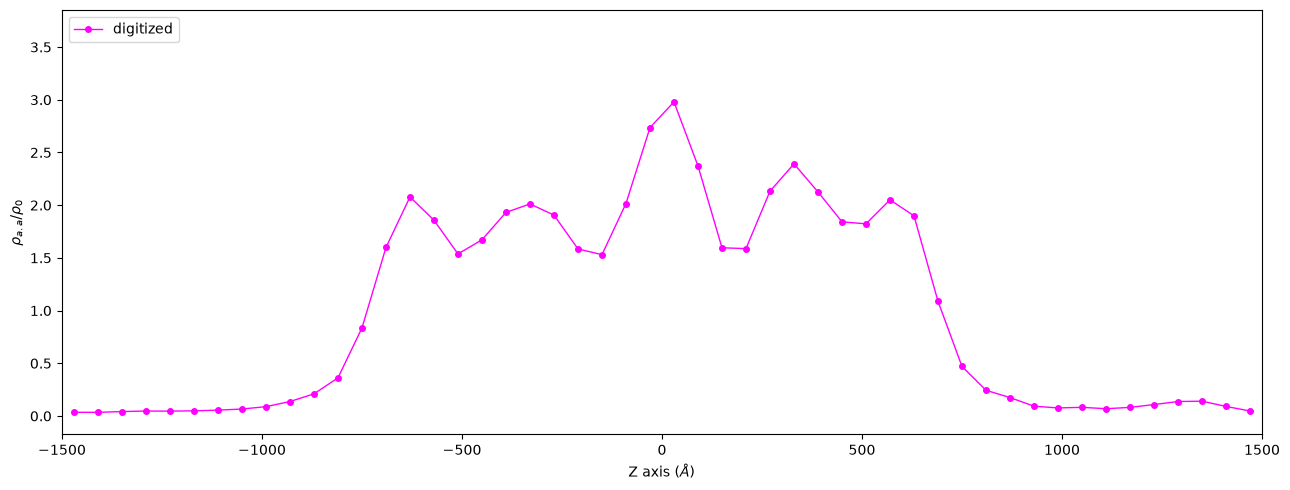

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Klf4 "single" (green) curve, digitized from media/figures/20260824/mitzutani-klf4.png
# 50 uniform bins over z in [-1500, 1500] A  ->  centers at +-30, +-90, ..., +-1470
klf4_single_z = np.arange(-1470.0, 1471.0, 60.0)          # Angstrom
klf4_single_rho = np.array([                               # rho_aa / rho_0
    0.0354, 0.0347, 0.0420, 0.0473, 0.0461, 0.0492, 0.0556, 0.0660,
    0.0886, 0.1373, 0.2099, 0.3619, 0.8355, 1.5988, 2.0778, 1.8576,
    1.5375, 1.6715, 1.9317, 2.0119, 1.9061, 1.5849, 1.5305, 2.0159,
    2.7357, 2.9800, 2.3724, 1.5959, 1.5880, 2.1326, 2.3918, 2.1261,
    1.8420, 1.8230, 2.0505, 1.8990, 1.0887, 0.4698, 0.2443, 0.1745,
    0.0933, 0.0764, 0.0822, 0.0691, 0.0816, 0.1084, 0.1373, 0.1405,
    0.0908, 0.0477,
])

# --- overlay against the original figure ---------------------------------
IMG = "media/figures/20260824/mitzutani-klf4.png"
# pixel bounds of the axes frame and the tick calibration used for digitizing
TOP, BOT, LEFT, RIGHT = 184, 862, 362, 2069
px = np.polyfit([362.0, 2069.5], [-1500.0, 1500.0], 1)          # col -> z
py = np.polyfit([328.0, 494.5, 664.0, 833.5], [3., 2., 1., 0.], 1)  # row -> rho

x0, x1 = np.polyval(px, [LEFT - 0.5, RIGHT + 0.5])
y0, y1 = np.polyval(py, [BOT + 0.5, TOP - 0.5])

fig, ax = plt.subplots(figsize=(13, 5))
# ax.imshow(np.asarray(Image.open(IMG))[TOP:BOT + 1, LEFT:RIGHT + 1],
#           extent=[x0, x1, y0, y1], aspect="auto")
ax.plot(klf4_single_z, klf4_single_rho + 0.0, "o-", color="magenta",
        ms=4, lw=1.0, label="digitized")
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_xlabel(r"Z axis ($\AA$)")
ax.set_ylabel(r"$\rho_{a.a}/\rho_0$")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


right edge             rho_d=2.07+-0.06  rho_l=0.104+-0.037  z0= 695.0+-8.0  ell= 70.8+-14.1 A
left edge (mirrored)   rho_d=1.85+-0.06  rho_l=0.074+-0.040  z0= 745.9+-8.4  ell= 63.0+-15.3 A
slab (5 par)           rho_d=2.00+-0.06  rho_l=0.088+-0.056  zL=-738  zR=700  ell=69.5+-20.4 A  |  slab width 1438 A


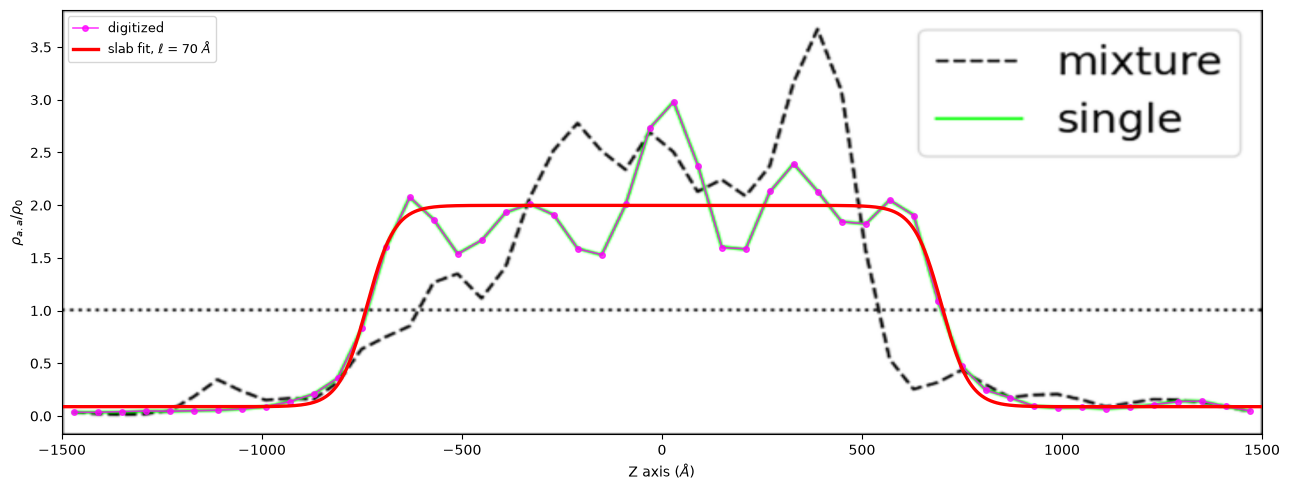

In [ ]:
from scipy.optimize import curve_fit

# --- models ---------------------------------------------------------------
def tanh_interface(z, rho_d, rho_l, z0, ell):
    """The model as given: single interface, rho_d at -inf -> rho_l at +inf."""
    return 0.5 * (rho_d + rho_l) - 0.5 * (rho_d - rho_l) * np.tanh((z - z0) / ell)

def tanh_slab(z, rho_d, rho_l, zL, zR, ell):
    """Two such interfaces back to back, sharing rho_d, rho_l and ell."""
    return rho_l + 0.5 * (rho_d - rho_l) * (np.tanh((z - zL) / ell)
                                            - np.tanh((z - zR) / ell))

# --- fits -----------------------------------------------------------------
# each edge on its own, using the literal single-interface model.
# the left edge is ascending, so it is fitted in the mirrored coordinate -z.
mR = klf4_single_z >= 330.0
mL = klf4_single_z <= -330.0
pR, cR = curve_fit(tanh_interface, klf4_single_z[mR], klf4_single_rho[mR],
                   p0=[2.0, 0.05, 700.0, 100.0], maxfev=40000)
pL, cL = curve_fit(tanh_interface, -klf4_single_z[mL], klf4_single_rho[mL],
                   p0=[2.0, 0.05, 700.0, 100.0], maxfev=40000)
# whole profile at once
ps, cs = curve_fit(tanh_slab, klf4_single_z, klf4_single_rho,
                   p0=[2.0, 0.05, -700.0, 700.0, 100.0], maxfev=40000)

for name, p, c in [("right edge", pR, cR), ("left edge (mirrored)", pL, cL)]:
    e = np.sqrt(np.diag(c))
    print(f"{name:22s} rho_d={p[0]:.2f}+-{e[0]:.2f}  rho_l={p[1]:.3f}+-{e[1]:.3f}"
          f"  z0={p[2]:6.1f}+-{e[2]:.1f}  ell={p[3]:5.1f}+-{e[3]:.1f} A")
es = np.sqrt(np.diag(cs))
print(f"{'slab (5 par)':22s} rho_d={ps[0]:.2f}+-{es[0]:.2f}  rho_l={ps[1]:.3f}+-{es[1]:.3f}"
      f"  zL={ps[2]:.0f}  zR={ps[3]:.0f}  ell={ps[4]:.1f}+-{es[4]:.1f} A"
      f"  |  slab width {ps[3]-ps[2]:.0f} A")

# --- same overlay as before, plus the fits --------------------------------
fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(np.asarray(Image.open(IMG))[TOP:BOT + 1, LEFT:RIGHT + 1],
          extent=[x0, x1, y0, y1], aspect="auto")
ax.plot(klf4_single_z, klf4_single_rho, "o-", color="magenta",
        ms=4, lw=1.2, alpha=0.75, label="digitized")

zf = np.linspace(x0, x1, 1200)
ax.plot(zf, tanh_slab(zf, *ps), "-", color="red", lw=2.4,
        label=rf"slab fit, $\ell$ = {ps[4]:.0f} $\AA$")
zr = np.linspace(330, x1, 400)
zl = np.linspace(x0, -330, 400)
# ax.plot(zr, tanh_interface(zr, *pR), "--", color="blue", lw=2.2,
#         label="single tanh, each edge")
# ax.plot(zl, tanh_interface(-zl, *pL), "--", color="blue", lw=2.2)

ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_xlabel(r"Z axis ($\AA$)")
ax.set_ylabel(r"$\rho_{a.a}/\rho_0$")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()


In [ ]:
slab_width = (ps[3]-ps[2])/10   # nm
vol = 30*30*slab_width * 1e-24
nklf4 = 184
c_dense = nklf4 / (vol * 6.022e23)  # Molar
es[3]+es[2]

np.float64(31.723825871097812)

### Estimating kappa from interface width

In [4]:
v_tf   = 67.0      # Klf4 protein, nm^3
kT = 1.0
inds = [0, 10, 25, 45]
nb = 2233  # Klf4
# nb = 1000          # consistent with both v_tf / v_water and the measured c_dense
c_sat = 2000     # nanomolar
c_pw = c_sat/4  # nanomolar
c_dense = 2.4e6
delta_mu = kT*np.log(c_sat/c_pw)
phi_sat = to_phi(c_sat, v_tf)
phi_pw = to_phi(c_pw, v_tf)
phi_dense = to_phi(c_dense, v_tf)

chi, phi_d = calibrate(phi_sat, nb)
print("Chi (calibrated given nb): ", chi)
print("phi_dense (calibrated given nb): ", phi_d)
print("phi_dense (MD fit): ", phi_dense)
print("phi sat (given): ", phi_sat)
print("phi pw (given): ", phi_pw)

R = 40   # nm
print("R: ", R)

# vol fracs at edges of interface
phi_10 = phi_sat + 0.1*(phi_d - phi_sat)
phi_90 = phi_sat + 0.9*(phi_d - phi_sat)

# interface width from omega integral on a plane at equilibrium
mu_sat = nb*dfb(phi_sat, nb, chi)
mu_d = nb*dfb(phi_d, nb, chi)
print("mus equal: ", mu_sat, mu_d)
# domega  = lambda p: fb(p, nb, chi) - fb(phi_sat, nb, chi) + mu_sat*(p - phi_sat)/nb # kBT/b
phis_interface = np.linspace(phi_10, phi_90, 10000)
I = np.trapezoid((2*omega(phis_interface, phi_sat, nb, chi))**(-0.5), phis_interface) # (b/kBT)^1/2
v_water = 0.0297   # nm^3 
b = v_water**(1/3)  # nm
l_interface_nm = 15.28  # nm
# l_interface_nm = 15.0  # nm
print("Site length (nm): ", b)
print("Interface length (nm): ", l_interface_nm)
print("Interface length (sites): ", l_interface_nm / b)
l_interface_sites = l_interface_nm / b  # b (lattice site length)
kappa = (l_interface_sites / I)**2  # kBT / b
kappa_nm = kappa / b
print("kappa (kBT / site length): ", kappa)
print("kappa (kBT / nm): ", kappa_nm)

h0_lo, h0_hi, _, _ = h0_range(phi_pw, nb, chi, kappa=kappa, eps=1e-12)
print("h0_lo (kBT / site^2): ", h0_lo, "\nh0_hi (kBT / site^2): ", h0_hi)
print("h0_lo (kBT / nm^2): ", h0_lo/b**2, "\nh0_hi (kBT / nm^2): ", h0_hi/b**2)
print("kappa / h0_lo (sites): ", kappa / h0_lo)
# agreement with surface tension measurements
kBT = 4.11e-21 # J
phis_surf_tension = np.linspace(phi_sat, phi_d-1e-5, 5000)   # full range
I2 = np.trapezoid((2*kappa*omega(phis_surf_tension, phi_sat, nb, chi))**0.5, phis_surf_tension)
S = I2 * kBT * 1e18 * 1e6 / b**2
print("Surface tension (muN/m): ", S)   # muN/m
print("Surface energy (kBT): ", 4*np.pi*R**2*I2 / b**2)   # muN/m

Chi (calibrated given nb):  0.5447880606274295
phi_dense (calibrated given nb):  0.11203620701580225
phi_dense (MD fit):  0.09683376000000003
phi sat (given):  8.069480000000001e-05
phi pw (given):  2.0173700000000003e-05
R:  40
mus equal:  -1024.9292306238624 -1024.9292306238624
Site length (nm):  0.3096840346369102
Interface length (nm):  15.28
Interface length (sites):  49.34061265998124
kappa (kBT / site length):  10.113883687600339
kappa (kBT / nm):  32.658718423952294
h0_lo (kBT / site^2):  0.03571078088392902 
h0_hi (kBT / site^2):  0.03604832447470795
h0_lo (kBT / nm^2):  0.3723588789282754 
h0_hi (kBT / nm^2):  0.375878470209698
kappa / h0_lo (sites):  283.2165367784468
Surface tension (muN/m):  85.2272784897928
Surface energy (kBT):  416.9333597881997


### Prewetting graphical construction

[0.04180209]
[0.04853243 0.07315366 0.10940547]


(0.0, 0.16)

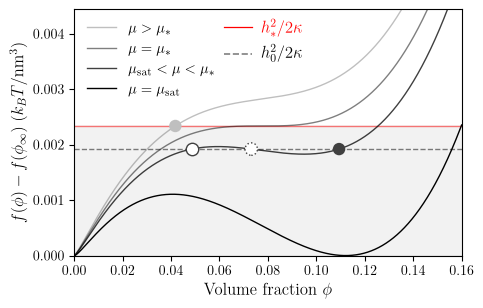

In [177]:
###### Graphical construction

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

# Bulk/surface parameters and phi_inf grid of the large_R run
# (spec/local/20261004/large_R/param.jl).  mu enters only through phi_inf, so the
# curves are omega(phi; phi_inf) = F(phi) - F(phi_inf) at fixed c/c_sat.  Multiples
# of mu_pw (as in the 20260821 figure) are meaningless here: mu ~ 1024 carries a
# large constant and mu_pw - mu_sat = ln 4.
d        = json.load(open("data/20261004/large_R/demo_bvp_profiles.json"))
p        = d["params"]["surface"]
nb, chi, kappa, h0 = p["nb"], p["chi_b"], p["kappa"], p["omega_b"]
phi_infs = np.array(d["phi_inf"])
binodal  = d["binodal"]
phis     = np.linspace(5e-9, 0.2, 20000)

# mu > mu_*, mu = mu_* (c_pw = c_sat/4, as in the kappa calibration),
# mu_sat < mu < mu_* (inside the bistable window of the run), mu = mu_sat
c_fracs = [0.14, 0.211, 0.31, 1.0]
inds    = [int(np.argmin(np.abs(phi_infs/binodal - t))) for t in c_fracs]
h_star  = h0_range(phi_infs[inds[1]], nb, chi, kappa=kappa)[0]   # dense min of the mu_* curve
init_energy_lo = h_star**2/(2*kappa)/v_water
hline   = h0**2/(2*kappa)/v_water                                         # the run's surface field

fig, ax = plt.subplots(1,1,figsize=(5,3.2))

ax.axhline(hline, color="black", lw=1.0,
           linestyle="dashed", alpha=0.5)

ax.fill_between(phis, 0, init_energy_lo, color="black", alpha=0.05)
ax.axhline(init_energy_lo, color="red", alpha=0.5, lw=1)

labels = [r"$\mu > \mu_*$",
          r"$\mu = \mu_*$",
          r"$\mu_{\rm sat} < \mu < \mu_*$",
          r"$\mu = \mu_{\rm sat}$"]

for i, idx in enumerate(inds):
    dF = omega(phis, phi_infs[idx], nb, chi)/v_water
    ax.plot(phis, dF, lw=1, color="black", alpha=(i+1)/4, label=labels[i])
    col = (1 - (i+1)/4,)*3   # opaque equivalent of the curve's black at alpha (i+1)/4

    if i == 2:
        xi = phis[np.where(np.diff(np.sign(dF - hline)) != 0)[0]]
        print(xi)
        yi = hline
        # lower-F film (the run's branch label at this phi_inf) filled, higher-F film
        # open, unstable middle root open with a dashed edge
        stable, meta = (xi[-1], xi[0]) if d["branch"][idx] == "thick" else (xi[0], xi[-1])
        ax.scatter(stable, yi, color=col, edgecolor="none", zorder=3, s=80)
        ax.scatter(meta, yi, facecolor="white", edgecolor=col, zorder=3, s=80)
        ax.scatter(xi[1], yi, facecolor="white", edgecolor=col, linestyle=":", zorder=3, s=80)

    elif i in [0,2]:
        xi = phis[np.where(np.diff(np.sign(dF - init_energy_lo)) != 0)[0]]
        print(xi)
        yi = init_energy_lo
        ax.scatter(xi[0], yi, color=col, edgecolor="none", zorder=3, s=80)

ax.set_xlabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_ylabel(r"$f(\phi) - f(\phi_\infty) \; (k_BT / {\rm nm}^3)$", fontsize=12)
ax.text(0.482, 0.905, r"$h_*^2/2\kappa$", fontsize=12, color="red", transform=ax.transAxes)
ax.plot((0.386, 0.458), (0.928, 0.928), color="red", lw=0.9, transform=ax.transAxes)

ax.text(0.482, 0.803, r"$h_0^2/2\kappa$", fontsize=12, color="black", transform=ax.transAxes)
ax.plot((0.386, 0.458), (0.818, 0.818), color="gray", lw=1.2, transform=ax.transAxes, linestyle="dashed")

lg = ax.legend(fontsize=10.5, edgecolor="none", framealpha=0)
ax.set_ylim(0, 1.9*init_energy_lo)
ax.set_xlim(0, 0.16)

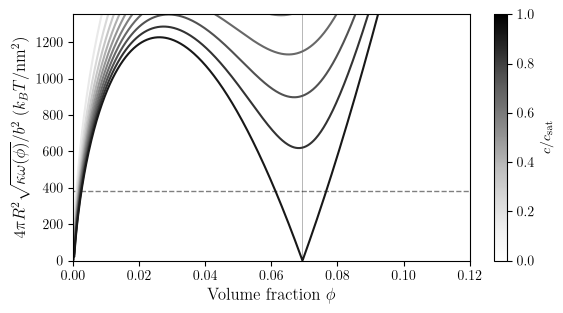

In [ ]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1, figsize=(6.4, 3.2))

def xi_of(z, phi, phi_inf, thresh=0.1):
    rel   = (phi - phi_inf) / phi_inf
    inner = rel[:-1]
    k = int(np.argmax(inner < thresh))
    if inner[k] >= thresh:
        return np.nan
    if k == 0:
        return 0.0
    r0, r1 = rel[k-1], rel[k]
    return z[k-1] + (thresh - r0) / (r1 - r0) * (z[k] - z[k-1])

runs = [("data/20260825/large_R/demo_bvp_profiles.json", 200)]

sweep_fracs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

phi_infs  =  np.linspace(1e-6, phi_sat, 1000)    # np.array(d["phi_inf"])
norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys
phis = np.linspace(5e-9, 1-5e-9, 5000)
inds = [int(np.argmin(np.abs(phi_infs/phi_sat - t))) for t in sweep_fracs]
phi_inf_sample  = phi_infs[inds]

ax.axhline(4*np.pi*R**2*(h0_lo/np.sqrt(2*kappa))/v_water**(1/2), color="black", lw=1.0,
           linestyle="dashed", alpha=0.5)

ax.axvline(phi_d, color="black", lw=0.5, alpha=0.4)

for i, idx in enumerate(inds):
    ax.plot(phis, 4*np.pi*R**2*np.sqrt(kappa*omega(phis, phi_infs[idx], nb, chi))/v_water**(2/3), lw=1.5, color=cmap(norm((i+2)/(len(inds)+2))))

ax.set_xlabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_ylabel(r"$4\pi R^2\sqrt{\kappa\omega(\phi)}/b^2 \; (k_BT / {\rm nm}^2)$", fontsize=12)
ax.set_ylim(0, 4*np.pi*R**2*2.0e-3/v_water)
ax.set_xlim(0, 0.12)
I2 = np.trapezoid((2*kappa*omega(phis_surf_tension, phi_sat, nb, chi))**0.5, phis_surf_tension)

# print(f"{'run':9s} {'R':>7s} {'mu':>8s} {'phi_inf':>10s} {'c_inf/nM':>9s} "
#       f"{'phi_s':>8s} {'xi':>7s} {'R/xi':>7s}  conv")

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label=r'$c/c_{\rm sat}$')

In [178]:
out_dir = "media/figures/20261007"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "pw_graphical.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261007/pw_graphical.pdf


### Influence of curvature 

In [240]:
T = 1.0
v_tf = 67    # nm^3
inds = [0, 10, 25, 45]
nb = 2230
c_sat = 2000     # nanomolar
c_pw = 1000  # nanomolar
kappa = 1
delta_mu = T*np.log(c_sat/c_pw)
phi_sat = to_phi(c_sat, v_tf)
phi_pw = to_phi(c_pw, v_tf)
chi, phi_d = calibrate(phi_sat, nb)
h0_lo, h0_hi, _, _ = h0_range(phi_pw, nb, chi, kappa=kappa, eps=1e-12)
mu_sat = -nb*dfb(phi_d, nb, chi)
mu_pw = -nb*dfb(phi_pw, nb, chi)
mus = np.array([0.75*mu_pw,  mu_sat])
h0 = h0_lo 
phis = np.linspace(5e-9, 1-5e-9, 5000)
init_energy = h0**2/(2*kappa)
init_energy_lo = h0_lo**2/(2*kappa)
init_energy_hi = h0_hi**2/(2*kappa)
hline = init_energy

In [241]:
print("h0_lo: ", h0_lo, "\n", 
      "h0_hi: ", h0_hi, "\n", 
      "chi: ", chi, "\n", 
      "h0: ", -h0_lo, "\n",
      "phi_d: ", phi_d, "\n", 
      "phi_sat: ", phi_sat, "\n", 
      "phi_pw: ", phi_pw, "\n",
      "mu_sat: ", mu_sat, "\n")

h0_lo:  0.008143148291991899 
 h0_hi:  0.009673323326128934 
 chi:  0.544821635760637 
 h0:  -0.008143148291991899 
 phi_d:  0.11211404241993071 
 phi_sat:  8.069480000000001e-05 
 phi_pw:  4.0347400000000006e-05 
 mu_sat:  1023.4887126671289 



run             R       mu    phi_inf  c_inf/nM    phi_s      xi    R/xi  conv


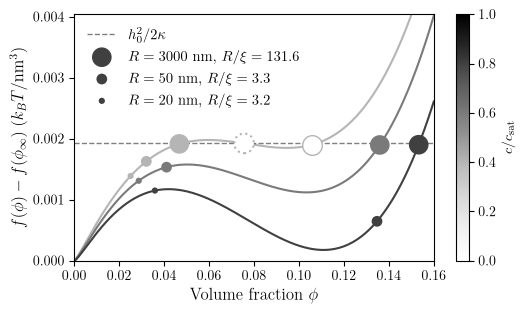

In [175]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1, figsize=(5.8, 3.2))

# xi = min{z : (phi(z) - phi_inf)/phi_inf < thresh}, with the crossing interpolated.
# The old expression, argmin(np.abs(phi - phi_inf)/phi_inf - 0.5), had np.abs closing
# before the -0.5, so it just sought the SMALLEST relative excess: it returned the
# first z where phi - phi_inf underflows to 0.0 (15-25% high), and clamped at L once
# the profile never gets there.  z = L is excluded below because the BVP pins it to
# phi_inf by the boundary condition -- a crossing there means L is too short to
# resolve xi, which is reported as nan rather than as xi = L.
def xi_of(z, phi, phi_inf, thresh=0.1):
    rel   = (phi - phi_inf) / phi_inf
    inner = rel[:-1]
    k = int(np.argmax(inner < thresh))
    if inner[k] >= thresh:
        return np.nan
    if k == 0:
        return 0.0
    r0, r1 = rel[k-1], rel[k]
    return z[k-1] + (thresh - r0) / (r1 - r0) * (z[k] - z[k-1])

# runs = [("data/20260821/large_R/demo_bvp_profiles.json", 200),
#         ("data/20260821/med_R/demo_bvp_profiles.json",    60),
#         ("data/20260821/small_R/demo_bvp_profiles.json",  20)]

# runs = [("data/20260825/demo_bvp_profiles.json", 200)]

# runs = [("data/20260825/large_R/demo_bvp_profiles.json", 200),
#         ("data/20260825/medium_R/demo_bvp_profiles.json",    60),
#         ("data/20260825/small_R/demo_bvp_profiles.json",  20)]

runs = [("data/20261004/large_R/demo_bvp_profiles.json", 200),
        ("data/20261004/medium_R/demo_bvp_profiles.json",    60),
        ("data/20261004/small_R/demo_bvp_profiles.json",  20)]

# Fractions along the swept phi_inf axis at which to draw the construction.  The mu
# values are read back OUT of the sweep rather than taken from the calibration cell
# above, so each marker necessarily sits on the curve the BVP actually solved at
# (the calibration cell is free to drift to another system without silently
# collapsing every marker onto the nearest sampled mu).
# sweep_fracs = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
sweep_fracs = np.array([0.305, 0.5, 0.9])

# Bulk parameters come from the run provenance for the same reason.  These globals
# stay bound to the first run, as before, since other cells read phi_surf / phi_full
# / phi_infs / z_full.
path      = runs[0][0]
d         = json.load(open(path))
p         = d["params"]["surface"]
bc_reg    = d["params"]["bvp"]["bc_reg"]
mu_infs   = np.array(d["mu_inf"])
phi_infs  = np.array(d["phi_inf"])
phi_full  = np.array(d["phi_profiles_full"])
phi_surf  = phi_full[:, 0]
z_full    = np.array(d["z_full"])

T, c0 = 1.0, 1
nb, chi, kappa, h0 = p["nb"], p["chi_b"], p["kappa"], p["omega_b"]
phis = np.linspace(5e-9, 1-5e-9, 5000)

inds = [int(np.argmin(np.abs(phi_infs/d["binodal"] - t))) for t in sweep_fracs]
phi_inf_sample  = phi_infs[inds]

norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys
for i, idx in enumerate(inds):
    ax.plot(phis, omega(phis, phi_infs[idx], nb, chi)/v_water, lw=1.5, color=cmap(norm((i+2)/(len(inds)+2))))

ax.set_xlabel(r"Volume fraction $\phi$", fontsize=12)
ax.set_ylabel(r"$f(\phi) - f(\phi_\infty) \; (k_BT / {\rm nm}^3)$", fontsize=12)
ax.set_ylim(0, 1.2e-4/v_water)
ax.set_xlim(0, 0.16)

print(f"{'run':9s} {'R':>7s} {'mu':>8s} {'phi_inf':>10s} {'c_inf/nM':>9s} "
      f"{'phi_s':>8s} {'xi':>7s} {'R/xi':>7s}  conv")

norm = plt.Normalize(vmin=0, vmax=1)
cmap = mpl.cm.Greys

ax.axhline(h0**2/(2*kappa)/v_water, color="black", lw=1.0,
           linestyle="dashed", alpha=0.5, label = rf"$h_0^2/2\kappa$")

for path, size in runs:
    dd  = json.load(open(path))
    zz  = np.array(dd["z_full"])
    pf  = np.array(dd["phi_solver"])
    # pin = np.array(dd["phi_inf"])
    mi  = np.array(dd["mu_inf"])
    ok  = np.array(dd["success"])
    R   = dd["R"]
    tag = path.split("/")[-2]
    for i, idx in enumerate(inds):
        # args    = (mu, chi, T, nb, c0)
        # idx     = int(np.argmin(np.abs(mi + mu)))   # same phi_inf grid across runs
        phi_inf_i = phi_infs[idx]
        phi_s   = pf[idx, 0]
        xi      = xi_of(zz, pf[idx], phi_inf_i)
        # phi_ref = phis[np.argmin(F(phis, *args))]
        lab = rf"$R={R*0.3:.0f}$ nm, $R/\xi={R/xi:.1f}$" if np.isfinite(xi) else rf"$R={R*0.3:g}$ nm, $\xi$ unresolved"
        if i == 2:
            ax.scatter(phi_s, omega(phi_s, phi_inf_i, nb, chi)/v_water, s=size, zorder=3,
                        facecolor=cmap(norm((i+2)/(len(inds)+2))), label=lab,edgecolor="none")
        else:
            ax.scatter(phi_s, omega(phi_s, phi_inf_i, nb, chi)/v_water, s=size,
                        facecolor=cmap(norm((i+2)/(len(inds)+2))), edgecolor="none", zorder=3)
        if dd["branch"][idx] != "unique":
            # bistable: metastable surface value from the BVP (white, solid edge) and the
            # unstable middle root of omega(phi) = h0^2/(2 kappa) (white, dashed edge)
            col   = cmap(norm((i+2)/(len(inds)+2)))
            phi_o = dd["phi_other"][idx][0]
            g     = omega(phis, phi_inf_i, nb, chi) - h0**2/(2*kappa)
            roots = phis[np.where(np.diff(np.sign(g)) != 0)[0]]
            phi_u = roots[np.argmin(np.abs(roots - (phi_s + phi_o)/2))]
            ax.scatter(phi_o, omega(phi_o, phi_inf_i, nb, chi)/v_water, s=size,
                        facecolor="white", edgecolor=col, zorder=3)
            ax.scatter(phi_u, omega(phi_u, phi_inf_i, nb, chi)/v_water, s=size,
                        facecolor="white", edgecolor=col, linestyle=":", zorder=3, lw=1.5)
        
        # print(f"{tag:9s} {R:7g} {mi[idx]:8.4f} {phi_inf_i:10.3e} {to_nM(phi_inf_i, v_tf):9.1f} "
        #       f"{phi_s:8.4f} {xi:7.3f} {R/xi:7.2f}  {ok[idx]}")

ax.legend(fontsize=10.5, edgecolor="none", framealpha=0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax, label=r'$c/c_{\rm sat}$')

In [176]:
out_dir = "media/figures/20261007"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "pw_curvature3.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261007/pw_curvature3.pdf


### Single sphere from numerical solver (varying $h_0$)

8.069480000000957e-05


{'eps': 1e-08,
 'parallel_plates': False,
 'chi_b': 0.544821635760637,
 'omega_b': -0.0345,
 'kappa': 10.12228759025409,
 'phi_inf': 0.09,
 'L': 200.0,
 'R': 100.0,
 'conserve_volume': False,
 'nb': 2230.0}

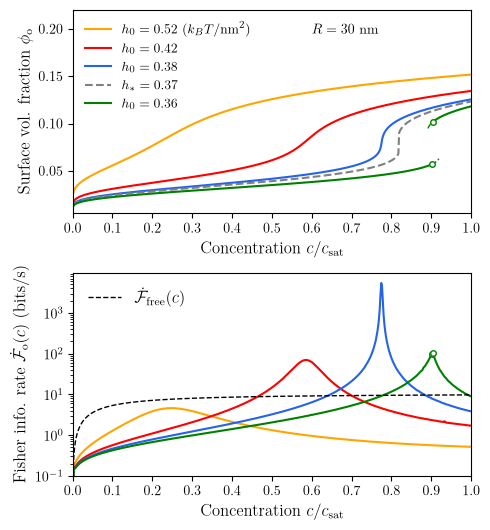

In [57]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
# path = "data/20260727/demo_bvp_profiles.json"
# path = "data/20260728/run3/demo_bvp_profiles.json"
# path = "data/20260822/run1/demo_bvp_profiles.json"
# path = "data/20260825/run1/demo_bvp_profiles.json"
path = "data/20261007/run1/demo_bvp_profiles.json"
# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
d = json.load(open(path))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
binodal = d["binodal"]

fig, ax = plt.subplots(2, 1, figsize=(5, 5.4))
k = 0
# ax[0].plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
# ax[0].set_xlabel(r"Distance from surface $z$", fontsize=12)
# ax[0].set_ylabel(r"Profile $\phi$", fontsize=12)
# ax[0].set_xlim(0, z_full[-1]); 
# ax[0].grid(alpha=0.3)

colors = ["orange", "red", "#2563EB", "gray", "green"]
for i, run in enumerate([1,2,3,4,5]):

    # path = f"data/20260804/run{run}/demo_bvp_profiles.json"
    # path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
    # path = f"data/20260727/demo_bvp_profiles.json"
    # path = f"data/20260822/run{run}/demo_bvp_profiles.json"
    # path = f"data/20260825/run{run}/demo_bvp_profiles.json"
    path = f"data/20261007/run{run}/demo_bvp_profiles.json"
    d = json.load(open(path))
    phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
    mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
    z_full   = np.array(d["z_full"])                        # (n_z,)
    z_lin    = np.array(d["z_linear"])                      # (n_z,)
    phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
    branch   = np.array(d["branch"])                 # "thin" / "thick" / "unique" (min-F branch)
    # metastable (higher-F) branch surface value, only where bistable
    phi_surf_other = np.array([p[0] if len(p) else np.nan for p in d["phi_other"]])
    phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
    R, omega_b = d["R"], d["omega_b"]
    h0 = -  d["params"]["surface"]["omega_b"]
    chi = d["chi"]

    phi_surf = phi_full.T[0,:]
    x = phi_inf/binodal
    # split the min-F curve at the thin -> thick switch (first-order jump)
    jumps = np.where((branch[:-1] == "thin") & (branch[1:] == "thick"))[0] + 1
    segs = np.split(np.arange(len(phi_inf)), jumps)
    # ax[0].set_xticks(xticks/1000)
    # ax[0].set_xticklabels(xticks)
    if i == 0:
        label = rf"$h_0={h0/b**2:.2f}$ ($k_BT/$nm$^2$)"
    elif i == 3:
        label = rf"$h_*={h0/b**2:.2f}$"
    else:
        label = rf"$h_0={h0/b**2:.2f}$"
    ls, meta_ls = ("dashed", ":") if i == 3 else ("solid", "--")
    for k_seg, s in enumerate(segs):
        ax[0].plot(x[s], phi_surf[s], color=colors[i], linestyle=ls, label=label if k_seg == 0 else None)
    meta_thick = np.where(branch == "thin")[0]    # phi_other = metastable thick film
    meta_thin  = np.where(branch == "thick")[0]   # phi_other = metastable thin film
    for J in jumps:
        # metastable continuations, anchored at the stable branch edges
        ax[0].plot(x[np.r_[meta_thick, J]], np.r_[phi_surf_other[meta_thick], phi_surf[J]],
                   color=colors[i], ls=meta_ls, lw=1)
        ax[0].plot(x[np.r_[J-1, meta_thin]], np.r_[phi_surf[J-1], phi_surf_other[meta_thin]],
                   color=colors[i], ls=meta_ls, lw=1)
        ax[0].plot(x[[J-1, J]], phi_surf[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)
    # ax[0].set_xlabel(r"Concentration $c\times 10^{-3}$", fontsize=12)
    ax[0].set_ylabel(r"Surface vol. fraction $\phi_{\rm o}$", fontsize=12)

    a = 3e-3        # um / 10 bp
    D_tf = 7.4      # um^2/s
    kb = 4*a*D_tf   # um^3/s
    K_D = 0.1*to_nM(binodal, v_tf)*1e-24*6.022e23
    ku = kb*K_D
    c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3
    c_surf = to_nM(phi_surf, v_tf)*1e-24*6.022e23   # particles / um^3

    tau_free = 1 / (kb*c_inf) + 1 / ku
    tau = 1 / (kb*c_surf) + 1 / ku
    # differentiate each continuous branch separately so the jump does not produce a spike
    fisher_rate_one_sphere = np.full_like(phi_surf, np.nan)
    for s in segs:
        dphi_surf = np.gradient(phi_surf[s], phi_inf[s])
        phi_surf_gain = (dphi_surf * phi_inf[s] / phi_surf[s]) ** 2
        fisher_rate_one_sphere[s] = phi_surf_gain / tau[s]

    if i != 3:
        for s in segs:
            ax[1].plot(x[s], fisher_rate_one_sphere[s], color=colors[i])
        for J in jumps:
            ax[1].plot(x[[J-1, J]], fisher_rate_one_sphere[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)

xticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ax[0].set_xticks(xticks)
ax[0].set_xticklabels(xticks)
ax[0].set_xlim(0, 1.0)
ax[0].set_ylim(None, 0.22)
ax[0].set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
lg0 = ax[0].legend(fontsize=9.5, edgecolor="none")
lg0.get_frame().set_alpha(None)
lg0.get_frame().set_facecolor((0, 0, 1, 0.0))
ax[1].plot(phi_inf/binodal, 1/tau_free, linestyle="dashed", color="black",
        label=r"$\dot{\mathcal{F}}_{\rm free}(c)$", lw=1)
ax[1].set_yscale('log')
ax[1].set_ylabel(r"Fisher info. rate $\dot{\mathcal{F}}_{\rm o}(c)$ (bits/s)", fontsize=12)
ax[1].set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
ax[1].set_ylim(0.1, None)
ax[0].text(0.6, 0.195, rf"$R={R*0.3:g}$ nm", fontsize=10)

ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)
ax[1].set_xlim(0.0, 1.0)
# ax[1].grid(alpha=0.4)
ax[1].legend(fontsize=12, loc="upper left", edgecolor="none")

# fig.suptitle(rf"$R={R*0.3}$, $h_0={omega_b}$, $\chi = {chi}$")
fig.tight_layout()
print(binodal)
# print(phi_inf)
d["params"]["surface"]

In [58]:
out_dir = "media/figures/20261007"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "surface_fisher_3vals.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261007/surface_fisher_3vals.pdf


### Single sphere from solver (varying R)

8.069480000000957e-05


{'eps': 1e-08,
 'parallel_plates': False,
 'chi_b': 0.544821635760637,
 'omega_b': -0.034,
 'kappa': 10.12228759025409,
 'phi_inf': 0.09,
 'L': 200.0,
 'R': 10000.0,
 'conserve_volume': False,
 'nb': 2230.0}

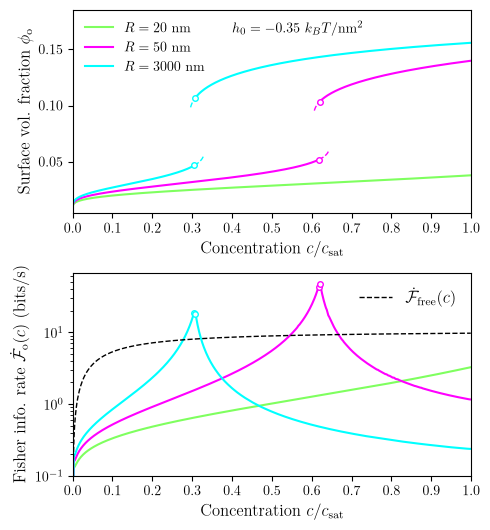

In [80]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
# path = "data/20260727/demo_bvp_profiles.json"
# path = "data/20260728/run3/demo_bvp_profiles.json"
# path = "data/20260822/run1/demo_bvp_profiles.json"
# path = "data/20260825/small_R/demo_bvp_profiles.json"
path = "data/20261004/small_R/demo_bvp_profiles.json"
# path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
d = json.load(open(path))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
# phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_full = np.array(d["phi_solver"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
binodal = d["binodal"]

fig, ax = plt.subplots(2, 1, figsize=(5, 5.4))
k = 0
# ax[0].plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
# ax[0].set_xlabel(r"Distance from surface $z$", fontsize=12)
# ax[0].set_ylabel(r"Profile $\phi$", fontsize=12)
# ax[0].set_xlim(0, z_full[-1]); 
# ax[0].grid(alpha=0.3)

colors = ["#7FFF5F", "magenta", "cyan"]
for i, run in enumerate(["small_R", "medium_R", "large_R"]):

    # path = f"data/20260804/run{run}/demo_bvp_profiles.json"
    # path = "data/20260807/R_5_h0_-0.4_chi_3.0_bcr_0.04/demo_bvp_profiles.json"
    # path = f"data/20260727/demo_bvp_profiles.json"
    # path = f"data/20260822/run{run}/demo_bvp_profiles.json"
    # path = f"data/20260825/{run}/demo_bvp_profiles.json"
    path = f"data/20261004/{run}/demo_bvp_profiles.json"
    d = json.load(open(path))
    phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
    mu_inf  = np.array(d["mu_inf"])                       # (n_phi,)
    z_full   = np.array(d["z_full"])                        # (n_z,)
    z_lin    = np.array(d["z_linear"])                      # (n_z,)
    # phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)

    phi_full = np.array(d["phi_solver"])             # (n_phi, n_z)
    branch   = np.array(d["branch"])                 # "thin" / "thick" / "unique" (min-F branch)
    # metastable (higher-F) branch surface value, only where bistable
    phi_surf_other = np.array([p[0] if len(p) else np.nan for p in d["phi_other"]])

    phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
    succ     = np.array(d["success"])
    R, omega_b = d["R"], d["omega_b"]
    h0 = d["params"]["surface"]["omega_b"]
    chi = d["chi"]

    phi_surf = phi_full.T[0,:]
    x = phi_inf/binodal
    # split the min-F curve at the thin -> thick switch (first-order jump)
    jumps = np.where((branch[:-1] == "thin") & (branch[1:] == "thick"))[0] + 1
    segs = [s[succ[s]] for s in np.split(np.arange(len(phi_inf)), jumps)]
    # ax[0].set_xticks(xticks/1000)
    # ax[0].set_xticklabels(xticks)
    for k_seg, s in enumerate(segs):
        ax[0].plot(x[s], phi_surf[s], color=colors[i], label=rf"$R={R*0.3:.0f}$ nm" if k_seg == 0 else None)
    meta_thick = np.where((branch == "thin") & succ)[0]    # phi_other = metastable thick film
    meta_thin  = np.where((branch == "thick") & succ)[0]   # phi_other = metastable thin film
    for J in jumps:
        # dashed metastable continuations, anchored at the stable branch edges
        ax[0].plot(x[np.r_[meta_thick, J]], np.r_[phi_surf_other[meta_thick], phi_surf[J]],
                   color=colors[i], ls="--", lw=1)
        ax[0].plot(x[np.r_[J-1, meta_thin]], np.r_[phi_surf[J-1], phi_surf_other[meta_thin]],
                   color=colors[i], ls="--", lw=1)
        ax[0].plot(x[[J-1, J]], phi_surf[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)
    # ax[0].set_xlabel(r"Concentration $c\times 10^{-3}$", fontsize=12)
    ax[0].set_ylabel(r"Surface vol. fraction $\phi_{\rm o}$", fontsize=12)

    a = 3e-3        # um / 10 bp
    D_tf = 7.4      # um^2/s
    kb = 4*a*D_tf   # um^3/s
    K_D = 0.1*to_nM(binodal, v_tf)*1e-24*6.022e23
    ku = kb*K_D
    c_inf = to_nM(phi_inf, v_tf)*1e-24*6.022e23   # particles / um^3
    c_surf = to_nM(phi_surf, v_tf)*1e-24*6.022e23   # particles / um^3

    tau_free = 1 / (kb*c_inf) + 1 / ku
    tau = 1 / (kb*c_surf) + 1 / ku
    # differentiate each continuous branch separately so the jump does not produce a spike
    fisher_rate_one_sphere = np.full_like(phi_surf, np.nan)
    for s in segs:
        dphi_surf = np.gradient(phi_surf[s], phi_inf[s])
        phi_surf_gain = (dphi_surf * phi_inf[s] / phi_surf[s]) ** 2
        fisher_rate_one_sphere[s] = phi_surf_gain / tau[s]

    if i != 3:
        for s in segs:
            ax[1].plot(x[s], fisher_rate_one_sphere[s], color=colors[i])
        for J in jumps:
            ax[1].plot(x[[J-1, J]], fisher_rate_one_sphere[[J-1, J]], "o", ms=4, mfc="white", mec=colors[i], zorder=3)

xticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ax[0].set_xticks(xticks)
ax[0].set_xticklabels(xticks)
ax[0].set_xlim(0.00, 1.0)
ax[0].set_ylim(None, 0.185)
ax[0].set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
lg0 = ax[0].legend(fontsize=10, edgecolor="none", loc="upper left", ncol=1) # (0.62, 0.27)
lg0.get_frame().set_alpha(None)
lg0.get_frame().set_facecolor((0, 0, 1, 0.0))
ax[1].plot(phi_inf/binodal, 1/tau_free, linestyle="dashed", color="black",
        label=r"$\dot{\mathcal{F}}_{\rm free}(c)$", lw=1)
ax[1].set_yscale('log')
ax[1].set_ylabel(r"Fisher info. rate $\dot{\mathcal{F}}_{\rm o}(c)$ (bits/s)", fontsize=12)
ax[1].set_xlabel(r"Concentration $c/c_{\rm sat}$", fontsize=12)
ax[1].set_ylim(0.1, None)
ax[0].text(0.4, 0.165, rf"$h_0={h0/b**2:.2f}$ $k_BT/$nm$^2$", fontsize=10)
 
ax[1].set_xticks(xticks)
ax[1].set_xticklabels(xticks)
ax[1].set_xlim(0.00, 1.0)
# ax[1].grid(alpha=0.4)
ax[1].legend(fontsize=12, loc="upper right", edgecolor="none")

# fig.suptitle(rf"$R={R*0.3}$, $h_0={omega_b}$, $\chi = {chi}$")
fig.tight_layout()
print(binodal)
# print(phi_inf)
d["params"]["surface"]

In [81]:
out_dir = "media/figures/20261007"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "surface_fisher_3vals_vsR.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20261007/surface_fisher_3vals_vsR.pdf


### Single plate - SI

equil. concentration 5e-09
equil. concentration 5e-09
equil. concentration 5e-09
binodal:  0.881763523236473


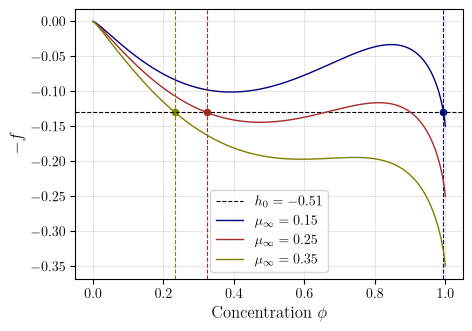

In [ ]:
###### Plot

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

# mus = [0.3, 0.4, 0.5]
c = ["navy", "brown", "olive"]

init_energy = h0**2/(2*kappa)
ax.axhline(-init_energy, color="black", lw=0.8, 
           linestyle="dashed", label=rf"$h_0 = {h0}$")

for i, mu in enumerate(mus):
    min_ = np.argmin(F(phis, mu, chi, T, nb, c0))
    phi_inf = phis[min_]
    dF = F(phis, mu, chi, T, nb, c0) - F(phi_inf, mu, chi, T, nb, c0)
    ax.plot(phis, -dF, color=c[i], lw=1, label=rf"$\mu_\infty={mus[i]}$")
    intersect = np.argmin(np.abs(-dF + init_energy))
    xi = phis[intersect]
    yi = -init_energy
    ax.scatter(xi, yi, color=c[i], s=20)
    ax.axvline(xi, color=c[i], lw=0.8, linestyle="dashed")

    print("equil. concentration", phi_inf)

ax.set_xlabel(r"Concentration $\phi$", fontsize=12)
ax.set_ylabel(r"$-f$", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend()

# ultra zoom in
# ax.set_xlim(-1e-5, 4e-4)
# ax.set_ylim(-1e-5, 1e-6)

min_ = np.argmin(F(phis, 0, chi, T, nb, c0))
phi_inf = phis[min_]
print("binodal: ", phi_inf)


In [ ]:
out_dir = "media/figures/20260801"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "prewetting_potentials_demo.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260801/prewetting_potentials.pdf


In [ ]:
### With volume conservation

# if sol is not None:
#     if len(sol) == 2:
#         ax.axvline(x=sol[0], lw=1)
#         ax.axvline(x=sol[1], lw=1)
#     elif len(sol) == 1:
#         ax.axvline(x=sol[0], lw=1)

### Parallel plates

In [77]:
import numpy as np
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq

# =============================================================================
# Mechanical analogy for  kappa phi'' = F'(phi)  (z plays the role of time):
#   particle of mass kappa in the potential  V(phi) = -F(phi),  plotted below.
#   BC at the plate:  phi'(0) = h0/kappa   ->   K0 = h0^2/(2 kappa).
# A symmetric profile between plates a distance d apart leaves phi_fp, turns
# around exactly once, and returns to phi_fp at z = d with phi'(d) = -h0/kappa.
# So the condition is  period(phi_fp) = d,  which we get from energy
# conservation as a quadrature instead of by shooting.
#   E - V(phi) = F(phi) - F(phi_fp) + K0 =: w(phi)
#   period = 2 * sqrt(kappa/2) * int_{phi_fp}^{phi_turn} dphi / sqrt(w(phi))
# =============================================================================

EPS = 1e-12

def F(phi, *args):
    mu, chi, T, nb, c0 = args
    return mu*phi + T*c0*(chi*phi*(1-phi) + (phi*np.log(phi)/nb + (1-phi)*np.log(1-phi)))

def dFdphi(phi, *args):
    mu, chi, T, nb, c0 = args
    return mu + T*c0*(chi*(1-2*phi) + (np.log(phi) + 1)/nb - np.log(1-phi) - 1)

def extrema(args, n=4001):
    """Extrema of F: roots of F' bracketed on a grid, then polished.
    Robust to F having 0, 1, 2 or 3 of them (unlike diffing sign(diff(F)))."""
    p = np.linspace(1e-9, 1 - 1e-9, n)
    v = dFdphi(p, *args)
    k = np.where(np.sign(v[:-1]) * np.sign(v[1:]) < 0)[0]
    return np.array([brentq(dFdphi, p[i], p[i+1], args=args, xtol=1e-14) for i in k])

def turning_point(phi0, h0, kappa, args, n=2000):
    """First phi past phi0 (travelling in the direction sign(h0)) where the
    particle runs out of kinetic energy. NaN if it escapes (0,1) instead."""
    K0 = h0**2 / (2*kappa)
    f0 = F(phi0, *args)
    w = lambda p: F(p, *args) - f0 + K0
    end = (1 - EPS) if h0 > 0 else EPS
    p = np.linspace(phi0, end, n)                 # ordered along direction of travel
    v = w(p)
    k = np.where(np.sign(v[:-1]) * np.sign(v[1:]) < 0)[0]
    if len(k) == 0:
        return np.nan
    a, b = sorted((p[k[0]], p[k[0]+1]))
    return brentq(w, a, b, xtol=1e-14)

def period(phi0, h0, kappa, args):
    """Round-trip z-distance: leave phi0, turn around once, return to phi0.
    NaN if unbounded, inf if the turning point is an extremum of F (homoclinic:
    the particle takes forever to arrive, so the film is infinitely thick)."""
    phi_t = turning_point(phi0, h0, kappa, args)
    if not np.isfinite(phi_t):
        return np.nan
    slope = abs(dFdphi(phi_t, *args))             # = |w'(phi_t)|
    if slope < 1e-12:
        return np.inf
    K0, f0 = h0**2/(2*kappa), F(phi0, *args)
    a, b = sorted((phi0, phi_t))
    up = phi_t > phi0
    # w vanishes linearly at phi_t, so sqrt(dist/w) is smooth there (-> 1/sqrt(slope));
    # hand the 1/sqrt endpoint singularity to quad's algebraic weight rather than
    # letting the integrand blow up numerically.
    def smooth(p):
        w = F(p, *args) - f0 + K0
        dist = (b - p) if up else (p - a)
        return np.sqrt(kappa/2) * np.sqrt(1.0/slope if (w <= 0 or dist <= 0) else dist/w)
    val, _ = quad(smooth, a, b, weight='alg',
                  wvar=((0.0, -0.5) if up else (-0.5, 0.0)), limit=2000)
    return 2.0 * val

def fixed_points(d, h0, kappa, args, n=800, lo=1e-6, hi=1-1e-6):
    """Every phi_fp with period(phi_fp) == d. Returns (roots, grid, periods)."""
    p = np.linspace(lo, hi, n)
    Tg = np.array([period(x, h0, kappa, args) for x in p])
    g = Tg - d
    roots = [brentq(lambda x: period(x, h0, kappa, args) - d, p[i], p[i+1], xtol=1e-12)
             for i in range(len(p)-1)
             if np.isfinite(g[i]) and np.isfinite(g[i+1]) and g[i]*g[i+1] < 0]
    return np.array(roots), p, Tg

def profile(z, phi0, h0, kappa, args, rtol=1e-10, atol=1e-12):
    """phi(z) by direct integration -- used only to verify a root, not to find one."""
    rhs = lambda _, y: (y[1], dFdphi(min(max(y[0], EPS), 1-EPS), *args)/kappa)
    s = solve_ivp(rhs, (z[0], z[-1]), [phi0, h0/kappa], t_eval=z, rtol=rtol, atol=atol)
    return s.y[0], s.y[1]

In [78]:
###### Parameters
T, nb, chi, c0, kappa = 1.0, 1, 2.5, 1.0, 1
mus = np.array([0.05, 0.1])
h0 = -0.3
d = 3
phis = np.linspace(5e-9, 1 - 5e-9, 500)
K0 = h0**2 / (2*kappa)

mu=0.05: 1 fixed point(s)
   phi_fp=0.9675854469  phi_turn=0.8550162586   check: phi(d)-phi(0)=+1.70e-09, phi'(d)=+0.30000001 (want +0.30000000)
mu=0.1: 3 fixed point(s)
   phi_fp=0.3516554714  phi_turn=0.1552496822   check: phi(d)-phi(0)=+5.38e-11, phi'(d)=+0.30000000 (want +0.30000000)
   phi_fp=0.5471988707  phi_turn=0.2855557840   check: phi(d)-phi(0)=+3.55e-11, phi'(d)=+0.30000000 (want +0.30000000)
   phi_fp=0.9613119549  phi_turn=0.8404633341   check: phi(d)-phi(0)=+1.03e-09, phi'(d)=+0.30000000 (want +0.30000000)


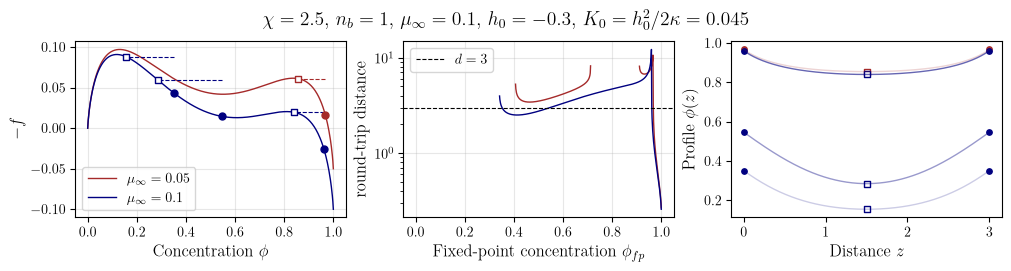

In [79]:
###### Plot
plt.rcParams.update({"text.usetex": True, "font.family": "serif"})
fig, (ax, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 2.6), layout="constrained")
c = ["brown", "navy", "olive"]

for i, mu in enumerate(mus):
    args = (mu, chi, T, nb, c0)

    # for e in extrema(args):
    #     ax.axvline(e, lw=0.8, color="black", alpha=0.4)

    ax.plot(phis, -F(phis, *args), color=c[i], lw=1, label=rf"$\mu_\infty={mu}$")

    roots, pgrid, Tg = fixed_points(d, h0, kappa, args)
    ax2.plot(pgrid, Tg, color=c[i], lw=1)

    print(f"mu={mu}: {len(roots)} fixed point(s)")
    for j, r in enumerate(roots):
        pt = turning_point(r, h0, kappa, args)
        zz = np.linspace(0, d, 2001)
        pz, dpz = profile(zz, r, h0, kappa, args)
        ax3.plot(zz, pz, color=c[i], lw=1, alpha=0.2*(j+1))
        ax3.scatter(0, pz[-1], color=c[i], s=15)
        ax3.scatter(d, pz[-1], color=c[i], s=15)
        ax3.scatter(d/2, pt, edgecolor=c[i], s=15, color="white", marker="s")
        print(f"   phi_fp={r:.10f}  phi_turn={pt:.10f}   "
              f"check: phi(d)-phi(0)={pz[-1]-r:+.2e}, "
              f"phi'(d)={dpz[-1]:+.8f} (want {-h0/kappa:+.8f})")

        ax.scatter(r,  -F(r,  *args), color=c[i], s=25, zorder=3)
        ax.scatter(pt, -F(pt, *args), edgecolor=c[i], color="white", s=25, zorder=3, marker="s")
        ax.plot([r, pt], [-F(r, *args) + K0]*2, color=c[i], lw=0.8, ls="dashed")
        # ax.axhline(-F(r, *args), color=c[i], lw=0.6, ls="dotted")

ax2.axhline(d, color="black", lw=0.8, ls="dashed", label=rf"$d={d}$")
ax.set_xlabel(r"Concentration $\phi$", fontsize=12)
ax.set_ylabel(r"$-f$", fontsize=12)
fig.suptitle(rf"$\chi = {chi}$, $n_b={nb}$, $\mu_\infty={mu}$, $h_0={h0}$, $K_0=h_0^2/2\kappa={K0:.3g}$", fontsize=14)
ax2.set_xlabel(r"Fixed-point concentration $\phi_{fp}$", fontsize=12)
ax2.set_ylabel("round-trip distance", fontsize=12)
ax2.set_yscale("log")
ax2.set_xlim(-0.05, 1.05)
ax3.set_ylabel(r"Profile $\phi(z)$", fontsize=12)
ax3.set_xlabel(r"Distance $z$", fontsize=12)
for a in (ax, ax2):
    a.grid(True, alpha=0.3)
    a.legend()

In [ ]:
out_dir = "media/figures/20260802"
os.makedirs(out_dir, exist_ok=True) 
out_path = os.path.join(out_dir, "parallel_plates_graphical_hi_c_low_h0_1.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260802/parallel_plates_graphical_hi_c_low_h0_1.pdf


### Parallel plates solver

3.787392948001521e-05


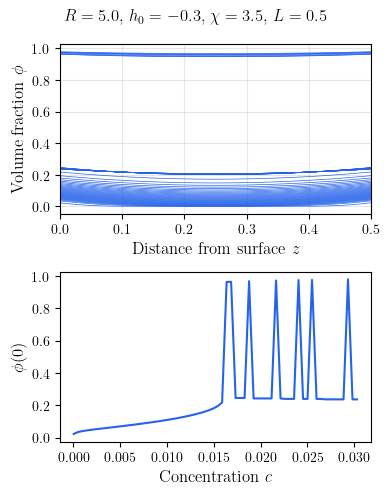

In [454]:
import json, numpy as np
import matplotlib.pyplot as plt

# path = "data/20260723/demo_bvp_profiles.json"
path = "data/20260727/demo_bvp_profiles.json"
d = json.load(open(path))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

phi_inf  = np.array(d["phi_inf"])                       # (n_phi,)
z_full   = np.array(d["z_full"])                        # (n_z,)
z_lin    = np.array(d["z_linear"])                      # (n_z,)
phi_full = np.array(d["phi_profiles_full"])             # (n_phi, n_z)
phi_lin  = np.array(d["phi_profiles_linear"])           # (n_phi, n_z)
R, omega_b = d["R"], d["omega_b"]
chi = d["chi"]
L = d["L"]
# chi = 4

fig, ax = plt.subplots(2, 1, figsize=(4, 5))
k = 0
ax[0].plot(z_full, phi_full.T, color="#2563EB", lw=0.5)
ax[0].set_xlabel(r"Distance from surface $z$", fontsize=12)
ax[0].set_ylabel(r"Volume fraction $\phi$", fontsize=12)
ax[0].set_xlim(0, max(z_full)); 
ax[0].grid(alpha=0.3)

phi_surf = phi_full.T[0,:]
# ax[1].plot(phi_inf, np.gradient(np.gradient(phi_surf, phi_inf), phi_inf), color="#2563EB")  # curvature
# ax[1].axhline(0, lw=1, color="black", alpha=0.4)
ax[1].plot(phi_inf, phi_surf, color="#2563EB")
# ax[1].set_ylim(-5000, 5000)
ax[1].set_xlabel(r"Concentration $c$", fontsize=12)
ax[1].set_ylabel(r"$\phi(0)$", fontsize=12)

fig.suptitle(rf"$R={R}$, $h_0={omega_b}$, $\chi = {chi}$, $L={L}$")
fig.tight_layout()
print(phi_inf[k])